# **단안 CCTV 상자 치수 추정 — ablation 노트북 (최종본)**

크기를 **레일 기하(계산) · 점유율 B(STEP 1) · 형태비 d/w · h/w(STEP 2)** 로 나누고, 한 번에 하나씩 바꿔 가며 최종 모델(**DA3 + DINOv3 토큰**)에 이르는 과정을 재현한다. 모든 비교는 **train(영상 단위 5-fold OOF) · val**만 쓴다. **test 채점과 런타임 측정은 메인 노트북**(`[최최최종]치수추정_메인_최종모델_test.ipynb`)에서 최종 모델로 한 번만 한다.

| 단계 | 질문 | 바꾼 것 | val ② (train) | 셀 |
| --- | --- | --- | --- | --- |
| 0 | 기존 방법은? | OVMono3D-LIFT 원본 · 레일 보정 · 치수 헤드 미세조정 | 7.68 · 7.12 · 3.72 cm | [H-1] · [H-2] |
| 1 | 크기를 나누면? | 레일 기하 + STEP 1 (ResNet18) · STEP 2-A (ConvNeXt), 대표 프레임 1장 | 2.48 (2.21) | [A-1] · [C-1] · [E-1] |
| 2 | 가려짐 대응은? | STEP 1을 가려짐 적은 8장 평균 | 2.45 (2.22) · w 1.66 → 1.32 | [B-1] ~ [B-3] · [E-1] · [E-2] |
| 3 | 깊이를 주면? | DA3 깊이 **맵**을 4번째 채널로 (2-B) | 2.44 (2.22) | [2B-*] |
| 4 | 자기지도 표현은? | CNN + 고정 DINOv3 7 × 7 토큰 (2-C) | 2.15 (1.95) | [2C-0] ~ [2C-7] |
| 5 | CNN이 필요한가? | CNN 제거 → DINOv3 단독 | 2.10 (1.93) | [2C-8] · [2C-9] |
| 6 | 두 단계 모두 · 여러 시점으로? | STEP 1도 토큰 head, STEP 2도 8장 학습 | 2.01 (1.87) | [T-1] · [2C-10] ~ [2C-12] |
| **7** | **깊이 모델의 내부 표현은?** | **DA3 인코더 토큰 + DINOv3 토큰 결합 (최종)** | **1.95 (1.80)** | **[2C-13] · [2C-13b]** |
| 8 | 학습 방식을 바꾸면? | 두 head 결합 학습 (분해 정답 없이 · 결합 항 추가 · w 고정 후 비율만) | 개선 없음 (판정 기준 미달) | [2C-14a] ~ [2C-14c] |

- **판정 규칙 (모든 단계 공통, 실험 전에 고정):** train · val 모두 ② cm가 기준보다 0.03 cm(seed 흔들림) 넘게 낮을 때만 교체, 아니면 더 단순한 쪽 유지. 유의성은 영상 단위 paired bootstrap 95% CI (2,000회).
- **지표:** ① 가로 w 오차 · ② 매칭 쌍 치수 오차 (세 변 정렬 후 같은 순위끼리) · ③ ② + 미검출 · 정답 없는 트랙 벌점.
- **실행:** 런타임 > 모두 실행 (GPU). 가중치(`CKPT2`) · 토큰 · crop · 깊이 · LIFT 특징 캐시가 있으면 학습과 추출을 건너뛴다.
- **이 노트북에서 뺀 것** (이전 노트북에 남아 있음): 2-D(LIFT 표현 + 비율 헤드), Ridge 사전 확인, 2-C의 DINOv3 크기 S · B, STEP 1 + DINOv3 추가(G), 공동 head(E9b), 14 × 14 · attention(E10), 옛 선정 표(Z), 시각화(V-1), 런타임 측정(R-1 · R-2 → 메인 노트북), LIFT 미세조정의 test 채점(→ 메인 노트북)

# **0. 설정 · 공용 도구 · 데이터**

In [1]:
# [S-1] Drive 마운트 + 경로 + 한글 폰트 (폰트 설치가 실패해도 계속 진행)
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, json, pickle, time, math, random, shutil, subprocess, urllib.request, socket

ROOT        = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인'
PROJECT_DIR = f'{ROOT}/BoxSizing'
DATA_DIR    = f'{ROOT}/Dataset/Final Dataset'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
CACHE_DIR   = f'{PROJECT_DIR}/cache'                     # 트래킹 + 레일 캐시 (이미 있음)
OUT_DIR     = f'{PROJECT_DIR}/outputs/step1'             # fold 분할 · OOF 저장소
OUT2_DIR    = f'{PROJECT_DIR}/outputs/step2'             # 제안 방법 예측 CSV (OVMono3D 노트북이 읽음)
LOCAL_DATA  = '/content/data'
MAPPING_XLSX = {sp: f'{PROJECT_DIR}/{sp}_label_mapping.xlsx' for sp in ('train', 'val', 'test')}
for d in (OUT_DIR, OUT2_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

RUN_TEST = False                                         # 이 노트북은 test를 쓰지 않는다 (test 채점은 메인 노트북에서 한 번)
SPLITS = ['train', 'val']
ABL_DIR = f'{OUT2_DIR}/ablation'; os.makedirs(ABL_DIR, exist_ok=True)   # 이 노트북의 예측 파일 (메인 노트북 파일을 덮어쓰지 않음)


def video_path(sp, vid):
    p = f'{LOCAL_DATA}/{sp}/{vid}.mp4'
    return p if os.path.exists(p) else f'{DATA_DIR}/{sp}/{vid}.mp4'


# ---- 한글 폰트: Drive 캐시 → GitHub(10초) → apt(60초), 모두 실패해도 셀은 멈추지 않음 ----
import matplotlib.font_manager as fm, matplotlib.pyplot as plt
FONT = f'{PROJECT_DIR}/fonts/NanumGothic.ttf'
if not os.path.exists(FONT):
    os.makedirs(os.path.dirname(FONT), exist_ok=True)
    try:
        socket.setdefaulttimeout(10)
        urllib.request.urlretrieve('https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', FONT)
    except Exception as e:
        print('GitHub 폰트 다운로드 실패 → apt 시도:', type(e).__name__)
        subprocess.run('timeout 60 apt-get -qq -o Acquire::http::Timeout=10 install -y fonts-nanum > /dev/null 2>&1', shell=True)
        if os.path.exists('/usr/share/fonts/truetype/nanum/NanumGothic.ttf'):
            shutil.copy('/usr/share/fonts/truetype/nanum/NanumGothic.ttf', FONT)
    finally:
        socket.setdefaulttimeout(None)
if os.path.exists(FONT) and os.path.getsize(FONT) > 100_000:
    fm.fontManager.addfont(FONT); plt.rcParams['font.family'] = fm.FontProperties(fname=FONT).get_name()
else:
    print('⚠️ 한글 폰트 없음 → 그래프의 한글이 네모로 보일 수 있음 (결과에는 영향 없음)')
plt.rcParams['axes.unicode_minus'] = False
print('SPLITS =', SPLITS)

Mounted at /content/drive
SPLITS = ['train', 'val']


In [2]:
# [S-2] 패키지 (timm은 Colab 기본 포함, 없을 때만 설치) + GPU 확인
try:
    import timm
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True); import timm
print('timm', timm.__version__)
!nvidia-smi --query-gpu=name,memory.total --format=csv

timm 1.0.31
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


In [3]:
# [S-3] 영상 로컬 복사 (crop을 새로 만들 때만 영상을 읽음, Drive에서 직접 읽으면 느림)
for sp in SPLITS:
    os.makedirs(f'{LOCAL_DATA}/{sp}', exist_ok=True)
    subprocess.run(['rsync', '-a', f'{DATA_DIR}/{sp}/', f'{LOCAL_DATA}/{sp}/'], check=True)
    print(sp, len(glob.glob(f'{LOCAL_DATA}/{sp}/*.mp4')), '개 영상')

train 100 개 영상
val 49 개 영상


In [4]:
# [L-1] 장면 상수 · 레일 기하 · 라벨 / 매핑 / 캐시 로더 · (트랙, 정답) 표 · 기하 특징
import numpy as np, pandas as pd, cv2

RAIL_WIDTH_CM, SENSOR_W_MM, FRAME_W, FRAME_H = 62.3, 5.79, 1280, 720
BEST_ALPHA = 1.0                                         # bbox 아랫변(y2)에서 픽셀당 cm를 읽음 (STEP 1 결론)
MAP_COL = 'new_tracked_unique_id_VERSION5'               # 매핑 엑셀의 트랙 번호 열


def rail_scale_at_y_vec(near_y, far_y, near_w, far_w, y):
    t = np.clip((near_y - y) / np.maximum(near_y - far_y, 1e-6), 0.0, 1.15)
    return RAIL_WIDTH_CM / np.maximum(near_w + (far_w - near_w) * t, 1.0)


def vanish_y_of(q):
    ny, fy = q['near_y'], q['fy']; denom = fy - ny
    aL, aR = (q['fl'] - q['nl']) / denom, (q['fr'] - q['nr']) / denom
    y_lines = ny + (q['nr'] - q['nl']) / (aL - aR) if abs(aL - aR) > 1e-9 else None
    y_width = ny - q['near_w'] * (ny - fy) / (q['near_w'] - q['far_w'] + 1e-9)
    return float(y_width) if y_lines is None else float((y_lines + y_width) / 2)


def vanish_xy(q):
    y_v = vanish_y_of(q)
    t = (q['near_y'] - y_v) / max(q['near_y'] - q['fy'], 1e-6)
    mid_n, mid_f = (q['nl'] + q['nr']) / 2, (q['fl'] + q['fr']) / 2
    return mid_n + (mid_f - mid_n) * t, y_v


def load_labels(path):
    with open(path) as f:
        videos = json.load(f)['videos']
    out = {}
    for v in videos:
        objs = sorted(v['objects'], key=lambda o: o['box_id'])
        out[v['video_id']] = {'boxes': [{'w': float(o['size_cm']['w']), 'd': float(o['size_cm']['d']),
                                         'h': float(o['size_cm']['h']), 'box_id': int(o['box_id'])} for o in objs],
                              'focal_mm': float(v['camera']['focal_length_mm'])}
    print(f'📄 {os.path.basename(path)}: 영상 {len(out)}개, 상자 {sum(len(v["boxes"]) for v in out.values())}개')
    return out


def load_mapping(path, col=MAP_COL):
    m = pd.read_excel(path); out = {}
    for vid, g in m.groupby('video_id'):
        rows = []
        for _, r in g.sort_values('box_id_json').iterrows():
            try:
                trk = int(float(r[col]))
            except (TypeError, ValueError):
                trk = None
            rows.append({'box_id': int(r['box_id_json']), 'trk': trk,
                         'removed': str(r.get('note', '')).strip().upper() == 'REMOVED'})
        out[str(vid)] = rows
    n_ok = sum(r['trk'] is not None and not r['removed'] for v in out.values() for r in v)
    print(f'🗂 {os.path.basename(path)}: 영상 {len(out)}개 → 트랙과 연결된 GT {n_ok}개')
    return out


def load_cache(d):
    recs = {}
    for p in sorted(glob.glob(f'{d}/*.pkl')):
        with open(p, 'rb') as f:
            r = pickle.load(f)
        recs[r['video_id']] = r
    return recs


def _rep(t, min_side_px=3):
    """대표 프레임 = bbox 면적 최대 (너무 작으면 None)"""
    bb = t['bbox']; k = int(((bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])).argmax())
    x1, y1, x2, y2 = bb[k]
    return None if (x2 <= x1 + min_side_px or y2 <= y1 + min_side_px) else k


def _row(split, vid, rec, lab, t, k, g, n_g):
    q = rec['quad']; x1, y1, x2, y2 = t['bbox'][k]
    return {'split': split, 'vid': vid, 'tid': int(t['tid']), 'box_id': -1 if g is None else g['box_id'],
            'mapped': g is not None, 'rep_fi': int(t['fi'][k]), 'step': rec['step'],
            'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2, 'bw': x2 - x1, 'bh': y2 - y1,
            'w_gt': np.nan if g is None else g['w'], 'd_gt': np.nan if g is None else g['d'],
            'h_gt': np.nan if g is None else g['h'], 'n_gt': n_g, 'focal_mm': lab['focal_mm'],
            'near_y': q['near_y'], 'far_y': q['far_y'], 'near_w': q['near_w'], 'far_w': q['far_w']}


def build_tables(recs, labels, split, mapping):
    """반환: (매핑 쌍 표, 모든 트랙 표). REMOVED 상자의 트랙은 모든 트랙 표에서도 제외."""
    pairs, alltrk = [], []
    for vid, rec in recs.items():
        if vid not in labels or rec['quad'] is None:
            continue
        lab, rows = labels[vid], mapping.get(vid, [])
        gt_by = {g['box_id']: g for g in lab['boxes']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['trk']: gt_by[m['box_id']] for m in rows if not m['removed'] and m['trk'] is not None}
        for t in rec['tracks']:
            tid = int(t['tid'])
            if tid in removed_trk:
                continue
            k = _rep(t)
            if k is None:
                continue
            r = _row(split, vid, rec, lab, t, k, link.get(tid), len(lab['boxes']))
            alltrk.append(r)
        for m in rows:                                       # 매핑 쌍 표 (예전과 같은 순서: 매핑 엑셀 순)
            if m['removed'] or m['trk'] is None:
                continue
            t = next((t for t in rec['tracks'] if int(t['tid']) == m['trk']), None)
            k = _rep(t) if t is not None else None
            if k is not None:
                pairs.append(_row(split, vid, rec, lab, t, k, gt_by[m['box_id']], len(lab['boxes'])))
    return pd.DataFrame(pairs), pd.DataFrame(alltrk)


def scale_at(df, y):
    return rail_scale_at_y_vec(df.near_y.values, df.far_y.values, df.near_w.values, df.far_w.values, np.asarray(y, float))


def add_features(df, recs):
    """기하 특징 (추론 때 알 수 있는 값만): 레일 방향 sin · cos, log focal, log bbox 비율, log 픽셀당 cm"""
    d = df.copy().reset_index(drop=True)
    y_ref = d.y1 + BEST_ALPHA * (d.y2 - d.y1)
    d['w_base'] = d.bw * scale_at(d, y_ref)
    d['B_gt'] = d.w_gt / d.w_base
    sin_t, cos_t = [], []
    for _, r in d.iterrows():
        rec = recs[r.split][r.vid]; xv, yv = vanish_xy(rec['quad'])
        dx, dy = xv - (r.x1 + r.x2) / 2, r.y2 - yv
        if not (np.isfinite(dx) and np.isfinite(dy)) or dy <= 1:
            dx, dy = rec['vx'], -rec['vy']
            if dy < 0: dx, dy = -dx, -dy
        n = np.hypot(dx, dy) + 1e-9; sin_t.append(dx / n); cos_t.append(dy / n)
    d['sin_t'], d['cos_t'] = sin_t, cos_t
    d['logB'] = np.log(d.B_gt)
    d['log_s'] = np.log(scale_at(d, y_ref))
    d['log_f'] = np.log(d.focal_mm)
    d['log_aspect'] = np.log(d.bw / d.bh)
    d['log_dw'], d['log_hw'] = np.log(d.d_gt / d.w_gt), np.log(d.h_gt / d.w_gt)
    return d


def sort3(a):
    return -np.sort(-np.asarray(a, float), axis=-1)

In [5]:
# [D-1] 라벨 · 캐시 · 매핑 → 매핑 쌍 표 + 모든 트랙 표, train 영상 단위 5-fold (예전 분할 파일 그대로)
LABELS = {sp: load_labels(f'{DATA_DIR}/{sp}_label.json') for sp in SPLITS}
RECS   = {sp: load_cache(f'{CACHE_DIR}/{sp}') for sp in SPLITS}
MAPS   = {sp: load_mapping(MAPPING_XLSX[sp]) for sp in SPLITS}
PAIRS, ALL = {}, {}
for sp in SPLITS:
    p, a = build_tables(RECS[sp], LABELS[sp], sp, MAPS[sp])
    PAIRS[sp], ALL[sp] = add_features(p, RECS), add_features(a, RECS)
    print(f'{sp}: 매핑 쌍 {len(PAIRS[sp])} | 모든 트랙 {len(ALL[sp])} (그중 정답 없는 트랙 {int((~ALL[sp].mapped).sum())})')
TRN = PAIRS['train']

N_FOLD, SEED = 5, 0
FOLD_CSV = f'{OUT_DIR}/step1_folds.csv'
_key = lambda d: (d.vid + '|' + d.tid.astype(str) + '|' + d.box_id.astype(str)).tolist()
if os.path.exists(FOLD_CSV):
    F = pd.read_csv(FOLD_CSV)
    assert _key(F) == _key(TRN), 'train 쌍이 예전 분할 파일과 다름 → 저장된 fold 가중치를 쓸 수 없음 (매핑 · 캐시 확인)'
    TRN['fold'] = F['fold'].values
else:                                                    # 파일이 없을 때만 새로 만듦 (이 경우 가중치도 새로 학습됨)
    from sklearn.model_selection import StratifiedGroupKFold
    TRN['fold'] = -1
    fbin = pd.cut(TRN.focal_mm, [0, 8, 15, 25, 100], labels=False)
    for k, (_, te) in enumerate(StratifiedGroupKFold(N_FOLD, shuffle=True, random_state=SEED).split(TRN, fbin, groups=TRN.vid)):
        TRN.loc[te, 'fold'] = k
    TRN[['vid', 'tid', 'box_id', 'fold']].to_csv(FOLD_CSV, index=False)
VID_FOLD = TRN.groupby('vid').fold.first().to_dict()
ALL['train']['fold'] = ALL['train'].vid.map(VID_FOLD).fillna(-1).astype(int)   # OOF: 그 영상이 빠진 fold의 모델로 예측
for sp in SPLITS:
    if sp != 'train':
        ALL[sp]['fold'] = -1                                                     # val · test: fold 모델 5개 평균
print('train fold별 영상 수:', TRN.groupby('fold').vid.nunique().to_dict())

📄 train_label.json: 영상 100개, 상자 918개
📄 val_label.json: 영상 49개, 상자 467개
🗂 train_label_mapping.xlsx: 영상 100개 → 트랙과 연결된 GT 899개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
train: 매핑 쌍 899 | 모든 트랙 910 (그중 정답 없는 트랙 11)
val: 매핑 쌍 461 | 모든 트랙 467 (그중 정답 없는 트랙 6)
train fold별 영상 수: {0: 20, 1: 20, 2: 20, 3: 19, 4: 21}


In [6]:
# [D-2] 상자 crop (대표 프레임, 여유 10%, letterbox 224) — 캐시가 있고 키가 같으면 그대로 사용
IMG, PAD = 224, 0.10


def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size, 3), np.uint8)
    oy, ox = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    out[oy:oy + r.shape[0], ox:ox + r.shape[1]] = r
    return out


def safe_npz(path):
    # 저장이 중간에 끊겨 깨진 캐시는 지우고 None (다시 만듦)
    if not os.path.exists(path):
        return None
    try:
        z = np.load(path, allow_pickle=True); z.files; return z
    except Exception as e:
        print(f'⚠️ 깨진 캐시 삭제 후 다시 만듦: {os.path.basename(path)} ({type(e).__name__})'); os.remove(path); return None


def safe_save(path, **arrays):
    # 로컬에 먼저 저장한 뒤 Drive로 옮김 → 저장 중 끊겨도 Drive에 깨진 파일이 남지 않음
    tmp = f'/content/_tmp_{os.path.basename(path)}'
    np.savez_compressed(tmp, **arrays); shutil.move(tmp, path)


def build_crops(df, tag):
    path = f'{CACHE_DIR}/step13_crops_{df.split.iloc[0]}_{tag}_{IMG}_p{int(PAD * 100)}.npz'
    keys = (df.vid + '|' + df.tid.astype(str)).values
    z = safe_npz(path)
    if z is not None:
        if len(z['keys']) == len(keys) and (z['keys'] == keys).all():
            return z['imgs']
    imgs = np.zeros((len(df), IMG, IMG, 3), np.uint8); n_fail = 0
    for (sp, vid), g in df.groupby(['split', 'vid'], sort=False):
        cap = cv2.VideoCapture(video_path(sp, vid))
        for i, r in sorted(g.iterrows(), key=lambda z: z[1].rep_fi):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(r.rep_fi) * int(r.step)); ok_, fr = cap.read()
            if not ok_:
                n_fail += 1; continue
            H, W = fr.shape[:2]; px, py = r.bw * PAD, r.bh * PAD
            c = fr[int(max(0, r.y1 - py)):int(min(H, r.y2 + py)), int(max(0, r.x1 - px)):int(min(W, r.x2 + px))]
            imgs[i] = letterbox(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
        cap.release()
    safe_save(path, imgs=imgs, keys=keys)
    print(f'💾 {os.path.basename(path)}  ({len(df)}개, 프레임 읽기 실패 {n_fail})')
    return imgs


CROPS_TRN = build_crops(TRN, 'area')                        # 학습용 (예전 캐시와 같은 파일)
ACROPS = {sp: build_crops(ALL[sp], 'alltrk') for sp in SPLITS}   # 예측용 (모든 트랙)

In [7]:
# [M-1] 모델 정의 + 공용 도구
import torch, torch.nn as nn

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STDV = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
EPOCHS, BS = 25, 32
NO_STD = {'sin_t', 'cos_t'}
CKPT13, CKPT2 = f'{CKPT_DIR}/step13', f'{CKPT_DIR}/step2'
for d in (CKPT13, CKPT2):
    os.makedirs(d, exist_ok=True)
R18, CNV2N = 'resnet18.tv_in1k', 'convnextv2_nano.fcmae_ft_in22k_in1k'
GEO, FS, T2 = ['log_f', 'sin_t', 'cos_t', 'log_aspect', 'log_s'], ['log_f', 'log_s'], ['log_dw', 'log_hw']
STEP1_CFG = dict(name='1C_r18_geo', backbone=R18, side=GEO)
STEP2_CFG = dict(name='2A_rgb_fs', backbone=CNV2N, side=FS)


class BNet(nn.Module):                                   # STEP 1: log B 하나
    def __init__(self, backbone, n_side, log_k):
        super().__init__()
        self.enc = timm.create_model(backbone, pretrained=True, num_classes=0)
        self.head = nn.Sequential(nn.Linear(self.enc.num_features + n_side, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
        nn.init.zeros_(self.head[-1].weight); nn.init.constant_(self.head[-1].bias, log_k)
    def forward(self, x, s):
        f = self.enc(x)
        return self.head(torch.cat([f, s], 1) if s.shape[1] else f).squeeze(1)


class RatioNet(nn.Module):                               # STEP 2-A: [log d/w, log h/w]
    def __init__(self, backbone, init_bias, n_side=0):
        super().__init__()
        self.enc = timm.create_model(backbone, pretrained=True, num_classes=0)
        self.head = nn.Sequential(nn.Linear(self.enc.num_features + n_side, 256), nn.GELU(), nn.Dropout(0.2),
                                  nn.Linear(256, len(init_bias)))
        nn.init.zeros_(self.head[-1].weight)
        with torch.no_grad():
            self.head[-1].bias.copy_(torch.tensor(init_bias, dtype=torch.float32))
    def forward(self, x, s):
        f = self.enc(x)
        return self.head(torch.cat([f, s], 1) if s.shape[1] else f)


def side_mats(side, tr_idx, others=()):
    """fold의 train 부분 통계로 표준화한 보조 입력. 반환: (train 전체, [others], sin_t 열 위치)"""
    if not side:
        return torch.zeros(len(TRN), 0), [torch.zeros(len(o), 0) for o in others], None
    A = TRN[side].values.astype(np.float32).copy(); Os = [o[side].values.astype(np.float32).copy() for o in others]
    for j, c in enumerate(side):
        if c in NO_STD: continue
        mu, sd = A[tr_idx, j].mean(), A[tr_idx, j].std() + 1e-6
        A[:, j] = (A[:, j] - mu) / sd
        for O in Os: O[:, j] = (O[:, j] - mu) / sd
    return torch.from_numpy(A), [torch.from_numpy(O) for O in Os], (side.index('sin_t') if 'sin_t' in side else None)


def prep(xu8):
    return (xu8.to(DEV, non_blocking=True).float() / 255 - MEAN) / STDV


def augment(x, s=None, sin_idx=None):
    """좌우반전(레일 각도 부호도 반전) + 밝기 · 대비"""
    n = x.shape[0]; flip = torch.rand(n, device=DEV) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    if s is not None and sin_idx is not None:
        s = s.clone(); s[flip, sin_idx] *= -1
    m = x.mean((1, 2, 3), keepdim=True)
    x = (x - m) * (1 + (torch.rand(n, 1, 1, 1, device=DEV) - .5) * .4) + m
    return x * (1 + (torch.rand(n, 1, 1, 1, device=DEV) - .5) * .4), s


@torch.no_grad()
def predict(model, X, S, sin_idx=None, bs=128):
    """좌우반전 TTA 평균 (STEP 1 · 2 공용)"""
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x, s = prep(X[i:i + bs]), S[i:i + bs].to(DEV); sf = s.clone()
        if sin_idx is not None: sf[:, sin_idx] *= -1
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
            p = (model(x, s) + model(x.flip(3), sf)) / 2
        out.append(p.float().cpu())
    return torch.cat(out).numpy()


def has_weights(ckpt_dir, name):
    return all(os.path.exists(f'{ckpt_dir}/{name}_fold{k}.pt') for k in range(N_FOLD))

In [8]:
# [M-2] 학습 · 예측 도구 — 트랙당 대표 프레임 1장 (처음 STEP 1 · STEP 2-A 공용, 영상 단위 5-fold)
def train_cv(cfg, step):
    name, side = cfg['name'], list(cfg['side'])
    ckpt = CKPT13 if step == 1 else CKPT2
    Xtr = torch.from_numpy(CROPS_TRN).permute(0, 3, 1, 2).contiguous()
    Y = torch.tensor(TRN.logB.values if step == 1 else TRN[T2].values, dtype=torch.float32)
    loss_fn, t0 = nn.SmoothL1Loss(beta=0.1), time.time()
    for k in range(N_FOLD):
        tr, te = np.where(TRN.fold != k)[0], np.where(TRN.fold == k)[0]
        S, _, sin_idx = side_mats(side, tr)
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = (BNet(cfg['backbone'], len(side), float(np.median(Y[tr].numpy()))) if step == 1 else
                 RatioNet(cfg['backbone'], np.median(Y[tr].numpy(), 0), len(side))).to(DEV)
        opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': 1e-4},
                                 {'params': model.head.parameters(), 'lr': 1e-3}], weight_decay=0.05)
        n_step = EPOCHS * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        scaler = torch.amp.GradScaler('cuda', enabled=DEV == 'cuda')
        for ep in range(EPOCHS):
            model.train()
            perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue                                # BatchNorm 보호
                x, s = augment(prep(Xtr[idx]), S[idx].to(DEV), sin_idx if step == 1 else None)
                with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
                    loss = loss_fn(model(x, s).float(), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        torch.save({'state': model.state_dict(), 'cfg': cfg}, f'{ckpt}/{name}_fold{k}.pt')
        print(f'  [{name}] fold{k} 저장  {time.time() - t0:.0f}s')
        del model, opt; torch.cuda.empty_cache()



def infer(df, crops, cfg, step):
    X = torch.from_numpy(crops).permute(0, 3, 1, 2).contiguous()
    ckpt = CKPT13 if step == 1 else CKPT2
    fold = df['fold'].values
    out = np.zeros((len(df),) if step == 1 else (len(df), 2))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]                     # OOF 행 + 평균 행
        if not len(rows):
            continue
        ck = torch.load(f"{ckpt}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        sub = df.iloc[rows]
        _, (S,), sin_idx = side_mats(list(cfg['side']), np.where(TRN.fold != k)[0], [sub])
        model = (BNet(cfg['backbone'], len(cfg['side']), 0.0) if step == 1 else
                 RatioNet(cfg['backbone'], np.zeros(2), len(cfg['side']))).to(DEV)
        model.load_state_dict(ck['state'])
        p = predict(model, X[rows], S, sin_idx if step == 1 else None)
        oof = fold[rows] == k
        out[rows[oof]] = p[oof]                                          # train: 그 영상이 빠진 fold의 모델
        out[rows[~oof]] += p[~oof] / N_FOLD                              # val · test: 5개 평균
        del model; torch.cuda.empty_cache()
    return out



def train_if_missing(cfg, step):
    ckpt = CKPT13 if step == 1 else CKPT2
    if has_weights(ckpt, cfg['name']):
        print(f"⏭ STEP {step} {cfg['name']}: fold 가중치 5개가 있어 학습 건너뜀")
    else:
        print(f"🏋️ STEP {step} {cfg['name']}: 학습 시작"); train_cv(cfg, step)


def hr(title):
    print('\n' + '━' * 90); print(title)


def w_err(m, col):
    # 지표 ①: 매칭 쌍의 가로 w 오차 (cm · %) + 혼잡 장면 (상자 11개 이상)의 %
    e = (m[col] - m.w_gt).abs(); pct = e / m.w_gt * 100; crowd = (m.n_gt >= 11).values
    return {'w 오차 cm': e.mean(), 'w 오차 %': pct.mean(), '혼잡 장면 w 오차 %': pct[crowd].mean()}


def dim_err(P, G):
    # 지표 ② (상자 하나씩): 세 변 큰 순 정렬 후 같은 순위끼리 → (cm 평균, % 평균)
    Gs = sort3(G); d = np.abs(sort3(P) - Gs)
    return d.mean(1).mean(), (d / Gs).mean(1).mean() * 100

# **1 · 2단계 — 크기를 셋으로 나누고, STEP 1의 가려짐에 대응**

- **1단계:** 레일 폭 62.3 cm로 픽셀당 cm를 계산하고(학습 없음), STEP 1(ResNet18 + 기하 특징 5개)이 점유율 B를, STEP 2-A(ConvNeXt V2-nano + [focal, 픽셀당 cm])가 log d/w · log h/w를 예측한다. 트랙마다 bbox 면적 최대 1장.
- **2단계:** 처음 STEP 1의 w 오차는 상자 11개 이상 장면에 몰린다([A-3]). 그래서 STEP 1을 **가려짐 적은 프레임 최대 8장**(bbox가 최대의 50% 이상 · 다른 bbox와 덜 겹치는 순 · 간격 0.2초 이상)으로 학습하고 트랙마다 평균한다.

In [9]:
# [A-1] 처음 STEP 1 — 가중치가 없으면 학습 → 모든 트랙 예측 (train OOF · val 5개 평균)
train_if_missing(STEP1_CFG, 1)

KEEP = ['split', 'vid', 'tid', 'box_id', 'mapped', 'rep_fi', 'step', 'x1', 'y1', 'x2', 'y2', 'n_gt',
        'w_base', 'w_gt', 'd_gt', 'h_gt']
BASE = {}                                                   # 트랙마다 모든 예측을 모아 두는 표 (split별)
for sp in SPLITS:
    D = ALL[sp]
    logB = infer(D, ACROPS[sp], STEP1_CFG, 1)
    BASE[sp] = D[KEEP].assign(w_old=D.w_base.values * np.exp(logB))
    print(f'{sp}: 트랙 {len(D)}개 예측 (매칭 쌍 {int(D.mapped.sum())} · 정답 없는 트랙 {int((~D.mapped).sum())})')

⏭ STEP 1 1C_r18_geo: fold 가중치 5개가 있어 학습 건너뜀


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

train: 트랙 910개 예측 (매칭 쌍 899 · 정답 없는 트랙 11)
val: 트랙 467개 예측 (매칭 쌍 461 · 정답 없는 트랙 6)


In [10]:
# [A-3] 처음 STEP 1의 오차는 어디서 오나 — 장면의 상자 수 (많을수록 가려짐이 많음)
for sp in SPLITS:
    V0 = BASE[sp][BASE[sp].mapped].copy()
    V0['w 오차 %'] = (V0.w_old - V0.w_gt).abs() / V0.w_gt * 100
    V0['장면 상자 수'] = pd.cut(V0.n_gt, [0, 5, 10, 100], labels=['2 ~ 5', '6 ~ 10', '11 ~'])
    TOP = V0['w 오차 %'] >= V0['w 오차 %'].quantile(0.8)                  # 오차 상위 20%
    g = V0.groupby('장면 상자 수', observed=False)
    T = pd.DataFrame({'상자 수': g.size(), '비율 %': 100 * g.size() / len(V0), 'w 오차 평균 %': g['w 오차 %'].mean(),
                      '오차 상위 20% 중 비율 %': 100 * TOP.groupby(V0['장면 상자 수'], observed=False).sum() / TOP.sum()})
    hr(f'▶ {sp} · 장면 상자 수별 처음 STEP 1 w 오차 (매칭 쌍 {len(V0)} · 평균 {V0["w 오차 %"].mean():.2f}%)')
    display(T.round(2)); print()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ train · 장면 상자 수별 처음 STEP 1 w 오차 (매칭 쌍 899 · 평균 4.50%)


,상자 수,비율 %,w 오차 평균 %,오차 상위 20% 중 비율 %
장면 상자 수,,,,
2 ~ 5,68,7.56,4.24,8.33
6 ~ 10,341,37.93,3.94,30.00
11 ~,490,54.51,4.92,61.67




━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ val · 장면 상자 수별 처음 STEP 1 w 오차 (매칭 쌍 461 · 평균 6.99%)


,상자 수,비율 %,w 오차 평균 %,오차 상위 20% 중 비율 %
장면 상자 수,,,,
2 ~ 5,39,8.46,4.64,10.75
6 ~ 10,181,39.26,5.09,24.73
11 ~,241,52.28,8.80,64.52


**[A-3] 읽는 법** — 상자가 많은 장면(11개 이상)에서 w 오차 %가 커지고 큰 오차가 몰리면, 원인은 **가려짐**이다. 가려진 프레임에서는 bbox가 상자의 가로를 다 담지 못해 `w_base`부터 틀어진다. 그런데 프레임마다 가리는 상자가 다르므로, **덜 가려진 여러 프레임을 함께 보면** 이 영향을 줄일 수 있다 → 개선 STEP 1.

In [11]:
# [B-1] 프레임 선택 (가려짐 기준) → 프레임 표 + crop 캐시 (매칭 트랙 · 정답 없는 트랙 따로)
K_NEW, NEAR_NEW, MIN_GAP = 8, 0.5, 2                 # 가려짐 적은 순 최대 8장 · 면적이 최대의 50% 이상 · 프레임 간격 2 이상
MODE = 'multi_occ_k8'


def occlusion(bb_self, others):
    if not len(others):
        return 0.0
    o = np.asarray(others, float)
    iw = np.clip(np.minimum(bb_self[2], o[:, 2]) - np.maximum(bb_self[0], o[:, 0]), 0, None)
    ih = np.clip(np.minimum(bb_self[3], o[:, 3]) - np.maximum(bb_self[1], o[:, 1]), 0, None)
    area = max((bb_self[2] - bb_self[0]) * (bb_self[3] - bb_self[1]), 1e-6)
    return float(min(1.0, (iw * ih).sum() / area))


def select_frames(bb, occ, k=K_NEW, near=NEAR_NEW):
    area = (bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])
    valid = (bb[:, 2] > bb[:, 0] + 3) & (bb[:, 3] > bb[:, 1] + 3)
    order = [int(i) for i in np.argsort(-area) if valid[i]]
    if not order:
        return []
    cand = sorted([i for i in order if area[i] >= near * area[order[0]]], key=lambda i: (round(occ[i], 3), -area[i]))
    sel = []
    for i in cand:
        if all(abs(i - j) >= MIN_GAP for j in sel):
            sel.append(i)
        if len(sel) == k:
            break
    return sel


def frame_table(split, mapped=True):
    # mapped=True: 수작업 매핑된 트랙 (학습 · 지표 ① ②) / False: 정답 없는 트랙 (지표 ③, REMOVED 제외)
    rows = []
    for vid, rec in RECS[split].items():
        if vid not in LABELS[split] or rec['quad'] is None:
            continue
        lab, maps = LABELS[split][vid], MAPS[split].get(vid, [])
        gt_by = {g['box_id']: g for g in lab['boxes']}
        link = {m['trk']: gt_by[m['box_id']] for m in maps if not m['removed'] and m['trk'] is not None and m['box_id'] in gt_by}
        removed_trk = {m['trk'] for m in maps if m['removed'] and m['trk'] is not None}
        at = {}                                                        # 샘플 프레임 → [(트랙, bbox)]
        for t in rec['tracks']:
            for fi, b in zip(t['fi'], t['bbox']):
                at.setdefault(int(fi), []).append((int(t['tid']), b))
        for t in rec['tracks']:
            tid = int(t['tid']); g = link.get(tid)
            if mapped and g is None:
                continue
            if not mapped and (g is not None or tid in removed_trk or _rep(t) is None):
                continue
            occ = np.array([occlusion(b, [o for t2, o in at[int(fi)] if t2 != tid]) for fi, b in zip(t['fi'], t['bbox'])])
            for j in select_frames(t['bbox'], occ):
                r = _row(split, vid, rec, lab, t, j, g, len(lab['boxes']))
                r['occ'] = occ[j]
                rows.append(r)
    return add_features(pd.DataFrame(rows), RECS) if rows else None


def build_crops_k(df, tag):
    # build_crops와 같은 crop, 키에 프레임 번호까지 포함 (한 트랙에 여러 프레임)
    path = f'{CACHE_DIR}/step13_crops_{df.split.iloc[0]}_{tag}_{IMG}_p{int(PAD * 100)}.npz'
    keys = (df.vid + '|' + df.tid.astype(str) + '|' + df.rep_fi.astype(str)).values
    z = safe_npz(path)
    if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
        return z['imgs']
    imgs = np.zeros((len(df), IMG, IMG, 3), np.uint8)
    for (sp, vid), g in df.groupby(['split', 'vid'], sort=False):
        cap = cv2.VideoCapture(video_path(sp, vid))
        for i, r in sorted(g.iterrows(), key=lambda z: z[1].rep_fi):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(r.rep_fi) * int(r.step)); ok_, fr = cap.read()
            if not ok_:
                continue
            H, W = fr.shape[:2]; px, py = r.bw * PAD, r.bh * PAD
            c = fr[int(max(0, r.y1 - py)):int(min(H, r.y2 + py)), int(max(0, r.x1 - px)):int(min(W, r.x2 + px))]
            imgs[i] = letterbox(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
        cap.release()
    safe_save(path, imgs=imgs, keys=keys)
    print(f'💾 {os.path.basename(path)}  ({len(df)}개)')
    return imgs


FR, FC = {}, {}
for sp in SPLITS:
    for part, mapped, tag in (('mapped', True, f'x{MODE}'), ('unmapped', False, f'x{MODE}_unmapped')):
        d = frame_table(sp, mapped)
        FR[(sp, part)], FC[(sp, part)] = d, (build_crops_k(d, tag) if d is not None else None)
        if d is None:
            print(f'{sp:5s} {part:8s}: 트랙 0'); continue
        n = d.groupby(['vid', 'tid']).ngroups
        print(f'{sp:5s} {part:8s}: 샘플 {len(d):5d} · 트랙 {n:4d} · 트랙당 평균 {len(d) / n:.1f}장 · 평균 가려짐 {d.occ.mean():.3f}')
    n_map = FR[(sp, 'mapped')].groupby(['vid', 'tid']).ngroups
    if n_map != len(PAIRS[sp]):
        print(f'  ⚠️ {sp}: 프레임 표의 매칭 트랙 {n_map} ≠ 매칭 쌍 {len(PAIRS[sp])} → 빠진 트랙은 처음 STEP 1 값으로 채움 ([B-2])')

train mapped  : 샘플  7127 · 트랙  899 · 트랙당 평균 7.9장 · 평균 가려짐 0.412
train unmapped: 샘플    63 · 트랙   11 · 트랙당 평균 5.7장 · 평균 가려짐 0.345
val   mapped  : 샘플  3589 · 트랙  461 · 트랙당 평균 7.8장 · 평균 가려짐 0.364
val   unmapped: 샘플    39 · 트랙    6 · 트랙당 평균 6.5장 · 평균 가려짐 0.488


In [12]:
# [B-2] 개선 STEP 1 — 영상 단위 5-fold (처음 STEP 1과 같은 fold) · 40 epoch 고정 → 모든 트랙 예측
#  - fold 가중치: CKPT13/final_k8/fold{k}.pt — 있으면 학습 건너뜀
EP_FINAL = 40
CK_DIR = f'{CKPT13}/final_k8'; os.makedirs(CK_DIR, exist_ok=True)
SIN = GEO.index('sin_t')


def make_model(log_k):
    return BNet(R18, len(GEO), log_k).to(DEV)


def side_raw(df):
    return df[GEO].values.astype(np.float32)       # [log_f, sin_t, cos_t, log_aspect, log_s]


def std_stats(A):
    mu, sd = A.mean(0), A.std(0) + 1e-6
    for j, c in enumerate(GEO):
        if c in NO_STD:
            mu[j], sd[j] = 0.0, 1.0
    return torch.tensor(mu), torch.tensor(sd)


TR = FR[('train', 'mapped')].reset_index(drop=True)
X_TR = torch.from_numpy(FC[('train', 'mapped')]).permute(0, 3, 1, 2)
FOLD_TR = TR.vid.map(VID_FOLD)
assert FOLD_TR.notna().all(), 'fold가 없는 train 영상이 있음'
FOLD_TR = FOLD_TR.astype(int).values
S_TR, Y_TR = torch.from_numpy(side_raw(TR)), torch.tensor(TR.logB.values, dtype=torch.float32)


def train_fold(k):
    path = f'{CK_DIR}/fold{k}.pt'
    if os.path.exists(path):
        ck = torch.load(path, map_location='cpu', weights_only=False)
        model = make_model(0.0); model.load_state_dict(ck['state'])
        print(f'  fold {k}: ⏭ 가중치 있음 → 학습 건너뜀'); return model, ck['mu'], ck['sd']
    idx_tr = np.where(FOLD_TR != k)[0]
    mu, sd = std_stats(side_raw(TR.iloc[idx_tr]))
    torch.manual_seed(k); rng = np.random.default_rng(k)
    model = make_model(float(np.median(TR.logB.values[idx_tr])))
    opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': 1e-4},
                             {'params': model.head.parameters(), 'lr': 1e-3}], weight_decay=0.05)
    n_step = EP_FINAL * math.ceil(len(idx_tr) / BS); warm = n_step // 20
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) * 0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
    scaler = torch.amp.GradScaler('cuda', enabled=DEV == 'cuda'); loss_fn = nn.SmoothL1Loss(beta=0.1)
    t0 = time.time()
    for ep in range(EP_FINAL):
        model.train(); perm = rng.permutation(idx_tr); tot, n = 0.0, 0
        for i in range(0, len(perm), BS):
            idx = torch.from_numpy(perm[i:i + BS])
            if len(idx) < 2:
                continue
            x, s = augment(prep(X_TR[idx]), ((S_TR[idx] - mu) / sd).to(DEV), SIN)
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
                loss = loss_fn(model(x, s).float(), Y_TR[idx].to(DEV))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(idx); n += len(idx)
        if (ep + 1) % 10 == 0:
            print(f'  fold {k}: ep {ep + 1:3d}  train loss {tot / n:.4f}  {time.time() - t0:.0f}s')
    torch.save({'state': {kk: v.detach().cpu() for kk, v in model.state_dict().items()}, 'mu': mu, 'sd': sd, 'epochs': EP_FINAL}, path)
    return model, mu, sd


def frame_logw(model, mu, sd, df, X):
    # 프레임마다 log w = log w_base (그 프레임의 bbox · 스케일) + log B
    S = (torch.from_numpy(side_raw(df)) - mu) / sd
    return np.log(df.w_base.values) + predict(model, X, S, SIN)


hr(f'▶ 개선 STEP 1 · 5-fold ({EP_FINAL} epoch 고정) — 학습 샘플 {len(TR)} · 트랙 {TR.groupby(["vid", "tid"]).ngroups}')
MODELS = [train_fold(k) for k in range(N_FOLD)]

for sp in SPLITS:
    lw_parts = []
    for part in ('mapped', 'unmapped'):
        F = FR[(sp, part)]
        if F is None:
            continue
        F = F.reset_index(drop=True)
        X = X_TR if (sp == 'train' and part == 'mapped') else torch.from_numpy(FC[(sp, part)]).permute(0, 3, 1, 2)
        fold = F.vid.map(VID_FOLD).fillna(-1).astype(int).values if sp == 'train' else np.full(len(F), -1)
        lw = np.zeros(len(F))
        for k, (model, mu, sd) in enumerate(MODELS):
            rows = np.where((fold == k) | (fold < 0))[0]                 # OOF 행 + 평균 행
            if not len(rows):
                continue
            p = frame_logw(model, mu, sd, F.iloc[rows], X[torch.from_numpy(rows)])
            oof = fold[rows] == k
            lw[rows[oof]] = p[oof]                                       # train: 그 영상이 빠진 fold의 모델
            lw[rows[~oof]] += p[~oof] / N_FOLD                           # val · test · fold 없는 영상: 5개 평균
        lw_parts.append(F[['vid', 'tid']].assign(lw=lw))
    T = pd.concat(lw_parts).groupby(['vid', 'tid'], sort=False).lw.mean().rename('lw_new').reset_index()   # 트랙마다 프레임 평균
    B = BASE[sp].drop(columns=['lw_new', 'w_new'], errors='ignore').merge(T, on=['vid', 'tid'], how='left')
    miss = B.lw_new.isna()
    B['w_new'] = np.where(miss, B.w_old, np.exp(B.lw_new))
    BASE[sp] = B
    print(f'{sp}: 개선 STEP 1 예측 트랙 {int((~miss).sum())} / {len(B)}' + (f' (프레임이 없는 {int(miss.sum())}개는 처음 STEP 1 값)' if miss.any() else ''))
del MODELS; torch.cuda.empty_cache()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 개선 STEP 1 · 5-fold (40 epoch 고정) — 학습 샘플 7127 · 트랙 899
  fold 0: ⏭ 가중치 있음 → 학습 건너뜀
  fold 1: ⏭ 가중치 있음 → 학습 건너뜀
  fold 2: ⏭ 가중치 있음 → 학습 건너뜀
  fold 3: ⏭ 가중치 있음 → 학습 건너뜀
  fold 4: ⏭ 가중치 있음 → 학습 건너뜀
train: 개선 STEP 1 예측 트랙 910 / 910
val: 개선 STEP 1 예측 트랙 467 / 467


In [13]:
# [B-3] 지표 ① — 레일 기하만 vs 처음 STEP 1 vs 개선 STEP 1 (cm · % · 혼잡 장면 %)
rows = []
for sp in SPLITS:
    m = BASE[sp][BASE[sp].mapped]
    b, o, n = w_err(m, 'w_base'), w_err(m, 'w_old'), w_err(m, 'w_new')
    key = f'{sp} ({len(m)}쌍)'
    rows += [{'split': key, '조건': '레일 기하만 (B = 1)', **b},
             {'split': key, '조건': '처음 STEP 1 (1장)', **o, '기준선 대비 감소 %': 100 * (1 - o['w 오차 cm'] / b['w 오차 cm'])},
             {'split': key, '조건': '개선 STEP 1 (최대 8장 평균)', **n, '기준선 대비 감소 %': 100 * (1 - n['w 오차 cm'] / b['w 오차 cm']),
              '처음 대비 감소 %': 100 * (1 - n['w 오차 cm'] / o['w 오차 cm'])}]
W_TAB = pd.DataFrame(rows).set_index(['split', '조건'])
hr('▶ 지표 ① · 가로 w 오차 — 레일 기하만 → 처음 STEP 1 → 개선 STEP 1 (cm · %)')
display(W_TAB.round(2)); print()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 지표 ① · 가로 w 오차 — 레일 기하만 → 처음 STEP 1 → 개선 STEP 1 (cm · %)


w 오차 cm  w 오차 %  혼잡 장면 w 오차 %  기준선 대비 감소 %  \
split        조건                                                                 
train (899쌍) 레일 기하만 (B = 1)           3.62   15.76         17.14          NaN   
             처음 STEP 1 (1장)           1.07    4.50          4.92        70.54   
             개선 STEP 1 (최대 8장 평균)     0.91    3.68          4.08        74.84   
val (461쌍)   레일 기하만 (B = 1)           3.99   16.98         19.27          NaN   
             처음 STEP 1 (1장)           1.66    6.99          8.80        58.39   
             개선 STEP 1 (최대 8장 평균)     1.32    5.43          7.51        66.91   

                                   처음 대비 감소 %  
split        조건                                
train (899쌍) 레일 기하만 (B = 1)               NaN  
             처음 STEP 1 (1장)               NaN  
             개선 STEP 1 (최대 8장 평균)       14.61  
val (461쌍)   레일 기하만 (B = 1)               NaN  
             처음 STEP 1 (1장)               NaN  
             개선 STEP 1 (최대 8장 평균)       20.49

In [14]:
# [C-1] STEP 2-A — 가중치가 없으면 학습 → 모든 트랙의 log d/w · log h/w 예측
train_if_missing(STEP2_CFG, 2)
for sp in SPLITS:
    r = infer(ALL[sp], ACROPS[sp], STEP2_CFG, 2)
    BASE[sp]['ldw'], BASE[sp]['lhw'] = r[:, 0], r[:, 1]
    print(f'{sp}: 형태비 예측 {len(r)}개')

⏭ STEP 2 2A_rgb_fs: fold 가중치 5개가 있어 학습 건너뜀


model.safetensors: reconstructing file:   0%|          |  0.00B / 62.5MB            

model.safetensors: downloading bytes:           |  0.00B            

train: 형태비 예측 910개
val: 형태비 예측 467개


In [15]:
# [E-1] 지표 ② (매칭 쌍) · ③ (+ 미검출 · 과검출 벌점) — cm · % (OVMono3D 노트북과 같은 정의 · REMOVED 양쪽 제외)
def full_errors(labels, mapping, pred, cols=('w', 'd', 'h')):
    # 반환: 매칭 쌍 · 미검출 정답 · 정답 없는 트랙 — 상자마다 (cm 오차, % 오차)
    cols = list(cols)
    pidx = pred.set_index(['vid', 'tid'])
    matched, miss, fp = [], [], []
    for vid in sorted(labels):
        rows = mapping.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
        for g in labels[vid]['boxes']:
            if g['box_id'] in removed_box:
                continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                matched.append((float(diff.mean()), float((diff / gs).mean() * 100)))
            else:
                miss.append((float(gs.mean()), 100.0))                          # 예측을 (0, 0, 0)으로 → 세 변 모두 100%
        for t in vid_trks - set(link.values()):
            p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
            fp.append((float(p.mean()), 100.0))                                  # 정답을 (0, 0, 0)으로 → 100%로 정의
    return matched, miss, fp


def as_pred(B, wcol):
    w = B[wcol].values
    return B[['vid', 'tid', 'mapped']].assign(w=w, d=w * np.exp(B.ldw.values), h=w * np.exp(B.lhw.values))


VERSIONS = {'처음 STEP 1 + 2-A': 'w_old', '개선 STEP 1 + 2-A': 'w_new'}
PRED = {sp: {name: as_pred(BASE[sp], col) for name, col in VERSIONS.items()} for sp in SPLITS}

rows = []
for sp in SPLITS:
    m = BASE[sp][BASE[sp].mapped]
    for name, col in VERSIONS.items():
        mt, ms, fp = full_errors(LABELS[sp], MAPS[sp], PRED[sp][name])
        mean = lambda L, j: float(np.mean([x[j] for x in L])) if L else np.nan
        e1 = w_err(m, col)
        rows.append({'split': sp, '조건': name, '① w cm': e1['w 오차 cm'], '① w %': e1['w 오차 %'],
                     '② cm': mean(mt, 0), '② %': mean(mt, 1), '③ cm': mean(mt + ms + fp, 0), '③ %': mean(mt + ms + fp, 1),
                     '매칭 쌍': len(mt), '미검출': len(ms), '정답 없는 트랙': len(fp)})
    o, n = rows[-2], rows[-1]
    rows.append({'split': sp, '조건': '변화 (개선 − 처음)', **{c: n[c] - o[c] for c in ('① w cm', '① w %', '② cm', '② %', '③ cm', '③ %')}})
METRICS = pd.DataFrame(rows).set_index(['split', '조건'])
hr('▶ 치수 오차 — ① 가로 w · ② 매칭 쌍 · ③ + 미검출 · 과검출 벌점 (cm · %)')
display(METRICS.round(2)); print()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 치수 오차 — ① 가로 w · ② 매칭 쌍 · ③ + 미검출 · 과검출 벌점 (cm · %)


① w cm  ① w %  ② cm    ② %  ③ cm    ③ %   매칭 쌍  미검출  \
split 조건                                                                     
train 처음 STEP 1 + 2-A    1.07   4.50  2.21  11.21  2.45  12.95  899.0  7.0   
      개선 STEP 1 + 2-A    0.91   3.68  2.22  11.15  2.45  12.89  899.0  7.0   
      변화 (개선 − 처음)      -0.16  -0.82  0.00  -0.06 -0.01  -0.06    NaN  NaN   
val   처음 STEP 1 + 2-A    1.66   6.99  2.48  12.99  2.98  15.20  461.0  6.0   
      개선 STEP 1 + 2-A    1.32   5.43  2.45  12.88  2.92  15.09  461.0  6.0   
      변화 (개선 − 처음)      -0.34  -1.56 -0.03  -0.11 -0.07  -0.11    NaN  NaN   

                       정답 없는 트랙  
split 조건                         
train 처음 STEP 1 + 2-A      11.0  
      개선 STEP 1 + 2-A      11.0  
      변화 (개선 − 처음)          NaN  
val   처음 STEP 1 + 2-A       6.0  
      개선 STEP 1 + 2-A       6.0  
      변화 (개선 − 처음)          NaN

In [16]:
# [E-2] 오차 몫 분해 (지표 ②, 매칭 쌍) — 한쪽을 정답으로 고정해 각 단계가 혼자 남기는 오차
#  - STEP 1만 틀림: w = 예측, 형태비 = 정답  → 처음 STEP 1이 전체 오차에서 차지하던 몫 (이 값의 %는 ① w %와 같음)
#  - STEP 2만 틀림: w = 정답, 형태비 = 2-A
#  - 둘 다 예측 = 지표 ②
#  - corr: 상자마다 log(w 예측 ÷ 정답)과 log(형태비 예측 ÷ 정답)의 상관 (음수면 두 오차가 서로 상쇄)
rows = []
for sp in SPLITS:
    m = BASE[sp][BASE[sp].mapped]
    wg, dg, hg = m.w_gt.values, m.d_gt.values, m.h_gt.values; G = np.c_[wg, dg, hg]
    rdw, rhw = np.exp(m.ldw.values), np.exp(m.lhw.values)
    s2_cm, s2_pct = dim_err(np.c_[wg, wg * rdw, wg * rhw], G)
    for name, col in VERSIONS.items():
        w = m[col].values
        lb_cm, lb_pct = dim_err(np.c_[w, w * dg / wg, w * hg / wg], G)
        all_cm, all_pct = dim_err(np.c_[w, w * rdw, w * rhw], G)
        ew = np.log(w / wg)
        rows.append({'split': sp, '조건': name,
                     'STEP 1만 틀림 cm': lb_cm, 'STEP 1만 틀림 %': lb_pct,
                     'STEP 2만 틀림 cm': s2_cm, 'STEP 2만 틀림 %': s2_pct,
                     '둘 다 (②) cm': all_cm, '둘 다 (②) %': all_pct,
                     'STEP 1 몫 (STEP 1만 ÷ ②) %': 100 * lb_pct / all_pct,
                     'corr(w, d/w)': np.corrcoef(ew, np.log(rdw / (dg / wg)))[0, 1],
                     'corr(w, h/w)': np.corrcoef(ew, np.log(rhw / (hg / wg)))[0, 1]})
DECOMP = pd.DataFrame(rows).set_index(['split', '조건'])
hr('▶ 오차 몫 분해 — STEP 1만 틀림 · STEP 2만 틀림 · 둘 다 (지표 ②, cm · %) · w 오차와 형태비 오차의 상관')
display(DECOMP.round(2)); print()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 오차 몫 분해 — STEP 1만 틀림 · STEP 2만 틀림 · 둘 다 (지표 ②, cm · %) · w 오차와 형태비 오차의 상관


STEP 1만 틀림 cm  STEP 1만 틀림 %  STEP 2만 틀림 cm  \
split 조건                                                            
train 처음 STEP 1 + 2-A           0.97          4.50           2.05   
      개선 STEP 1 + 2-A           0.81          3.68           2.05   
val   처음 STEP 1 + 2-A           1.36          6.99           2.38   
      개선 STEP 1 + 2-A           1.06          5.43           2.38   

                       STEP 2만 틀림 %  둘 다 (②) cm  둘 다 (②) %  \
split 조건                                                     
train 처음 STEP 1 + 2-A         10.68        2.21      11.21   
      개선 STEP 1 + 2-A         10.68        2.22      11.15   
val   처음 STEP 1 + 2-A         13.18        2.48      12.99   
      개선 STEP 1 + 2-A         13.18        2.45      12.88   

                       STEP 1 몫 (STEP 1만 ÷ ②) %  corr(w, d/w)  corr(w, h/w)  
split 조건                                                                     
train 처음 STEP 1 + 2-A                     40.13         -0.37         -0.39  
      개선 STEP 1 + 2-A                     32.98         -0.30         -0.33  
val   처음 STEP 1 + 2-A                     53.80         -0.63         -0.56  
      개선 STEP 1 + 2-A                     42.17         -0.58         -0.51

**1 · 2단계 결과**

| | 기준선 (B = 1) | 1단계 | 2단계 |
| --- | --- | --- | --- |
| ① w (val · train) | 3.99 · 3.62 cm | 1.66 · 1.07 cm | **1.32 · 0.91 cm** |
| ② (val · train) | | 2.48 · 2.21 cm | **2.45 · 2.22 cm** |

- w 오차는 20% 줄었지만 ②는 거의 그대로다. 두 단계가 bbox 가로를 w와 d가 나눠 갖는 방식을 반대 방향으로 틀려 오차가 상쇄되고 있었다 (corr(w, d/w) val −0.63).
- w를 정답으로 고정해도 형태비만으로 val 2.38 cm가 남는다 ([E-2]) → **병목은 STEP 2(형태비)**. 이후 단계는 STEP 2에 무엇을 줄지 묻는다.

# **3단계 — 깊이 맵을 주면? (STEP 2-B: RGB + DA3 깊이 1채널)**

위에서 내려다보면 두께가 잘 안 보이므로, Depth Anything 3(DA3METRIC-LARGE) 깊이 맵을 crop마다 중앙값으로 정규화해 네 번째 채널로 붙인다 (깊이 채널은 0 초기화 → 시작 = 2-A). w는 2단계 STEP 1 그대로.

In [17]:
# [F-1] STEP 2 후보 공통 채점 함수 — 형태비 예측 두 열 → ② · ③ · STEP 2만 · 짧은 변 구간 (w = 개선 STEP 1 고정)
#  - BASE(트랙별 예측 표)를 parquet으로 저장: 이후 셀들이 후보 예측 열을 추가하며 덮어씀
#  - 2-A 재현값 (val): ② 2.45 cm · 12.88% | ③ 2.92 · 15.09 | STEP 2만 2.38 · 13.18 | 짧은 변 ≤ 10 cm 18.19%
for sp in SPLITS:
    BASE[sp].to_parquet(f'{OUT2_DIR}/{sp}_base_step1new_2A.parquet')


def eval_step2(name, ldw, lhw):
    rows = []
    for sp in SPLITS:
        B = BASE[sp]; w = B.w_new.values
        pred = B[['vid', 'tid', 'mapped']].assign(w=w, d=w * np.exp(ldw[sp]), h=w * np.exp(lhw[sp]))
        mt, ms, fp = full_errors(LABELS[sp], MAPS[sp], pred)
        mean = lambda L, j: float(np.mean([x[j] for x in L]))
        m = B.mapped.values; G = B.loc[m, ['w_gt', 'd_gt', 'h_gt']].values; wg = G[:, 0]
        P = pred.loc[m, ['w', 'd', 'h']].values
        s2_cm, s2_pct = dim_err(np.c_[wg, wg * np.exp(ldw[sp][m]), wg * np.exp(lhw[sp][m])], G)
        short = G.min(1)
        bins = {'≤10': short <= 10, '10~15': (short > 10) & (short <= 15), '>15': short > 15}
        rows.append({'split': sp, '모델': name,
                     '② cm': mean(mt, 0), '② %': mean(mt, 1),
                     '③ cm': mean(mt + ms + fp, 0), '③ %': mean(mt + ms + fp, 1),
                     'STEP 2만 cm': s2_cm, 'STEP 2만 %': s2_pct,
                     **{f'② % 짧은 변 {k}': dim_err(P[b], G[b])[1] for k, b in bins.items()}})
    return pd.DataFrame(rows).set_index(['split', '모델'])


display(eval_step2('2-A', {sp: BASE[sp].ldw.values for sp in SPLITS},
                          {sp: BASE[sp].lhw.values for sp in SPLITS}).round(2))

,,② cm,② %,③ cm,③ %,STEP 2만 cm,STEP 2만 %,② % 짧은 변 ≤10,② % 짧은 변 10~15,② % 짧은 변 >15
split,모델,,,,,,,,,
train,2-A,2.22,11.15,2.45,12.89,2.05,10.68,13.98,10.70,9.87
val,2-A,2.45,12.88,2.92,15.09,2.38,13.18,18.19,12.49,10.38


In [18]:
# [2B-0] DA3 설치 + DA3METRIC-LARGE 로드 (0.35 B, Apache 2.0)
#  - DA3 pyproject는 Python ≤ 3.13 · numpy<2 · open3d 등을 요구 → Colab(Python 3.13, numpy 2)에서 그대로 설치하면 실패
#  - 그래서 패키지만 --no-deps로 설치하고, 단안 깊이 추론에 실제로 필요한 가벼운 의존성만 따로 설치
#  - export · 자세 정렬용 라이브러리(moviepy · pycolmap · evo)는 api.py가 import만 하고 단안 깊이에는 안 씀
#    → 없으면 빈 모듈로 대체 (Colab 환경의 numpy · torch를 건드리지 않기 위해)
import importlib, types
DA3_DIR = f'{CACHE_DIR}/da3_rep'
DA3_DONE = all(os.path.exists(f'{DA3_DIR}/{sp}/{v}.npz')
               for sp in SPLITS for v in pd.concat([PAIRS[sp], ALL[sp]]).vid.unique())
if DA3_DONE:
    print('⏭ DA3 깊이 캐시가 모두 있음 → DA3 설치 · 로드 건너뜀')
else:
    try:
        import depth_anything_3  # noqa
    except ImportError:
        !pip install -q --no-deps --ignore-requires-python git+https://github.com/ByteDance-Seed/Depth-Anything-3.git
        !pip install -q addict einops omegaconf safetensors imageio trimesh plyfile

    def _stub(*names):
        class _Dummy:
            def __init__(self, *a, **k):
                raise RuntimeError('DA3 export/자세 정렬 기능은 이 환경에서 쓰지 않음')
        for n in names:
            try:
                importlib.import_module(n)
            except Exception:
                parts = n.split('.')
                for i in range(1, len(parts) + 1):
                    key = '.'.join(parts[:i])
                    if key not in sys.modules:
                        m = types.ModuleType(key); m.__getattr__ = lambda a, _D=_Dummy: _D
                        sys.modules[key] = m
                print(f'ℹ️ {n}: 없음 → 빈 모듈로 대체 (단안 깊이 추론에는 쓰이지 않음)')

    _stub('moviepy.editor', 'pycolmap', 'evo.core.trajectory')
    from depth_anything_3.api import DepthAnything3

    DA3 = DepthAnything3.from_pretrained('depth-anything/DA3METRIC-LARGE').to(DEV).eval()
    N_PARAMS_DA3 = sum(p.numel() for p in DA3.parameters())
    print(f'DA3METRIC-LARGE: {N_PARAMS_DA3 / 1e6:.1f}M | numpy {np.__version__} | torch {torch.__version__}')

    # 동작 확인: 영상 하나의 첫 프레임 → 깊이 범위가 그럴듯한지 (m)
    _sp = SPLITS[-1]; _vid = sorted(ALL[_sp].vid.unique())[0]
    _cap = cv2.VideoCapture(video_path(_sp, _vid)); _ok, _bgr = _cap.read(); _cap.release()
    _raw = np.asarray(DA3.inference([cv2.cvtColor(_bgr, cv2.COLOR_BGR2RGB)]).depth[0])
    print(f'{_vid}: DA3 출력 {_raw.shape}, 원시값 범위 {_raw.min():.3f} ~ {_raw.max():.3f}')

⏭ DA3 깊이 캐시가 모두 있음 → DA3 설치 · 로드 건너뜀


In [19]:
# [2B-1] 대표 프레임 전체 깊이 캐시 (미터, 640×360 float16) — 2-B와 2-D(DA3)가 같이 씀
#  - 대표 프레임 = rep_fi × step (STEP 노트북 crop, LIFT 노트북 plan_rep_frames와 같은 프레임)
#  - 한 장씩 추론: 여러 장을 한 번에 넣으면 DA3가 multi-view로 처리함
#  - 미터 변환 (README): metric = focal_px × net_output / 300, focal은 DA3 처리 해상도 기준으로 환산
#  - 영상마다 파일 1개, 있으면 건너뜀 → 끊겨도 이어서 실행 가능
#  - load_da3: 캐시 읽기 함수 ([2B-2] · [2B-3] · [2D-2]에서도 사용)
DA3_DIR = f'{CACHE_DIR}/da3_rep'


def load_da3(sp, vid):
    z = np.load(f'{DA3_DIR}/{sp}/{vid}.npz')
    return dict(zip(z['frames'].tolist(), z['depth']))


DH, DW = FRAME_H // 2, FRAME_W // 2
DA3_TIMES = []


@torch.no_grad()
def da3_metric(rgb, f_px):
    raw = np.asarray(DA3.inference([rgb]).depth[0], np.float32)      # (h', w') 처리 해상도
    f_proc = f_px * raw.shape[1] / FRAME_W
    z = f_proc * raw / 300.0
    return cv2.resize(z, (DW, DH), interpolation=cv2.INTER_LINEAR).astype(np.float16)


def cache_da3(sp):
    os.makedirs(f'{DA3_DIR}/{sp}', exist_ok=True)
    D = pd.concat([PAIRS[sp], ALL[sp]])
    vids = sorted(D.vid.unique()); t_all = time.time()
    for i, vid in enumerate(vids):
        path = f'{DA3_DIR}/{sp}/{vid}.npz'
        if safe_npz(path) is not None:
            continue
        g = D[D.vid == vid]
        frames = sorted(set((g.rep_fi * g.step).astype(int)))
        f_px = LABELS[sp][vid]['focal_mm'] * FRAME_W / SENSOR_W_MM
        cap = cv2.VideoCapture(video_path(sp, vid)); out = []
        for fr in frames:
            cap.set(cv2.CAP_PROP_POS_FRAMES, fr); ok_, bgr = cap.read()
            if not ok_:
                print(f'  ⚠️ {vid} 프레임 {fr} 읽기 실패'); out.append(np.zeros((DH, DW), np.float16)); continue
            torch.cuda.synchronize(); t0 = time.perf_counter()
            out.append(da3_metric(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), f_px))
            torch.cuda.synchronize(); DA3_TIMES.append(time.perf_counter() - t0)
        cap.release()
        safe_save(path, frames=np.array(frames), depth=np.stack(out))
        if (i + 1) % 10 == 0:
            print(f'[{sp} {i + 1}/{len(vids)}] 누적 {(time.time() - t_all) / 60:.1f}분')
    print(f'{sp}: 깊이 캐시 {len(glob.glob(f"{DA3_DIR}/{sp}/*.npz"))} / {len(vids)}')


if not DA3_DONE:
    for sp in SPLITS:
        cache_da3(sp)
else:
    print('⏭ DA3 깊이 캐시 있음')
if DA3_TIMES:
    print(f'DA3 프레임당 {1000 * np.median(DA3_TIMES):.0f} ms (중앙값, 전처리 포함)')

⏭ DA3 깊이 캐시 있음


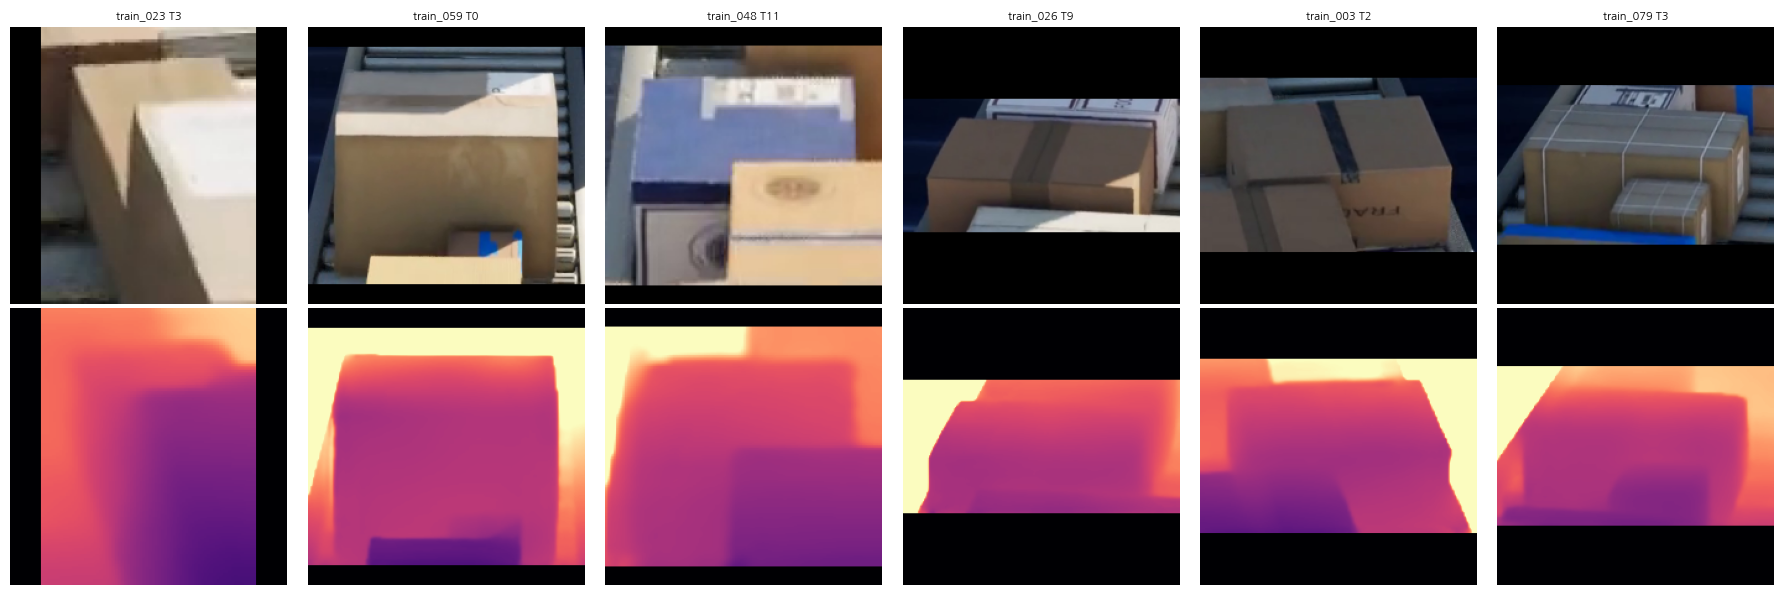

In [20]:
# [2B-3] 깊이 crop — RGB crop([D-2])과 똑같은 창 (여유 10%, letterbox 224), Z ÷ median(bbox 안 깊이)
#  - letterbox 여백은 0 (RGB 여백이 검은색인 것과 같음)
if 'DA3' in globals():
    del DA3; torch.cuda.empty_cache()                              # 학습 전에 GPU 메모리 확보


def build_dcrops(df, tag):
    path = f'{CACHE_DIR}/step2b_dcrops_{df.split.iloc[0]}_{tag}_{IMG}_p{int(PAD * 100)}.npz'
    keys = (df.vid + '|' + df.tid.astype(str)).values
    z = safe_npz(path)
    if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
        return z['z']
    out = np.zeros((len(df), IMG, IMG), np.float16); n_bad = 0
    for (sp, vid), g in df.groupby(['split', 'vid'], sort=False):
        Zs = load_da3(sp, vid)
        for i, r in g.iterrows():
            Zf = cv2.resize(Zs[int(r.rep_fi) * int(r.step)].astype(np.float32), (FRAME_W, FRAME_H),
                            interpolation=cv2.INTER_LINEAR)              # 원본 좌표로 되돌려 RGB와 같은 창을 씀
            px, py = r.bw * PAD, r.bh * PAD
            c = Zf[int(max(0, r.y1 - py)):int(min(FRAME_H, r.y2 + py)), int(max(0, r.x1 - px)):int(min(FRAME_W, r.x2 + px))]
            box = Zf[int(r.y1):int(r.y2), int(r.x1):int(r.x2)]
            med = float(np.median(box[box > 0])) if (box > 0).any() else 0.0
            if med <= 0 or c.size == 0:
                n_bad += 1; continue
            h, w = c.shape; s = IMG / max(h, w)
            th, tw = max(1, round(h * s)), max(1, round(w * s))
            oy, ox = (IMG - th) // 2, (IMG - tw) // 2
            out[i, oy:oy + th, ox:ox + tw] = cv2.resize(c / med, (tw, th), interpolation=cv2.INTER_AREA)
    safe_save(path, z=out, keys=keys)
    print(f'💾 {os.path.basename(path)}  ({len(df)}개, 깊이 없음 {n_bad})')
    return out


DCROPS_TRN = build_dcrops(TRN, 'area')
DCROPS = {sp: build_dcrops(ALL[sp], 'alltrk') for sp in SPLITS}

# 눈으로 확인: RGB crop과 깊이 crop이 같은 위치인지 (윗면이 가깝게 = 어둡게 보여야 함)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for j, i in enumerate(np.random.default_rng(0).choice(len(TRN), 6, replace=False)):
    ax[0, j].imshow(CROPS_TRN[i]); ax[0, j].set_title(f'{TRN.vid[i]} T{TRN.tid[i]}', fontsize=8)
    ax[1, j].imshow(DCROPS_TRN[i].astype(np.float32), cmap='magma', vmin=0.8, vmax=1.2)
    for a in ax[:, j]: a.axis('off')
plt.tight_layout(); plt.show()

In [21]:
# [2B-4] 4채널 모델 · 학습 · 예측 — 2-A와 다른 점은 입력 채널 하나뿐
#  - 첫 conv: RGB 자리는 원래 가중치, 깊이 채널은 0 → 학습 시작 = 2-A와 같음
#  - 증강: 좌우반전은 4채널 함께, 밝기 · 대비는 RGB에만
#  - 나머지(백본 · 보조 입력 · 손실 · 옵티마이저 · 25 epoch · seed · fold · TTA)는 2-A와 동일
#  - fold마다 저장 → 끊겨도 다시 실행하면 남은 fold만 학습
STEP2B_CFG = dict(name='2B_rgbz_fs', backbone=CNV2N, side=FS)


class RatioNet4(RatioNet):
    def __init__(self, backbone, init_bias, n_side=0):
        super().__init__(backbone, init_bias, n_side)
        old = self.enc.stem[0]
        assert isinstance(old, nn.Conv2d) and old.in_channels == 3, type(old)
        new = nn.Conv2d(4, old.out_channels, old.kernel_size, old.stride, old.padding, bias=old.bias is not None)
        with torch.no_grad():
            new.weight.zero_(); new.weight[:, :3] = old.weight
            if old.bias is not None:
                new.bias.copy_(old.bias)
        self.enc.stem[0] = new


def prep4(xu8, z):
    return torch.cat([prep(xu8), z.to(DEV, non_blocking=True).float()], 1)


def augment4(x):
    n = x.shape[0]; flip = torch.rand(n, device=DEV) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    rgb, z = x[:, :3], x[:, 3:]
    m = rgb.mean((1, 2, 3), keepdim=True)
    rgb = (rgb - m) * (1 + (torch.rand(n, 1, 1, 1, device=DEV) - .5) * .4) + m
    rgb = rgb * (1 + (torch.rand(n, 1, 1, 1, device=DEV) - .5) * .4)
    return torch.cat([rgb, z], 1)


def train_cv4(cfg, z_trn):
    name, side = cfg['name'], list(cfg['side'])
    Xtr = torch.from_numpy(CROPS_TRN).permute(0, 3, 1, 2).contiguous()
    Ztr = torch.from_numpy(z_trn).unsqueeze(1)
    Y = torch.tensor(TRN[T2].values, dtype=torch.float32)
    loss_fn, t0 = nn.SmoothL1Loss(beta=0.1), time.time()
    for k in range(N_FOLD):
        if os.path.exists(f'{CKPT2}/{name}_fold{k}.pt'):
            print(f'  [{name}] fold{k} 있음 → 건너뜀'); continue
        tr = np.where(TRN.fold != k)[0]
        S, _, _ = side_mats(side, tr)
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = RatioNet4(cfg['backbone'], np.median(Y[tr].numpy(), 0), len(side)).to(DEV)
        opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': 1e-4},
                                 {'params': model.head.parameters(), 'lr': 1e-3}], weight_decay=0.05)
        n_step = EPOCHS * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        scaler = torch.amp.GradScaler('cuda', enabled=DEV == 'cuda')
        for ep in range(EPOCHS):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                x = augment4(prep4(Xtr[idx], Ztr[idx])); s = S[idx].to(DEV)
                with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
                    loss = loss_fn(model(x, s).float(), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        torch.save({'state': model.state_dict(), 'cfg': cfg}, f'{CKPT2}/{name}_fold{k}.pt')
        print(f'  [{name}] fold{k} 저장  {time.time() - t0:.0f}s')
        del model, opt; torch.cuda.empty_cache()


@torch.no_grad()
def predict4(model, X, Z, S, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x, s = prep4(X[i:i + bs], Z[i:i + bs]), S[i:i + bs].to(DEV)
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
            p = (model(x, s) + model(x.flip(3), s)) / 2
        out.append(p.float().cpu())
    return torch.cat(out).numpy()


def infer4(df, crops, zcrops, cfg):
    X = torch.from_numpy(crops).permute(0, 3, 1, 2).contiguous()
    Z = torch.from_numpy(zcrops).unsqueeze(1)
    fold = df['fold'].values; out = np.zeros((len(df), 2))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        _, (S,), _ = side_mats(list(cfg['side']), np.where(TRN.fold != k)[0], [df.iloc[rows]])
        model = RatioNet4(cfg['backbone'], np.zeros(2), len(cfg['side'])).to(DEV)
        model.load_state_dict(ck['state'])
        p = predict4(model, X[rows], Z[rows], S)
        oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
        del model; torch.cuda.empty_cache()
    return out


train_cv4(STEP2B_CFG, DCROPS_TRN)

  [2B_rgbz_fs] fold0 있음 → 건너뜀
  [2B_rgbz_fs] fold1 있음 → 건너뜀
  [2B_rgbz_fs] fold2 있음 → 건너뜀
  [2B_rgbz_fs] fold3 있음 → 건너뜀
  [2B_rgbz_fs] fold4 있음 → 건너뜀


In [22]:
# [2B-5] 채점 — 2-A vs 2-B (w는 둘 다 개선 STEP 1), 예측 저장
for sp in SPLITS:
    r = infer4(ALL[sp], ACROPS[sp], DCROPS[sp], STEP2B_CFG)
    BASE[sp]['ldw_2B'], BASE[sp]['lhw_2B'] = r[:, 0], r[:, 1]
    BASE[sp].to_parquet(f'{OUT2_DIR}/{sp}_base_step1new_2A.parquet')       # 2-B 열이 추가된 상태로 덮어씀

col = lambda c: {sp: BASE[sp][c].values for sp in SPLITS}
T_2A = eval_step2('2-A', col('ldw'), col('lhw'))
T_2B = eval_step2('2-B', col('ldw_2B'), col('lhw_2B'))
DIFF = (T_2B.droplevel(1) - T_2A.droplevel(1)).assign(모델='2-B − 2-A').set_index('모델', append=True)
STEP2_TAB = pd.concat([T_2A, T_2B, DIFF]).sort_index(level=0, sort_remaining=False)
hr('▶ STEP 2 비교 — w = 개선 STEP 1 고정 (cm · %, 음수 = 2-B가 더 좋음)')
display(STEP2_TAB.round(2))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ STEP 2 비교 — w = 개선 STEP 1 고정 (cm · %, 음수 = 2-B가 더 좋음)


② cm    ② %  ③ cm    ③ %  STEP 2만 cm  STEP 2만 %  \
split 모델                                                           
train 2-A        2.22  11.15  2.45  12.89        2.05      10.68   
      2-B        2.22  11.05  2.45  12.80        2.06      10.63   
      2-B − 2-A  0.01  -0.10  0.01  -0.09        0.02      -0.05   
val   2-A        2.45  12.88  2.92  15.09        2.38      13.18   
      2-B        2.44  12.76  2.91  14.98        2.38      13.12   
      2-B − 2-A -0.01  -0.12 -0.01  -0.11       -0.00      -0.07   

                 ② % 짧은 변 ≤10  ② % 짧은 변 10~15  ② % 짧은 변 >15  
split 모델                                                     
train 2-A               13.98           10.70          9.87  
      2-B               13.58           10.61          9.95  
      2-B − 2-A         -0.40           -0.09          0.08  
val   2-A               18.19           12.49         10.38  
      2-B               17.74           12.38         10.44  
      2-B − 2-A         -0.45           -0.11          0.06

In [23]:
# [2B-6] 2-B 유의성 — 영상 단위 paired bootstrap (2-B − 2-A), 95% 신뢰구간
#  - boot_diff: 이후 모든 후보 비교(2-C · 2-D)에서 같은 함수로 신뢰구간을 계산
def per_box(sp, cdw, chw):
    B = BASE[sp][BASE[sp].mapped]; w = B.w_new.values
    G = sort3(B[['w_gt', 'd_gt', 'h_gt']].values)
    d = np.abs(sort3(np.c_[w, w * np.exp(B[cdw]), w * np.exp(B[chw])]) - G)
    return B.vid.values, d.mean(1), (d / G).mean(1) * 100, G[:, 2] <= 10


def boot_diff(cA, cB, n=2000, seed=0):
    # cA, cB: (ldw 열, lhw 열) 이름 쌍. 반환: split별 [② cm 차이 CI, ≤10 cm % 차이 CI]
    rng = np.random.default_rng(seed); out = {}
    for sp in SPLITS:
        v, a_cm, a_pct, flat = per_box(sp, *cA); _, b_cm, b_pct, _ = per_box(sp, *cB)
        vids = np.unique(v); idx = {u: np.where(v == u)[0] for u in vids}; res = []
        for _ in range(n):
            s = np.concatenate([idx[u] for u in rng.choice(vids, len(vids))]); f = s[flat[s]]
            res.append([(b_cm - a_cm)[s].mean(), (b_pct - a_pct)[f].mean()])
        lo, hi = np.percentile(res, [2.5, 97.5], 0)
        out[sp] = f'② cm [{lo[0]:+.3f}, {hi[0]:+.3f}] | ≤10 cm % [{lo[1]:+.2f}, {hi[1]:+.2f}]'
    return out


for sp, s in boot_diff(('ldw', 'lhw'), ('ldw_2B', 'lhw_2B')).items():
    print(f'2-B − 2-A  {sp}: {s}')

2-B − 2-A  train: ② cm [-0.043, +0.053] | ≤10 cm % [-0.98, +0.15]
2-B − 2-A  val: ② cm [-0.039, +0.022] | ≤10 cm % [-0.81, -0.12]


**3단계 결과** — 효과 없음: val ② 2.45 → 2.44 cm (95% CI [−0.04, +0.02]), train 2.22 → 2.22 cm. 납작한 상자(짧은 변 ≤ 10 cm)에서만 18.2 → 17.7%로 방향은 맞았다. 깊이 모델은 안에서 구조를 보지만 출력은 픽셀마다 거리 하나로 압축되고, 전체 프레임을 줄여 추정해 상자가 수십 픽셀로만 표현된다 (가설 → 7단계에서 내부 표현으로 확인).

# **4단계 — 자기지도 표현을 주면? (STEP 2-C: ConvNeXt + 고정 DINOv3-L 7 × 7 토큰)**

Prismatic VLM(학습 목표가 다른 두 백본은 보완된다)을 따라 같은 crop을 두 갈래로 본다: ConvNeXt V2-nano(학습) + DINOv3-L(고정, crop 448 → 28 × 28 패치 → 7 × 7 평균 pooling). 토큰은 원본 · 좌우반전 crop 각각 한 번만 캐시한다. [F-2]는 비교 표 도구.

In [24]:
# [F-2] Ridge 사전 확인 + 비교 표 도구 (2-C 사전 확인에 사용한 버전)
#  - 2-D에서는 [F-3]이 표준화 하한을 넣은 버전으로 ridge_residual을 교체한다
from sklearn.linear_model import RidgeCV
import torch.nn.functional as F

ALPHAS = np.logspace(0, 6, 13)
if 'T_2A' not in globals():
    T_2A = eval_step2('2-A', {sp: BASE[sp].ldw.values for sp in SPLITS}, {sp: BASE[sp].lhw.values for sp in SPLITS})


def ridge_residual(name, X_all):
    """X_all: {sp: (len(ALL[sp]), p)} — ALL/BASE와 같은 행 순서, 특징이 없는 행은 NaN.
    반환: (eval_step2 표, {sp: 보정값 (n, 2)}). 특징 없는 행은 보정 0 (= 2-A 그대로)."""
    A, Bt = ALL['train'], BASE['train']
    R = np.c_[A.log_dw.values - Bt.ldw.values, A.log_hw.values - Bt.lhw.values]
    has = {sp: np.isfinite(X_all[sp]).all(1) for sp in SPLITS}
    lab, fold = A.mapped.values & has['train'], A.fold.values
    corr = {sp: np.zeros((len(ALL[sp]), 2)) for sp in SPLITS}

    def fit(m):
        X = X_all['train'][m]; mu, sd = X.mean(0), X.std(0)
        sd = np.where(sd < 1e-6, 1.0, sd)                                 # 상수 특징 보호
        r = RidgeCV(alphas=ALPHAS, alpha_per_target=True).fit((X - mu) / sd, R[m])
        return (lambda Z: r.predict((Z - mu) / sd)), r.alpha_

    al = []
    for k in range(N_FOLD):                                              # train: OOF
        f, a = fit(lab & (fold != k)); al.append(a)
        rows = np.where((fold == k) & has['train'])[0]
        if len(rows): corr['train'][rows] = f(X_all['train'][rows])
    f, _ = fit(lab)                                                      # val (+ train에서 fold 없는 행): train 전체
    for sp in SPLITS:
        sel = has[sp] & ((ALL[sp].fold.values < 0) if sp == 'train' else np.ones(len(ALL[sp]), bool))
        rows = np.where(sel)[0]
        if len(rows): corr[sp][rows] = f(X_all[sp][rows])
    r2 = 1 - ((R[lab] - corr['train'][lab]) ** 2).sum(0) / ((R[lab] - R[lab].mean(0)) ** 2).sum(0)
    print(f'[{name}] train OOF R² — d/w {r2[0]:+.3f} · h/w {r2[1]:+.3f} | alpha 중앙값 {np.median(al, 0)} '
          f'| 특징 없는 행 train {int((~has["train"]).sum())} · val {int((~has["val"]).sum())}')
    tab = eval_step2(f'2-A + Ridge({name})', {sp: BASE[sp].ldw.values + corr[sp][:, 0] for sp in SPLITS},
                     {sp: BASE[sp].lhw.values + corr[sp][:, 1] for sp in SPLITS})
    return tab, corr


def compare(*tabs):
    base, out = T_2A.droplevel(1), [T_2A]
    for t in tabs:
        nm = t.index.get_level_values(1)[0]
        out += [t, (t.droplevel(1) - base).assign(모델=f'  Δ {nm}').set_index('모델', append=True)]
    return pd.concat(out).sort_index(level=0, sort_remaining=False)


ALL_TABS = {'2-B': T_2B} if 'T_2B' in globals() else {}             # 마지막 [Z-2] 요약용

In [25]:
# [2C-0] DINOv3 ViT-L/16 로드 — timm 배포본 (timm/vit_large_patch16_dinov3.lvd1689m)
#  - facebook/dinov3-* 원본 repo는 승인제(gated)라 승인 전에는 403 → 같은 가중치를 timm 형식으로 올린 공개 repo 사용
#    (라이선스는 원본과 같은 DINOv3 License, 연구 목적 사용)
#  - timm 1.0.20 이상 필요: 낮으면 업그레이드 후 "런타임 > 세션 다시 시작" → 처음부터 다시 실행 (앞부분은 캐시로 빠르게 지나감)
#  - 448 입력 → 패치 16 → 28 × 28 토큰, 정규화는 timm 설정값 그대로
DINO_NAME = 'vit_large_patch16_dinov3.lvd1689m'
TOK_RES = 448
if not timm.list_models('vit_large_patch16_dinov3*'):
    print(f'timm {timm.__version__}: DINOv3 모델 없음 → 업그레이드')
    !pip install -q -U "timm>=1.0.20"
    raise RuntimeError('timm 업그레이드 완료 → 런타임 > 세션 다시 시작 후 처음부터 다시 실행')

DINO_OK = False
try:
    DINO = timm.create_model(DINO_NAME, pretrained=True, num_classes=0, img_size=TOK_RES).to(DEV).eval()
    _dc = timm.data.resolve_model_data_config(DINO)
    DMEAN = torch.tensor(_dc['mean'], device=DEV).view(1, 3, 1, 1)
    DSTD = torch.tensor(_dc['std'], device=DEV).view(1, 3, 1, 1)
    N_PREFIX = int(DINO.num_prefix_tokens)
    PATCH = int(DINO.patch_embed.patch_size[0]); DDIM = int(DINO.num_features)
    N_PARAMS_DINO = sum(p.numel() for p in DINO.parameters())
    with torch.no_grad():                                          # 모양 확인
        _h = DINO.forward_features(torch.zeros(1, 3, TOK_RES, TOK_RES, device=DEV))
    assert _h.shape[1] == N_PREFIX + (TOK_RES // PATCH) ** 2, (_h.shape, N_PREFIX, PATCH)
    DINO_OK = True
    print(f'{DINO_NAME} (timm {timm.__version__}): {N_PARAMS_DINO / 1e6:.1f}M | patch {PATCH} · dim {DDIM} · '
          f'앞 토큰(CLS + register) {N_PREFIX} · 출력 {tuple(_h.shape)} | mean {_dc["mean"]}')
except Exception as e:
    print(f'⚠️ DINOv3 로드 실패 ({type(e).__name__}: {str(e)[:300]})')
    print('   → 이대로 계속 실행하면 2-C는 건너뛰고 2-D로 넘어감')

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

vit_large_patch16_dinov3.lvd1689m (timm 1.0.31): 303.1M | patch 16 · dim 1024 · 앞 토큰(CLS + register) 5 · 출력 (1, 789, 1024) | mean (0.485, 0.456, 0.406)


In [26]:
# [2C-1] 토큰 캐시 — 학습용(TRN) · 예측용(ALL) 각각, 원본과 좌우반전 crop 모두 (증강 · TTA용)
#  - 저장: p7 (N, 49, D) · cls (N, D) · mean (N, D), 뒤에 _f = 좌우반전, float16
DINO_TIMES = []


@torch.no_grad()
def dino_tokens(crops_u8, flip=False, bs=32):
    X = torch.from_numpy(crops_u8).permute(0, 3, 1, 2)
    g = TOK_RES // PATCH; P, C, M = [], [], []
    for i in range(0, len(X), bs):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        x = (X[i:i + bs].to(DEV).float() / 255 - DMEAN) / DSTD
        if flip: x = x.flip(3)
        x = F.interpolate(x, size=(TOK_RES, TOK_RES), mode='bilinear', align_corners=False)
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
            h = DINO.forward_features(x)
        h = h.float(); pt = h[:, N_PREFIX:]
        assert pt.shape[1] == g * g, (pt.shape, g)
        grid = pt.transpose(1, 2).reshape(len(x), DDIM, g, g).float()
        P.append(F.adaptive_avg_pool2d(grid, 7).flatten(2).transpose(1, 2).half().cpu())
        C.append(h[:, 0].half().cpu()); M.append(pt.float().mean(1).half().cpu())
        torch.cuda.synchronize(); DINO_TIMES.append((time.perf_counter() - t0) / len(x))
    return torch.cat(P).numpy(), torch.cat(C).numpy(), torch.cat(M).numpy()


def cached_tokens(crops, df, tag):
    path = f'{CACHE_DIR}/step2c_dinov3L_timm_{df.split.iloc[0]}_{tag}_{TOK_RES}.npz'
    keys = (df.vid + '|' + df.tid.astype(str)).values
    z = safe_npz(path)
    if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
        return {k: z[k] for k in z.files if k != 'keys'}
    out = {}
    for fl in (False, True):
        p, c, m = dino_tokens(crops, fl); sfx = '_f' if fl else ''
        out.update({f'p7{sfx}': p, f'cls{sfx}': c, f'mean{sfx}': m})
    safe_save(path, keys=keys, **out)
    print(f'💾 {os.path.basename(path)}  ({len(df)}개)')
    return out


if DINO_OK:
    TOK_TRN = cached_tokens(CROPS_TRN, TRN, 'area')
    TOK = {sp: cached_tokens(ACROPS[sp], ALL[sp], 'alltrk') for sp in SPLITS}
    if DINO_TIMES:
        print(f'DINOv3 crop당 {1000 * np.median(DINO_TIMES):.1f} ms (배치 32, 448 입력)')
    del DINO; torch.cuda.empty_cache()                              # 이후 학습은 캐시만 사용
else:
    print('⏭ 2-C 건너뜀 (DINOv3 없음)')

In [27]:
# [2C-3] 2-C 본 학습 — ConvNeXt V2-nano(학습) + DINOv3 토큰(고정, 캐시) → MLP
#  - 기본은 사전 확인 통과 시에만 실행하지만, 이번에는 아래 근거로 RUN_2C = True로 진행
#  - 토큰 줄기: LayerNorm → Linear(D → 64) → GELU, 7 × 7이면 49 × 64를 펼침
#  - 증강: 좌우반전 시 crop과 "좌우반전 crop의 토큰"을 함께 사용, 밝기 · 대비는 crop에만 (토큰은 고정)
#  - 그 외(보조 입력 · 손실 · 옵티마이저 · 25 epoch · seed · fold · TTA)는 2-A와 동일, fold마다 저장
RUN_2C = True        # 사전 확인: train −0.020 (기준 근소 미달) · val −0.124, 상수 보정 대조 ±0.001 → 본 실험 진행
TOK_KIND = 'p7'                                                    # 7 × 7 토큰 (평균 · CLS ablation은 [2C-6])
STEP2C_CFG = dict(name=f'2C_dinov3L_{TOK_KIND}_fs', backbone=CNV2N, side=FS, tok=TOK_KIND)


class TwoStream(nn.Module):
    def __init__(self, backbone, init_bias, n_side, n_tok, tok_dim, proj=64):
        super().__init__()
        self.enc = timm.create_model(backbone, pretrained=True, num_classes=0)
        self.proj = nn.Sequential(nn.LayerNorm(tok_dim), nn.Linear(tok_dim, proj), nn.GELU())
        self.head = nn.Sequential(nn.Linear(self.enc.num_features + n_tok * proj + n_side, 256), nn.GELU(),
                                  nn.Dropout(0.2), nn.Linear(256, len(init_bias)))
        nn.init.zeros_(self.head[-1].weight)
        with torch.no_grad():
            self.head[-1].bias.copy_(torch.tensor(init_bias, dtype=torch.float32))

    def forward(self, x, t, s):
        return self.head(torch.cat([self.enc(x), self.proj(t).flatten(1), s], 1))


def tok_tensor(d, kind, flip=False):
    a = torch.from_numpy(d[kind + ('_f' if flip else '')])
    return a if a.dim() == 3 else a.unsqueeze(1)                   # (N, 49, D) 또는 (N, 1, D)


def bright_contrast(x):
    n = x.shape[0]; m = x.mean((1, 2, 3), keepdim=True)
    x = (x - m) * (1 + (torch.rand(n, 1, 1, 1, device=DEV) - .5) * .4) + m
    return x * (1 + (torch.rand(n, 1, 1, 1, device=DEV) - .5) * .4)


def new_twostream(cfg, init_bias, d):
    t = tok_tensor(d, cfg['tok'])
    return TwoStream(cfg['backbone'], init_bias, len(cfg['side']), t.shape[1], t.shape[2]).to(DEV)


def train_cv_tok(cfg):
    name, side = cfg['name'], list(cfg['side'])
    Xtr = torch.from_numpy(CROPS_TRN).permute(0, 3, 1, 2).contiguous()
    Ttr, Tfl = tok_tensor(TOK_TRN, cfg['tok']), tok_tensor(TOK_TRN, cfg['tok'], True)
    Y = torch.tensor(TRN[T2].values, dtype=torch.float32)
    loss_fn, t0 = nn.SmoothL1Loss(beta=0.1), time.time()
    for k in range(N_FOLD):
        if os.path.exists(f'{CKPT2}/{name}_fold{k}.pt'):
            print(f'  [{name}] fold{k} 있음 → 건너뜀'); continue
        tr = np.where(TRN.fold != k)[0]
        S, _, _ = side_mats(side, tr)
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = new_twostream(cfg, np.median(Y[tr].numpy(), 0), TOK_TRN)
        rest = [p for n_, p in model.named_parameters() if not n_.startswith('enc.')]
        opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': 1e-4},
                                 {'params': rest, 'lr': 1e-3}], weight_decay=0.05)
        n_step = EPOCHS * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        scaler = torch.amp.GradScaler('cuda', enabled=DEV == 'cuda')
        for ep in range(EPOCHS):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                x = prep(Xtr[idx]); fl = torch.rand(len(idx), device=DEV) < 0.5
                x = bright_contrast(torch.where(fl[:, None, None, None], x.flip(3), x))
                t = torch.where(fl[:, None, None], Tfl[idx].to(DEV), Ttr[idx].to(DEV)).float()
                with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
                    loss = loss_fn(model(x, t, S[idx].to(DEV)).float(), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        torch.save({'state': model.state_dict(), 'cfg': cfg}, f'{CKPT2}/{name}_fold{k}.pt')
        print(f'  [{name}] fold{k} 저장  {time.time() - t0:.0f}s')
        del model, opt; torch.cuda.empty_cache()


@torch.no_grad()
def infer_tok(df, crops, d, cfg, bs=128):
    X = torch.from_numpy(crops).permute(0, 3, 1, 2).contiguous()
    T, Tf = tok_tensor(d, cfg['tok']), tok_tensor(d, cfg['tok'], True)
    fold = df['fold'].values; out = np.zeros((len(df), 2))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        _, (S,), _ = side_mats(list(cfg['side']), np.where(TRN.fold != k)[0], [df.iloc[rows]])
        model = new_twostream(cfg, np.zeros(2), d); model.load_state_dict(ck['state']); model.eval()
        p = []
        for i in range(0, len(rows), bs):
            r = rows[i:i + bs]; x, s = prep(X[r]), S[i:i + bs].to(DEV)
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
                p.append(((model(x, T[r].to(DEV).float(), s) + model(x.flip(3), Tf[r].to(DEV).float(), s)) / 2).float().cpu())
        p = torch.cat(p).numpy(); oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
        del model; torch.cuda.empty_cache()
    return out


if RUN_2C:
    train_cv_tok(STEP2C_CFG)
else:
    print('⏭ 2-C 본 학습 생략 — 사전 확인에서 DINOv3 토큰이 2-A 잔차를 설명하지 못함 (결론: 2-C 효과 없음)')

  [2C_dinov3L_p7_fs] fold0 있음 → 건너뜀
  [2C_dinov3L_p7_fs] fold1 있음 → 건너뜀
  [2C_dinov3L_p7_fs] fold2 있음 → 건너뜀
  [2C_dinov3L_p7_fs] fold3 있음 → 건너뜀
  [2C_dinov3L_p7_fs] fold4 있음 → 건너뜀


In [28]:
# [2C-4] 2-C 채점 (본 학습을 한 경우)
if RUN_2C:
    tag = STEP2C_CFG['tok']
    for sp in SPLITS:
        r = infer_tok(ALL[sp], ACROPS[sp], TOK[sp], STEP2C_CFG)
        BASE[sp][f'ldw_2C_{tag}'], BASE[sp][f'lhw_2C_{tag}'] = r[:, 0], r[:, 1]
        BASE[sp].to_parquet(f'{OUT2_DIR}/{sp}_base_step1new_2A.parquet')
    col = lambda c: {sp: BASE[sp][c].values for sp in SPLITS}
    T_2C = eval_step2(f'2-C ({tag})', col(f'ldw_2C_{tag}'), col(f'lhw_2C_{tag}'))
    ALL_TABS[f'2-C {tag}'] = T_2C
    hr('▶ 2-C vs 2-A (w = 개선 STEP 1 고정)'); display(compare(T_2C).round(2))
    for sp, s in boot_diff(('ldw', 'lhw'), (f'ldw_2C_{tag}', f'lhw_2C_{tag}')).items():
        print(f'2-C − 2-A  {sp}: {s}')


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 2-C vs 2-A (w = 개선 STEP 1 고정)


② cm    ② %  ③ cm    ③ %  STEP 2만 cm  STEP 2만 %  \
split 모델                                                              
train 2-A           2.22  11.15  2.45  12.89        2.05      10.68   
      2-C (p7)      1.95   9.65  2.19  11.42        1.76       9.04   
        Δ 2-C (p7) -0.27  -1.50 -0.26  -1.47       -0.29      -1.64   
val   2-A           2.45  12.88  2.92  15.09        2.38      13.18   
      2-C (p7)      2.15  11.32  2.63  13.57        2.08      11.69   
        Δ 2-C (p7) -0.30  -1.56 -0.29  -1.52       -0.30      -1.49   

                    ② % 짧은 변 ≤10  ② % 짧은 변 10~15  ② % 짧은 변 >15  
split 모델                                                        
train 2-A                  13.98           10.70          9.87  
      2-C (p7)             11.68            9.26          8.80  
        Δ 2-C (p7)         -2.30           -1.44         -1.07  
val   2-A                  18.19           12.49         10.38  
      2-C (p7)             16.44           11.05          8.81  
        Δ 2-C (p7)         -1.75           -1.45         -1.58

2-C − 2-A  train: ② cm [-0.341, -0.189] | ≤10 cm % [-3.15, -1.50]
2-C − 2-A  val: ② cm [-0.384, -0.224] | ≤10 cm % [-2.71, -0.68]


In [29]:
# [2C-6] 공간 ablation — DINOv3-L 토큰을 7 × 7 대신 평균 · CLS 하나로 (나머지 설정은 2-C (L, p7)와 동일)
#  - 같은 ViT-L 토큰 캐시에서 'mean' · 'cls'만 꺼내 씀 (토큰 재추출 없음)
#  - fold 가중치는 2C_dinov3L_{mean, cls}_fs_fold*.pt (p7과 이름이 달라 덮어쓰지 않음)
ABL_KINDS = ['mean', 'cls']                     # 시간을 줄이려면 ['mean']만
assert TOK_TRN['p7'].shape[-1] == 1024 and TOK['val']['p7'].shape[-1] == 1024, 'TOK가 ViT-L 토큰이 아님 → [2C-5] 끝부분 확인'

T_ABL = {}
for kind in ABL_KINDS:
    hr(f'▶ 2-C (DINOv3-L, {kind})')
    cfg_k = dict(name=f'2C_dinov3L_{kind}_fs', backbone=CNV2N, side=FS, tok=kind)
    train_cv_tok(cfg_k)
    for sp in SPLITS:
        r = infer_tok(ALL[sp], ACROPS[sp], TOK[sp], cfg_k)
        BASE[sp][f'ldw_2C_{kind}'], BASE[sp][f'lhw_2C_{kind}'] = r[:, 0], r[:, 1]
        BASE[sp].to_parquet(f'{OUT2_DIR}/{sp}_base_step1new_2A.parquet')
    col = lambda c: {sp: BASE[sp][c].values for sp in SPLITS}
    T_ABL[kind] = eval_step2(f'2-C (DINOv3-L, {kind})', col(f'ldw_2C_{kind}'), col(f'lhw_2C_{kind}'))
    ALL_TABS[f'2-C L {kind}'] = T_ABL[kind]
    for sp, s in boot_diff(('ldw', 'lhw'), (f'ldw_2C_{kind}', f'lhw_2C_{kind}')).items():
        print(f'2-C L {kind} − 2-A  {sp}: {s}')
    for sp, s in boot_diff((f'ldw_2C_{kind}', f'lhw_2C_{kind}'), ('ldw_2C_p7', 'lhw_2C_p7')).items():
        print(f'2-C L p7 − 2-C L {kind}  {sp}: {s}')          # 음수 = 7 × 7이 더 좋음

hr('▶ 공간 ablation — DINOv3-L 토큰: 7 × 7 vs 평균 vs CLS (Δ = 후보 − 2-A, 음수 = 좋아짐)')
display(compare(ALL_TABS['2-C p7'].rename(index={'2-C (p7)': '2-C (DINOv3-L, p7)'}), *T_ABL.values()).round(2))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 2-C (DINOv3-L, mean)
  [2C_dinov3L_mean_fs] fold0 있음 → 건너뜀
  [2C_dinov3L_mean_fs] fold1 있음 → 건너뜀
  [2C_dinov3L_mean_fs] fold2 있음 → 건너뜀
  [2C_dinov3L_mean_fs] fold3 있음 → 건너뜀
  [2C_dinov3L_mean_fs] fold4 있음 → 건너뜀
2-C L mean − 2-A  train: ② cm [-0.073, +0.025] | ≤10 cm % [-0.93, +0.28]
2-C L mean − 2-A  val: ② cm [-0.065, +0.024] | ≤10 cm % [-0.86, +0.48]
2-C L p7 − 2-C L mean  train: ② cm [-0.310, -0.175] | ≤10 cm % [-2.82, -1.19]
2-C L p7 − 2-C L mean  val: ② cm [-0.360, -0.203] | ≤10 cm % [-2.48, -0.61]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 2-C (DINOv3-L, cls)
  [2C_dinov3L_cls_fs] fold0 있음 → 건너뜀
  [2C_dinov3L_cls_fs] fold1 있음 → 건너뜀
  [2C_dinov3L_cls_fs] fold2 있음 → 건너뜀
  [2C_dinov3L_cls_fs] fold3 있음 → 건너뜀
  [2C_dinov3L_cls_fs] fold4 있음 → 건너뜀
2-C L cls − 2-A  train: ② cm [-0.039, +0.063] | ≤10 cm % [-1.31, -0.10]
2-C L cls − 2-A  val: ② cm

② cm    ② %  ③ cm    ③ %  STEP 2만 cm  \
split 모델                                                               
train 2-A                       2.22  11.15  2.45  12.89        2.05   
      2-C (DINOv3-L, p7)        1.95   9.65  2.19  11.42        1.76   
        Δ 2-C (DINOv3-L, p7)   -0.27  -1.50 -0.26  -1.47       -0.29   
      2-C (DINOv3-L, mean)      2.19  10.98  2.43  12.73        2.03   
        Δ 2-C (DINOv3-L, mean) -0.02  -0.17 -0.02  -0.16       -0.02   
      2-C (DINOv3-L, cls)       2.23  11.06  2.46  12.81        2.06   
        Δ 2-C (DINOv3-L, cls)   0.01  -0.09  0.02  -0.09        0.01   
val   2-A                       2.45  12.88  2.92  15.09        2.38   
      2-C (DINOv3-L, p7)        2.15  11.32  2.63  13.57        2.08   
        Δ 2-C (DINOv3-L, p7)   -0.30  -1.56 -0.29  -1.52       -0.30   
      2-C (DINOv3-L, mean)      2.43  12.74  2.90  14.95        2.35   
        Δ 2-C (DINOv3-L, mean) -0.02  -0.14 -0.02  -0.14       -0.03   
      2-C (DINOv3-L, cls)       2.41  12.62  2.88  14.84        2.35   
        Δ 2-C (DINOv3-L, cls)  -0.03  -0.26 -0.03  -0.25       -0.02   

                                STEP 2만 %  ② % 짧은 변 ≤10  ② % 짧은 변 10~15  \
split 모델                                                                  
train 2-A                           10.68         13.98           10.70   
      2-C (DINOv3-L, p7)             9.04         11.68            9.26   
        Δ 2-C (DINOv3-L, p7)        -1.64         -2.30           -1.44   
      2-C (DINOv3-L, mean)          10.55         13.68           10.63   
        Δ 2-C (DINOv3-L, mean)      -0.13         -0.30           -0.07   
      2-C (DINOv3-L, cls)           10.62         13.25           10.77   
        Δ 2-C (DINOv3-L, cls)       -0.06         -0.73            0.07   
val   2-A                           13.18         18.19           12.49   
      2-C (DINOv3-L, p7)            11.69         16.44           11.05   
        Δ 2-C (DINOv3-L, p7)        -1.49         -1.75           -1.45   
      2-C (DINOv3-L, mean)          13.06         17.99           12.41   
        Δ 2-C (DINOv3-L, mean)      -0.12         -0.20           -0.08   
      2-C (DINOv3-L, cls)           13.05         17.53           12.39   
        Δ 2-C (DINOv3-L, cls)       -0.14         -0.66           -0.10   

                                ② % 짧은 변 >15  
split 모델                                      
train 2-A                               9.87  
      2-C (DINOv3-L, p7)                8.80  
        Δ 2-C (DINOv3-L, p7)           -1.07  
      2-C (DINOv3-L, mean)              9.68  
        Δ 2-C (DINOv3-L, mean)         -0.18  
      2-C (DINOv3-L, cls)              10.01  
        Δ 2-C (DINOv3-L, cls)           0.15  
val   2-A                              10.38  
      2-C (DINOv3-L, p7)                8.81  
        Δ 2-C (DINOv3-L, p7)           -1.58  
      2-C (DINOv3-L, mean)             10.21  
        Δ 2-C (DINOv3-L, mean)         -0.17  
      2-C (DINOv3-L, cls)              10.18  
        Δ 2-C (DINOv3-L, cls)          -0.21

In [30]:
# [2C-7] 대조군: 7 × 7 토큰 위치 섞기 — 용량 · 토큰 내용은 p7과 같고 "어느 칸이 어느 위치인지"만 없앰
#  - 매 forward마다 샘플별로 49개 토큰 순서를 무작위로 섞음 (학습 · 예측 모두, 좌우반전 TTA의 두 입력도 각각 따로)
#  - 모델 구조 · 파라미터 수 · 학습 설정은 2-C (L, p7)와 완전히 동일
#  - 예측은 seed를 고정해 재현 가능하게
class TwoStreamShuf(TwoStream):
    def forward(self, x, t, s):
        idx = torch.argsort(torch.rand(t.shape[0], t.shape[1], device=t.device), dim=1)
        t = torch.gather(t, 1, idx[..., None].expand(-1, -1, t.shape[2]))
        return super().forward(x, t, s)


if '_new_twostream_orig' not in globals():
    _new_twostream_orig = new_twostream


def new_twostream(cfg, init_bias, d):
    if not cfg.get('shuffle'):
        return _new_twostream_orig(cfg, init_bias, d)
    t = tok_tensor(d, cfg['tok'])
    return TwoStreamShuf(cfg['backbone'], init_bias, len(cfg['side']), t.shape[1], t.shape[2]).to(DEV)


assert TOK_TRN['p7'].shape[-1] == 1024, 'TOK가 ViT-L 토큰이 아님'
cfg_sh = dict(name='2C_dinov3L_p7shuf_fs', backbone=CNV2N, side=FS, tok='p7', shuffle=True)
hr('▶ 2-C (DINOv3-L, p7 위치 섞기)')
train_cv_tok(cfg_sh)
for sp in SPLITS:
    torch.manual_seed(0)
    r = infer_tok(ALL[sp], ACROPS[sp], TOK[sp], cfg_sh)
    BASE[sp]['ldw_2C_p7shuf'], BASE[sp]['lhw_2C_p7shuf'] = r[:, 0], r[:, 1]
    BASE[sp].to_parquet(f'{OUT2_DIR}/{sp}_base_step1new_2A.parquet')
col = lambda c: {sp: BASE[sp][c].values for sp in SPLITS}
T_SHUF = eval_step2('2-C (DINOv3-L, p7 위치 섞기)', col('ldw_2C_p7shuf'), col('lhw_2C_p7shuf'))
ALL_TABS['2-C L p7 섞기'] = T_SHUF
for sp, s in boot_diff(('ldw', 'lhw'), ('ldw_2C_p7shuf', 'lhw_2C_p7shuf')).items():
    print(f'2-C L 섞기 − 2-A  {sp}: {s}')
for sp, s in boot_diff(('ldw_2C_p7shuf', 'lhw_2C_p7shuf'), ('ldw_2C_p7', 'lhw_2C_p7')).items():
    print(f'2-C L p7 − 2-C L 섞기  {sp}: {s}')                     # 음수 = 위치 정보가 도움

hr('▶ 공간 ablation 전체 — 7 × 7 · 위치 섞기 · 평균 · CLS (Δ = 후보 − 2-A)')
display(compare(ALL_TABS['2-C p7'].rename(index={'2-C (p7)': '2-C (DINOv3-L, p7)'}),
                T_SHUF, ALL_TABS['2-C L mean'], ALL_TABS['2-C L cls']).round(2))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 2-C (DINOv3-L, p7 위치 섞기)
  [2C_dinov3L_p7shuf_fs] fold0 있음 → 건너뜀
  [2C_dinov3L_p7shuf_fs] fold1 있음 → 건너뜀
  [2C_dinov3L_p7shuf_fs] fold2 있음 → 건너뜀
  [2C_dinov3L_p7shuf_fs] fold3 있음 → 건너뜀
  [2C_dinov3L_p7shuf_fs] fold4 있음 → 건너뜀
2-C L 섞기 − 2-A  train: ② cm [-0.159, -0.042] | ≤10 cm % [-1.70, -0.04]
2-C L 섞기 − 2-A  val: ② cm [-0.163, -0.044] | ≤10 cm % [-1.53, +0.25]
2-C L p7 − 2-C L 섞기  train: ② cm [-0.229, -0.108] | ≤10 cm % [-2.36, -0.58]
2-C L p7 − 2-C L 섞기  val: ② cm [-0.254, -0.141] | ≤10 cm % [-1.99, -0.17]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 공간 ablation 전체 — 7 × 7 · 위치 섞기 · 평균 · CLS (Δ = 후보 − 2-A)


② cm    ② %  ③ cm    ③ %  STEP 2만 cm  \
split 모델                                                                   
train 2-A                           2.22  11.15  2.45  12.89        2.05   
      2-C (DINOv3-L, p7)            1.95   9.65  2.19  11.42        1.76   
        Δ 2-C (DINOv3-L, p7)       -0.27  -1.50 -0.26  -1.47       -0.29   
      2-C (DINOv3-L, p7 위치 섞기)      2.12  10.66  2.36  12.42        1.98   
        Δ 2-C (DINOv3-L, p7 위치 섞기) -0.10  -0.49 -0.09  -0.48       -0.07   
      2-C (DINOv3-L, mean)          2.19  10.98  2.43  12.73        2.03   
        Δ 2-C (DINOv3-L, mean)     -0.02  -0.17 -0.02  -0.16       -0.02   
      2-C (DINOv3-L, cls)           2.23  11.06  2.46  12.81        2.06   
        Δ 2-C (DINOv3-L, cls)       0.01  -0.09  0.02  -0.09        0.01   
val   2-A                           2.45  12.88  2.92  15.09        2.38   
      2-C (DINOv3-L, p7)            2.15  11.32  2.63  13.57        2.08   
        Δ 2-C (DINOv3-L, p7)       -0.30  -1.56 -0.29  -1.52       -0.30   
      2-C (DINOv3-L, p7 위치 섞기)      2.35  12.34  2.82  14.56        2.30   
        Δ 2-C (DINOv3-L, p7 위치 섞기) -0.10  -0.54 -0.09  -0.53       -0.08   
      2-C (DINOv3-L, mean)          2.43  12.74  2.90  14.95        2.35   
        Δ 2-C (DINOv3-L, mean)     -0.02  -0.14 -0.02  -0.14       -0.03   
      2-C (DINOv3-L, cls)           2.41  12.62  2.88  14.84        2.35   
        Δ 2-C (DINOv3-L, cls)      -0.03  -0.26 -0.03  -0.25       -0.02   

                                    STEP 2만 %  ② % 짧은 변 ≤10  ② % 짧은 변 10~15  \
split 모델                                                                      
train 2-A                               10.68         13.98           10.70   
      2-C (DINOv3-L, p7)                 9.04         11.68            9.26   
        Δ 2-C (DINOv3-L, p7)            -1.64         -2.30           -1.44   
      2-C (DINOv3-L, p7 위치 섞기)          10.32         13.12           10.44   
        Δ 2-C (DINOv3-L, p7 위치 섞기)      -0.37         -0.86           -0.26   
      2-C (DINOv3-L, mean)              10.55         13.68           10.63   
        Δ 2-C (DINOv3-L, mean)          -0.13         -0.30           -0.07   
      2-C (DINOv3-L, cls)               10.62         13.25           10.77   
        Δ 2-C (DINOv3-L, cls)           -0.06         -0.73            0.07   
val   2-A                               13.18         18.19           12.49   
      2-C (DINOv3-L, p7)                11.69         16.44           11.05   
        Δ 2-C (DINOv3-L, p7)            -1.49         -1.75           -1.45   
      2-C (DINOv3-L, p7 위치 섞기)          12.80         17.52           12.21   
        Δ 2-C (DINOv3-L, p7 위치 섞기)      -0.38         -0.67           -0.28   
      2-C (DINOv3-L, mean)              13.06         17.99           12.41   
        Δ 2-C (DINOv3-L, mean)          -0.12         -0.20           -0.08   
      2-C (DINOv3-L, cls)               13.05         17.53           12.39   
        Δ 2-C (DINOv3-L, cls)           -0.14         -0.66           -0.10   

                                    ② % 짧은 변 >15  
split 모델                                          
train 2-A                                   9.87  
      2-C (DINOv3-L, p7)                    8.80  
        Δ 2-C (DINOv3-L, p7)               -1.07  
      2-C (DINOv3-L, p7 위치 섞기)              9.38  
        Δ 2-C (DINOv3-L, p7 위치 섞기)         -0.49  
      2-C (DINOv3-L, mean)                  9.68  
        Δ 2-C (DINOv3-L, mean)             -0.18  
      2-C (DINOv3-L, cls)                  10.01  
        Δ 2-C (DINOv3-L, cls)               0.15  
val   2-A                                  10.38  
      2-C (DINOv3-L, p7)                    8.81  
        Δ 2-C (DINOv3-L, p7)               -1.58  
      2-C (DINOv3-L, p7 위치 섞기)              9.63  
        Δ 2-C (DINOv3-L, p7 위치 섞기)         -0.75  
      2-C (DINOv3-L, mean)                 10.21  
        Δ 2-C (DINOv3-L, mean)             -0.17  
      2-C (DINOv

**4단계 결과** — 처음으로 판정 통과: val ② 2.45 → **2.15 cm** (CI [−0.38, −0.22]), train 2.22 → 1.95 cm. 세 변 · 짧은 변 구간 모두 개선.
**공간 배치가 핵심** ([2C-6] · [2C-7], 2-A 대비 val): 7 × 7 −0.30 · 위치 섞기 −0.10 · 평균 −0.02 · CLS −0.03 cm. 위치만 섞어도 효과가 1/3로 줄었다.

# **5단계 — CNN이 필요한가? (DINOv3 단독)**

2-C의 개선이 두 백본의 **결합** 때문인지 **DINOv3 토큰 자체** 때문인지 가리기 위해, ConvNeXt 줄기만 뺀 DINOv3 단독과 "2-A · 단독을 따로 학습해 평균"을 같은 조건으로 만든다. [2C-9]는 단독 모델의 근거 실험(E1 seed 반복 · E3 공간 배치 · E4 분해 없이 직접 예측).

In [31]:
# [2C-8] DINOv3 단독 (ConvNeXt 없이) — 결합의 보완성 확인 (Prismatic식 주장의 직접 검증)
#  - 2-C (L, p7)에서 길 1(ConvNeXt V2-nano)만 뺌. 토큰 줄기 · head · 학습 설정은 2-C와 같음
#  - 입력이 캐시된 토큰뿐이라 crop을 읽지 않음 → fold당 수십 초 수준
#  - fold 가중치: 2C_dinov3L_p7_tokonly_fs_fold*.pt (다른 실험과 이름이 겹치지 않음)
assert TOK_TRN['p7'].shape[-1] == 1024 and TOK['val']['p7'].shape[-1] == 1024, 'TOK가 ViT-L 토큰이 아님 → [2C-5] 끝부분 확인'


class TokOnly(nn.Module):
    """TwoStream에서 enc(ConvNeXt)만 뺀 것: 토큰 줄기 + 보조 입력 → 같은 head"""
    def __init__(self, init_bias, n_side, n_tok, tok_dim, proj=64):
        super().__init__()
        self.proj = nn.Sequential(nn.LayerNorm(tok_dim), nn.Linear(tok_dim, proj), nn.GELU())
        self.head = nn.Sequential(nn.Linear(n_tok * proj + n_side, 256), nn.GELU(),
                                  nn.Dropout(0.2), nn.Linear(256, len(init_bias)))
        nn.init.zeros_(self.head[-1].weight)
        with torch.no_grad():
            self.head[-1].bias.copy_(torch.tensor(init_bias, dtype=torch.float32))

    def forward(self, t, s):
        return self.head(torch.cat([self.proj(t).flatten(1), s], 1))


def train_cv_tokonly(cfg, d_trn):
    name, side = cfg['name'], list(cfg['side'])
    Ttr, Tfl = tok_tensor(d_trn, cfg['tok']), tok_tensor(d_trn, cfg['tok'], True)
    Y = torch.tensor(TRN[T2].values, dtype=torch.float32)
    loss_fn, t0 = nn.SmoothL1Loss(beta=0.1), time.time()
    for k in range(N_FOLD):
        path = f'{CKPT2}/{name}_fold{k}.pt'
        if os.path.exists(path):
            print(f'  [{name}] fold{k} 있음 → 건너뜀'); continue
        tr = np.where(TRN.fold != k)[0]
        S, _, _ = side_mats(side, tr)
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = TokOnly(np.median(Y[tr].numpy(), 0), len(side), Ttr.shape[1], Ttr.shape[2]).to(DEV)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)     # 2-C의 head 학습률과 같음
        n_step = EPOCHS * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        for ep in range(EPOCHS):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                fl = torch.rand(len(idx), device=DEV) < 0.5                         # 좌우반전 = 반전 crop의 토큰
                t = torch.where(fl[:, None, None], Tfl[idx].to(DEV), Ttr[idx].to(DEV)).float()
                loss = loss_fn(model(t, S[idx].to(DEV)), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        torch.save({'state': model.state_dict(), 'cfg': cfg}, path)
        print(f'  [{name}] fold{k} 저장  {time.time() - t0:.0f}s')
        del model, opt


@torch.no_grad()
def infer_tokonly(df, d, cfg, bs=256):
    T, Tf = tok_tensor(d, cfg['tok']), tok_tensor(d, cfg['tok'], True)
    fold = df['fold'].values; out = np.zeros((len(df), 2))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        _, (S,), _ = side_mats(list(cfg['side']), np.where(TRN.fold != k)[0], [df.iloc[rows]])
        model = TokOnly(np.zeros(2), len(cfg['side']), T.shape[1], T.shape[2]).to(DEV)
        model.load_state_dict(ck['state']); model.eval()
        p = []
        for i in range(0, len(rows), bs):
            r, s = rows[i:i + bs], S[i:i + bs].to(DEV)
            p.append(((model(T[r].to(DEV).float(), s) + model(Tf[r].to(DEV).float(), s)) / 2).cpu())   # 좌우반전 TTA
        p = torch.cat(p).numpy(); oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
    return out


# ── 학습 · 예측 ─────────────────────────────────────────────────────────────
cfg_to = dict(name='2C_dinov3L_p7_tokonly_fs', side=FS, tok='p7')
hr('▶ DINOv3-L 단독 (p7, ConvNeXt 없음)')
train_cv_tokonly(cfg_to, TOK_TRN)
for sp in SPLITS:
    r = infer_tokonly(ALL[sp], TOK[sp], cfg_to)
    B = BASE[sp]
    B['ldw_tok'], B['lhw_tok'] = r[:, 0], r[:, 1]
    B['ldw_ens'], B['lhw_ens'] = (B.ldw + B.ldw_tok) / 2, (B.lhw + B.lhw_tok) / 2   # 2-A · 단독 예측 평균
    B.to_parquet(f'{OUT2_DIR}/{sp}_base_step1new_2A.parquet')

col = lambda c: {sp: BASE[sp][c].values for sp in SPLITS}
T_TOK = eval_step2('DINOv3-L 단독 (p7)', col('ldw_tok'), col('lhw_tok'))
T_ENS = eval_step2('2-A · 단독 예측 평균', col('ldw_ens'), col('lhw_ens'))
ALL_TABS['DINOv3-L 단독 p7'], ALL_TABS['2-A · 단독 평균'] = T_TOK, T_ENS

hr('▶ [2C-8] 2-A · DINOv3 단독 · 예측 평균 · 2-C (Δ = 후보 − 2-A, 음수 = 좋아짐)')
display(compare(T_TOK, T_ENS, ALL_TABS['2-C p7'].rename(index={'2-C (p7)': '2-C (DINOv3-L, p7)'})).round(2))

# ── paired bootstrap (boot_diff(A, B) = B − A, 음수 = B가 더 좋음) ───────────
PAIRS = [('DINOv3 단독 − 2-A', ('ldw', 'lhw'), ('ldw_tok', 'lhw_tok')),
         ('2-C − DINOv3 단독', ('ldw_tok', 'lhw_tok'), ('ldw_2C_p7', 'lhw_2C_p7')),     # 핵심: ConvNeXt 줄기의 기여
         ('2-C − 예측 평균', ('ldw_ens', 'lhw_ens'), ('ldw_2C_p7', 'lhw_2C_p7')),        # 함께 학습 vs 따로 학습 후 평균
         ('예측 평균 − 2-A', ('ldw', 'lhw'), ('ldw_ens', 'lhw_ens'))]
for nm, a, b in PAIRS:
    for sp, s in boot_diff(a, b).items():
        print(f'{nm:18s} {sp:5s}: {s}')

# ── 오차 상관: 2-A와 DINOv3 단독이 같은 상자를 같은 방향으로 틀리나? ──────────
hr('▶ log 비율 오차 상관 (매칭 쌍) — 낮을수록 보완적')
for sp in SPLITS:
    A, B = ALL[sp], BASE[sp]; m = A.mapped.values
    for tgt, ca, ct in (('d/w', 'ldw', 'ldw_tok'), ('h/w', 'lhw', 'lhw_tok')):
        gt = A['log_' + tgt.replace('/', '')].values[m]
        ea, et = B[ca].values[m] - gt, B[ct].values[m] - gt
        print(f'  {sp:5s} {tgt}: corr(2-A 오차, 단독 오차) = {np.corrcoef(ea, et)[0, 1]:+.3f}')

# ── 규모 ────────────────────────────────────────────────────────────────────
_n_tok = sum(p.numel() for p in TokOnly(np.zeros(2), len(FS), 49, 1024).parameters())
print(f'\n학습 파라미터 — DINOv3 단독 STEP 2: {_n_tok / 1e6:.2f} M (2-C STEP 2: ConvNeXt V2-nano 15.6 M + 같은 크기의 토큰 줄기 · head)')

# ── 판정 (모델 선택 규칙: train · val 모두 0.03 cm 넘게 좋아야 무거운 쪽 유지) ──
_d = (ALL_TABS['2-C p7'].droplevel(1) - T_TOK.droplevel(1))['② cm']
print('\n2-C − DINOv3 단독 (② cm):', _d.round(3).to_dict())
if (_d < -0.03).all():
    print('→ 결합 효과 확인: ConvNeXt 줄기가 DINOv3 토큰에 없는 정보를 더함. 2-C 유지')
else:
    print('→ ConvNeXt 줄기의 기여가 판정 기준에 못 미침: 규칙상 DINOv3 단독이 최종 후보 → 최종 모델 교체 검토 필요')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ DINOv3-L 단독 (p7, ConvNeXt 없음)
  [2C_dinov3L_p7_tokonly_fs] fold0 있음 → 건너뜀
  [2C_dinov3L_p7_tokonly_fs] fold1 있음 → 건너뜀
  [2C_dinov3L_p7_tokonly_fs] fold2 있음 → 건너뜀
  [2C_dinov3L_p7_tokonly_fs] fold3 있음 → 건너뜀
  [2C_dinov3L_p7_tokonly_fs] fold4 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-8] 2-A · DINOv3 단독 · 예측 평균 · 2-C (Δ = 후보 − 2-A, 음수 = 좋아짐)


② cm    ② %  ③ cm    ③ %  STEP 2만 cm  STEP 2만 %  \
split 모델                                                                        
train 2-A                     2.22  11.15  2.45  12.89        2.05      10.68   
      DINOv3-L 단독 (p7)        1.93   9.63  2.17  11.40        1.73       8.97   
        Δ DINOv3-L 단독 (p7)   -0.28  -1.52 -0.28  -1.49       -0.32      -1.71   
      2-A · 단독 예측 평균          1.92   9.62  2.16  11.39        1.74       9.08   
        Δ 2-A · 단독 예측 평균     -0.29  -1.53 -0.29  -1.50       -0.31      -1.61   
      2-C (DINOv3-L, p7)      1.95   9.65  2.19  11.42        1.76       9.04   
        Δ 2-C (DINOv3-L, p7) -0.27  -1.50 -0.26  -1.47       -0.29      -1.64   
val   2-A                     2.45  12.88  2.92  15.09        2.38      13.18   
      DINOv3-L 단독 (p7)        2.10  11.15  2.57  13.40        2.00      11.37   
        Δ DINOv3-L 단독 (p7)   -0.35  -1.74 -0.34  -1.69       -0.38      -1.81   
      2-A · 단독 예측 평균          2.17  11.46  2.64  13.71        2.08      11.74   
        Δ 2-A · 단독 예측 평균     -0.28  -1.42 -0.27  -1.38       -0.30      -1.45   
      2-C (DINOv3-L, p7)      2.15  11.32  2.63  13.57        2.08      11.69   
        Δ 2-C (DINOv3-L, p7) -0.30  -1.56 -0.29  -1.52       -0.30      -1.49   

                              ② % 짧은 변 ≤10  ② % 짧은 변 10~15  ② % 짧은 변 >15  
split 모델                                                                  
train 2-A                            13.98           10.70          9.87  
      DINOv3-L 단독 (p7)               12.04            9.32          8.46  
        Δ DINOv3-L 단독 (p7)           -1.94           -1.38         -1.40  
      2-A · 단독 예측 평균                 12.08            9.19          8.53  
        Δ 2-A · 단독 예측 평균             -1.90           -1.51         -1.33  
      2-C (DINOv3-L, p7)             11.68            9.26          8.80  
        Δ 2-C (DINOv3-L, p7)         -2.30           -1.44         -1.07  
val   2-A                            18.19           12.49         10.38  
      DINOv3-L 단독 (p7)               16.94           10.78          8.35  
        Δ DINOv3-L 단독 (p7)           -1.25           -1.71         -2.03  
      2-A · 단독 예측 평균                 16.86           11.03          8.96  
        Δ 2-A · 단독 예측 평균             -1.33           -1.46         -1.42  
      2-C (DINOv3-L, p7)             16.44           11.05          8.81  
        Δ 2-C (DINOv3-L, p7)         -1.75           -1.45         -1.58

DINOv3 단독 − 2-A    train: ② cm [-0.374, -0.195] | ≤10 cm % [-3.14, -0.75]
DINOv3 단독 − 2-A    val  : ② cm [-0.451, -0.260] | ≤10 cm % [-2.33, +0.00]
2-C − DINOv3 단독    train: ② cm [-0.030, +0.069] | ≤10 cm % [-1.13, +0.43]
2-C − DINOv3 단독    val  : ② cm [+0.001, +0.103] | ≤10 cm % [-1.16, -0.03]
2-C − 예측 평균        train: ② cm [-0.020, +0.072] | ≤10 cm % [-0.95, +0.12]
2-C − 예측 평균        val  : ② cm [-0.058, +0.015] | ≤10 cm % [-0.91, +0.12]
예측 평균 − 2-A        train: ② cm [-0.340, -0.245] | ≤10 cm % [-2.49, -1.30]
예측 평균 − 2-A        val  : ② cm [-0.336, -0.228] | ≤10 cm % [-1.88, -0.71]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ log 비율 오차 상관 (매칭 쌍) — 낮을수록 보완적
  train d/w: corr(2-A 오차, 단독 오차) = +0.748
  train h/w: corr(2-A 오차, 단독 오차) = +0.746
  val   d/w: corr(2-A 오차, 단독 오차) = +0.855
  val   h/w: corr(2-A 오차, 단독 오차) = +0.887

학습 파라미터 — DINOv3 단독 STEP 2: 0.87 M (2-C STEP 2: ConvNeXt V2-nano 15.6 M + 같은 크기의 토큰 줄기 · head)

2-C − DINOv3 단독 (②

In [32]:
# [2C-9] DINOv3 단독 근거 실험 — E1 seed 반복 · E3 공간 배치 (평균 · CLS · 위치 섞기) · E4 분해 없이 직접 예측 (캐시된 토큰만 사용)
#  - fold 가중치 이름: 2C9_{실험}_fold*.pt (기존 실험과 겹치지 않음, 있으면 건너뜀)
assert TOK_TRN['p7'].shape[-1] == 1024, 'TOK가 ViT-L 토큰이 아님 → [2C-5] 끝부분 확인'
for _d in [TRN, *ALL.values()]:
    _d['log_bw'], _d['log_bh'] = np.log(_d.bw), np.log(_d.bh)              # E4용 bbox 픽셀 크기
TAB9, BOX9 = {}, {}                                                       # 요약 표 · 상자별 오차


class TokHead(nn.Module):
    """[2C-8] TokOnly와 같은 구조 + 출력 개수 · 위치 섞기 옵션"""
    def __init__(self, init_bias, n_side, n_tok, tok_dim, proj=64, shuffle=False):
        super().__init__()
        self.shuffle = shuffle
        self.proj = nn.Sequential(nn.LayerNorm(tok_dim), nn.Linear(tok_dim, proj), nn.GELU())
        self.head = nn.Sequential(nn.Linear(n_tok * proj + n_side, 256), nn.GELU(),
                                  nn.Dropout(0.2), nn.Linear(256, len(init_bias)))
        nn.init.zeros_(self.head[-1].weight)
        with torch.no_grad():
            self.head[-1].bias.copy_(torch.tensor(init_bias, dtype=torch.float32))

    def forward(self, t, s):
        if self.shuffle:                                                  # 샘플마다 토큰 순서를 무작위로
            idx = torch.argsort(torch.rand(t.shape[0], t.shape[1], device=t.device), 1)
            t = torch.gather(t, 1, idx[..., None].expand(-1, -1, t.shape[2]))
        return self.head(torch.cat([self.proj(t).flatten(1), s], 1))


def n_params(d, cfg):
    t = tok_tensor(d, cfg['tok'])
    return sum(p.numel() for p in TokHead(np.zeros(len(cfg.get('tgt', T2))), len(cfg['side']), t.shape[1], t.shape[2]).parameters())


def train_tokhead(cfg, d_trn):
    name, side, tgt = cfg['name'], list(cfg['side']), list(cfg.get('tgt', T2))
    sin_i = side.index('sin_t') if 'sin_t' in side else None
    Ttr, Tfl = tok_tensor(d_trn, cfg['tok']), tok_tensor(d_trn, cfg['tok'], True)
    Y = torch.tensor(TRN[tgt].values, dtype=torch.float32)
    loss_fn = nn.SmoothL1Loss(beta=0.1)
    for k in range(N_FOLD):
        path = f'{CKPT2}/{name}_fold{k}.pt'
        if os.path.exists(path): continue
        tr = np.where(TRN.fold != k)[0]
        seed = SEED + k + 1000 * cfg.get('seed', 0)                       # seed 0 = [2C-8]과 같음
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        if cfg.get('frac', 1) < 1:                                        # E5: fold의 train 영상 일부만
            v = np.unique(TRN.vid.values[tr])
            keep = np.random.default_rng(seed + 7).choice(v, max(2, round(len(v) * cfg['frac'])), replace=False)
            tr = tr[np.isin(TRN.vid.values[tr], keep)]
        S, _, _ = side_mats(side, tr)
        model = TokHead(np.median(Y[tr].numpy(), 0), len(side), Ttr.shape[1], Ttr.shape[2],
                        shuffle=cfg.get('shuffle', False)).to(DEV)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
        n_step = EPOCHS * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        for ep in range(EPOCHS):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                fl = torch.rand(len(idx), device=DEV) < 0.5
                t = torch.where(fl[:, None, None], Tfl[idx].to(DEV), Ttr[idx].to(DEV)).float()
                s = S[idx].to(DEV)
                if sin_i is not None:
                    s = s.clone(); s[fl, sin_i] *= -1                     # 좌우반전 → 레일 각도 부호도
                loss = loss_fn(model(t, s), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        torch.save({'state': model.state_dict(), 'cfg': cfg}, path)
        del model, opt


@torch.no_grad()
def infer_tokhead(df, d, cfg, bs=256):
    side, n_out = list(cfg['side']), len(cfg.get('tgt', T2))
    sin_i = side.index('sin_t') if 'sin_t' in side else None
    T, Tf = tok_tensor(d, cfg['tok']), tok_tensor(d, cfg['tok'], True)
    fold = df['fold'].values; out = np.zeros((len(df), n_out))
    torch.manual_seed(0)                                                  # 위치 섞기 재현용
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        _, (S,), _ = side_mats(side, np.where(TRN.fold != k)[0], [df.iloc[rows]])
        model = TokHead(np.zeros(n_out), len(side), T.shape[1], T.shape[2], shuffle=cfg.get('shuffle', False)).to(DEV)
        model.load_state_dict(ck['state']); model.eval()
        p = []
        for i in range(0, len(rows), bs):
            r, s = rows[i:i + bs], S[i:i + bs].to(DEV); sf = s.clone()
            if sin_i is not None: sf[:, sin_i] *= -1
            p.append(((model(T[r].to(DEV).float(), s) + model(Tf[r].to(DEV).float(), sf)) / 2).cpu())
        p = torch.cat(p).numpy(); oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
    return out


def eval_dims(name, W, D, H):
    """W, D, H: {sp: (n,)} cm. eval_step2와 같은 지표 (② · ③ · 짧은 변 ≤ 10 cm) + 상자별 오차 저장"""
    rows = []
    for sp in SPLITS:
        B = BASE[sp]; pred = B[['vid', 'tid', 'mapped']].assign(w=W[sp], d=D[sp], h=H[sp])
        mt, ms, fp = full_errors(LABELS[sp], MAPS[sp], pred)
        mean = lambda L, j: float(np.mean([x[j] for x in L]))
        m = B.mapped.values; G = B.loc[m, ['w_gt', 'd_gt', 'h_gt']].values; P = pred.loc[m, ['w', 'd', 'h']].values
        flat = G.min(1) <= 10
        BOX9[(name, sp)] = (B.vid.values[m], np.abs(sort3(P) - sort3(G)).mean(1))
        rows.append({'split': sp, '모델': name, '② cm': mean(mt, 0), '② %': mean(mt, 1),
                     '③ cm': mean(mt + ms + fp, 0), '② % 짧은 변 ≤10': dim_err(P[flat], G[flat])[1]})
    return pd.DataFrame(rows).set_index(['split', '모델'])


def eval_ratio(name, r):
    """r: {sp: (n, 2) log d/w, log h/w}, w = 개선 STEP 1"""
    W = {sp: BASE[sp].w_new.values for sp in SPLITS}
    return eval_dims(name, W, {sp: W[sp] * np.exp(r[sp][:, 0]) for sp in SPLITS},
                     {sp: W[sp] * np.exp(r[sp][:, 1]) for sp in SPLITS})


def boot_box(nA, nB, n=2000, seed=0):
    """같은 트랙끼리 영상 단위 paired bootstrap, B − A의 ② cm 95% CI (음수 = B가 좋음)"""
    rng, out = np.random.default_rng(seed), {}
    for sp in SPLITS:
        v, a = BOX9[(nA, sp)]; _, b = BOX9[(nB, sp)]
        vids = np.unique(v); idx = {u: np.where(v == u)[0] for u in vids}
        res = [(b - a)[np.concatenate([idx[u] for u in rng.choice(vids, len(vids))])].mean() for _ in range(n)]
        out[sp] = f'[{np.percentile(res, 2.5):+.3f}, {np.percentile(res, 97.5):+.3f}]'
    return out


def run(cfg, d_trn, d_all, kind='ratio'):
    train_tokhead(cfg, d_trn)
    r = {sp: infer_tokhead(ALL[sp], d_all[sp], cfg) for sp in SPLITS}
    if kind == 'ratio':
        t = eval_ratio(cfg['name'], r)
    else:                                                                 # 절대 치수 log w, d, h
        t = eval_dims(cfg['name'], *[{sp: np.exp(r[sp][:, j]) for sp in SPLITS} for j in range(3)])
    TAB9[cfg['name']] = t.assign(**{'학습 파라미터 (M)': n_params(d_trn, cfg) / 1e6}); return r


# ── 기준: 2-A · 2-C · 단독(seed 0)을 같은 채점 함수로 ─────────────────────────
TAB9['2-A'] = eval_ratio('2-A', {sp: BASE[sp][['ldw', 'lhw']].values for sp in SPLITS})
TAB9['2-C (L)'] = eval_ratio('2-C (L)', {sp: BASE[sp][['ldw_2C_p7', 'lhw_2C_p7']].values for sp in SPLITS})
TAB9['단독 L seed0'] = eval_ratio('단독 L seed0', {sp: BASE[sp][['ldw_tok', 'lhw_tok']].values for sp in SPLITS})
assert abs(TAB9['단독 L seed0'].loc[('val', '단독 L seed0'), '② cm'] - T_TOK.loc[('val', 'DINOv3-L 단독 (p7)'), '② cm']) < 1e-6

# ── E1. seed 반복 ─────────────────────────────────────────────────────────
hr('▶ E1. seed 반복 (DINOv3-L 단독, seed 1 ~ 4 추가)')
for s in range(1, 5):
    run(dict(name=f'2C9_L_p7_seed{s}', side=FS, tok='p7', seed=s), TOK_TRN, TOK)
SEED_NAMES = ['단독 L seed0'] + [f'2C9_L_p7_seed{s}' for s in range(1, 5)]
_sd = pd.concat([TAB9[n] for n in SEED_NAMES])['② cm'].unstack(0)
print('seed별 ② cm:\n', _sd.round(3).to_string())
print('평균 ± 표준편차:', {sp: f'{_sd[sp].mean():.3f} ± {_sd[sp].std():.3f}' for sp in SPLITS},
      '| 2-C (L):', {sp: round(float(TAB9['2-C (L)'].loc[(sp, '2-C (L)'), '② cm']), 3) for sp in SPLITS})
# seed 5개 예측 평균 (앙상블)도 함께
_ens = {sp: np.mean([infer_tokhead(ALL[sp], TOK[sp], dict(name=n, side=FS, tok='p7')) if n != '단독 L seed0'
                     else BASE[sp][['ldw_tok', 'lhw_tok']].values for n in SEED_NAMES], 0) for sp in SPLITS}
TAB9['단독 L seed 5개 평균'] = eval_ratio('단독 L seed 5개 평균', _ens)

# ── E3. 공간 ablation (DINOv3-L 단독) ─────────────────────────────────────────
hr('▶ E3. 공간 ablation — 평균 · CLS · 위치 섞기')
for kind in ('mean', 'cls'):
    run(dict(name=f'2C9_L_{kind}', side=FS, tok=kind), TOK_TRN, TOK)
run(dict(name='2C9_L_p7shuf', side=FS, tok='p7', shuffle=True), TOK_TRN, TOK)

# ── E4. 분해 없이 절대 치수 직접 예측 ─────────────────────────────────────────
hr('▶ E4. 같은 토큰 + 같은 기하 정보로 log w, d, h 직접 예측 (분해 없음)')
ABS_T = ['log_wgt', 'log_dgt', 'log_hgt']
for _d in [TRN, *ALL.values()]:
    _d['log_wgt'], _d['log_dgt'], _d['log_hgt'] = np.log(_d.w_gt), np.log(_d.d_gt), np.log(_d.h_gt)
GEO_ALL = GEO + ['log_bw', 'log_bh']                                       # 분해 방법이 쓰는 기하 정보 전부
run(dict(name='2C9_L_abs_geo', side=GEO_ALL, tok='p7', tgt=ABS_T), TOK_TRN, TOK, kind='abs')
run(dict(name='2C9_L_abs_noscale', side=[c for c in GEO_ALL if c != 'log_s'], tok='p7', tgt=ABS_T), TOK_TRN, TOK, kind='abs')

# ── 요약 ─────────────────────────────────────────────────────────────────
hr('▶ [2C-9] 요약 (w = 개선 STEP 1, E4는 w도 직접 예측)')
S9 = pd.concat(TAB9.values()).reset_index().pivot_table(index='모델', columns='split',
        values=['② cm', '② %', '③ cm', '② % 짧은 변 ≤10'], sort=False)
S9.columns = [f'{sp} {m}' for m, sp in S9.columns]
S9 = S9[[c for sp in SPLITS for c in S9.columns if c.startswith(sp)]]
S9['학습 파라미터 (M)'] = [float(TAB9[n]['학습 파라미터 (M)'].iloc[0]) if '학습 파라미터 (M)' in TAB9[n] else np.nan for n in S9.index]
print(S9.round(3).to_string())

hr('▶ paired bootstrap (② cm, B − A, 음수 = B가 좋음)')
for a, b in [('2-C (L)', '단독 L seed 5개 평균'), ('단독 L seed0', '2C9_L_p7shuf'), ('단독 L seed0', '2C9_L_mean'),
             ('단독 L seed0', '2C9_L_cls'), ('단독 L seed0', '2C9_L_abs_geo'), ('단독 L seed0', '2C9_L_abs_noscale')]:
    print(f'  {b:22s} − {a:22s}', boot_box(a, b))



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E1. seed 반복 (DINOv3-L 단독, seed 1 ~ 4 추가)
seed별 ② cm:
 split           train    val
모델                          
2C9_L_p7_seed1  1.927  2.080
2C9_L_p7_seed2  1.898  2.082
2C9_L_p7_seed3  1.933  2.118
2C9_L_p7_seed4  1.930  2.103
단독 L seed0      1.930  2.097
평균 ± 표준편차: {'train': '1.924 ± 0.015', 'val': '2.096 ± 0.016'} | 2-C (L): {'train': 1.95, 'val': 2.148}

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E3. 공간 ablation — 평균 · CLS · 위치 섞기

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E4. 같은 토큰 + 같은 기하 정보로 log w, d, h 직접 예측 (분해 없음)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-9] 요약 (w = 개선 STEP 1, E4는 w도 직접 예측)
                   train ② cm  train ② %  train ③ cm  train ② % 짧은 변 ≤10  val ② cm  val ② %  val ③ cm  val ② % 짧은 변 ≤10  학습 파라미터 (M)
모델      

**5단계 결과** — CNN 불필요.
- DINOv3 단독 val **2.10 cm** (train 1.93) vs 2-C 2.15 (1.95). seed 5개 평균 2.096 ± 0.016로 모두 2-C보다 좋음. 따로 학습 평균 2.17 cm.
- 2-A와 단독의 오차 상관 +0.75 ~ +0.89 → CNN이 배운 정보는 이미 토큰 안에 있음. STEP 2 학습 파라미터 16.5 M → **0.87 M**.
- **E3 공간 배치 (단독):** 7 × 7 2.10 · 위치 섞기 2.26 · 평균 2.65 · CLS 3.00 cm.
- **E4 분해의 필요성:** 같은 토큰 · 같은 기하 정보로 절대 치수를 직접 예측하면 2.76 cm (레일 스케일도 빼면 2.99).

# **6단계 — 두 단계 모두 토큰 head, 여러 시점으로 학습**

고정 토큰 + 작은 head로 충분하므로 STEP 1(ResNet18)도 토큰 head로 바꾸고(E9a), STEP 1에서 효과가 있던 가려짐 적은 8장을 STEP 2 학습에도 쓴다(E8). E7은 DINOv2-L로 바꾼 대조, E8b는 "1장 학습 + 추론만 8장 평균". [T-1]은 [B-1] 프레임 crop의 DINOv3 토큰 캐시. [2C-11]은 프레임 수 K × seed 3개, [2C-12]는 학습량을 맞춘 1장 대조.

In [33]:
# [T-1] 여러 프레임 DINOv3-L 토큰 캐시 — [B-1]에서 고른 프레임 crop의 7 × 7 토큰 (원본 · 좌우반전), 6 · 7단계 공용
#  - 샘플: train 매칭 7,127 · 정답 없음 63, val 매칭 3,589 · 정답 없음 39 (crop은 [B-1] 캐시 그대로)
#  - 토큰은 p7만 저장 (float16, train 약 1.4 GB · val 약 0.7 GB) → 다음 세션부터는 캐시에서 읽음
import torch.nn.functional as F

DTAG = 'L'
DINO_NAME1 = {'L': 'vit_large_patch16_dinov3.lvd1689m', 'S': 'vit_small_patch16_dinov3.lvd1689m'}[DTAG]


def cached_tokens_frames(crops, df, sp, part):
    path = f'{CACHE_DIR}/step1d_dinov3{DTAG}_{sp}_{part}_{TOK_RES}.npz'
    keys = (df.vid + '|' + df.tid.astype(str) + '|' + df.rep_fi.astype(str)).values
    z = safe_npz(path)
    if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
        return {'p7': z['p7'], 'p7_f': z['p7_f']}
    if 'DINO' not in globals():
        raise RuntimeError('DINO 없음')
    out = {}
    for fl in (False, True):
        p, _, _ = dino_tokens(crops, fl); out['p7_f' if fl else 'p7'] = p
    safe_save(path, keys=keys, **out)
    print(f'💾 {os.path.basename(path)}  ({len(df)}개)')
    return out


need = any(safe_npz(f'{CACHE_DIR}/step1d_dinov3{DTAG}_{sp}_{part}_{TOK_RES}.npz') is None
           for sp in SPLITS for part in ('mapped', 'unmapped') if FR[(sp, part)] is not None)
if need:
    DINO = timm.create_model(DINO_NAME1, pretrained=True, num_classes=0, img_size=TOK_RES).to(DEV).eval()
    _dc = timm.data.resolve_model_data_config(DINO)
    DMEAN = torch.tensor(_dc['mean'], device=DEV).view(1, 3, 1, 1)
    DSTD = torch.tensor(_dc['std'], device=DEV).view(1, 3, 1, 1)
    N_PREFIX = int(DINO.num_prefix_tokens); PATCH = int(DINO.patch_embed.patch_size[0]); DDIM = int(DINO.num_features)
    print(f'{DINO_NAME1}: dim {DDIM} · 앞 토큰 {N_PREFIX}')
    DINO_TIMES.clear()

TOK1 = {}
for sp in SPLITS:
    for part in ('mapped', 'unmapped'):
        Fd = FR[(sp, part)]
        if Fd is None:
            continue
        TOK1[(sp, part)] = cached_tokens_frames(FC[(sp, part)], Fd.reset_index(drop=True), sp, part)
        print(f'{sp:5s} {part:8s}: 토큰 {TOK1[(sp, part)]["p7"].shape}')
if 'DINO' in globals():
    del DINO; torch.cuda.empty_cache()

train mapped  : 토큰 (7127, 49, 1024)
train unmapped: 토큰 (63, 49, 1024)
val   mapped  : 토큰 (3589, 49, 1024)
val   unmapped: 토큰 (39, 49, 1024)


In [34]:
# [2C-10] 6단계 — E0 재현 · E7 DINOv2 · E8 STEP 2 여러 프레임 · E8b 추론만 여러 프레임 · E9a STEP 1 토큰 head (판정 규칙은 위 설명 셀에 고정)
#  - fold 가중치: CKPT2/2C10_{실험}_fold*.pt (있으면 학습 건너뜀) · 토큰 캐시: CACHE_DIR/step2c10_*.npz
#  - 실험 채점은 train · val만 (EXP). test는 최종 모델 하나만 따로 채점
import torch.nn.functional as F
EXP = [sp for sp in SPLITS if sp != 'test']
TAB10, BOX10, PRED10 = {}, {}, {}
ON_GPU = DEV == 'cuda'


# ═══ 1. 모델 · 학습 도구 (행 단위 표 + 토큰이면 무엇이든: 대표 1장 / 여러 프레임) ═══════════════
class TokHead2(nn.Module):
    """pool='flat': LayerNorm → Linear(D → proj) → GELU → 펼침 ([2C-8]과 같음)
       pool='attn': LayerNorm → Linear(D → 128) + 학습형 위치 임베딩 → 학습형 query 16개의 cross-attention → 펼침"""
    def __init__(self, init_bias, n_side, n_tok, tok_dim, proj=64, pool='flat', n_q=16, d_att=128):
        super().__init__()
        self.pool = pool
        if pool == 'flat':
            self.proj = nn.Sequential(nn.LayerNorm(tok_dim), nn.Linear(tok_dim, proj), nn.GELU()); n_in = n_tok * proj
        else:
            self.inp = nn.Sequential(nn.LayerNorm(tok_dim), nn.Linear(tok_dim, d_att))
            self.pos = nn.Parameter(torch.randn(1, n_tok, d_att) * 0.02)
            self.q = nn.Parameter(torch.randn(1, n_q, d_att) * 0.02)
            self.att = nn.MultiheadAttention(d_att, 4, batch_first=True)
            self.ln = nn.LayerNorm(d_att); n_in = n_q * d_att
        self.head = nn.Sequential(nn.Linear(n_in + n_side, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, len(init_bias)))
        nn.init.zeros_(self.head[-1].weight)
        with torch.no_grad():
            self.head[-1].bias.copy_(torch.tensor(init_bias, dtype=torch.float32))

    def forward(self, t, s):
        if self.pool == 'flat':
            z = self.proj(t).flatten(1)
        else:
            k = self.inp(t) + self.pos
            z, _ = self.att(self.q.expand(len(t), -1, -1), k, k); z = self.ln(z).flatten(1)
        return self.head(torch.cat([z, s], 1))


def _make(cfg, init_bias, n_side, T):
    return TokHead2(init_bias, n_side, T.shape[1], T.shape[2], proj=cfg.get('proj', 64), pool=cfg.get('pool', 'flat')).to(DEV)


def _std(df, side, rows):
    A = df[side].values.astype(np.float32); mu, sd = A[rows].mean(0), A[rows].std(0) + 1e-6
    for j, c in enumerate(side):
        if c in NO_STD: mu[j], sd[j] = 0.0, 1.0
    return mu, sd


def _dev(x):
    return x.to(DEV) if ON_GPU else x


def train_gen(cfg, df, T, Tf, fold):
    """df: 학습 행 표 (train 매칭), T/Tf: (N, n, D) 원본 · 좌우반전 토큰, fold: 행마다 fold 번호"""
    name, side, tgt = cfg['name'], list(cfg['side']), list(cfg['tgt'])
    if all(os.path.exists(f'{CKPT2}/{name}_fold{k}.pt') for k in range(N_FOLD)):
        print(f'  [{name}] 가중치 있음 → 건너뜀'); return
    sin_i = side.index('sin_t') if 'sin_t' in side else None
    Tg, Tfg = _dev(torch.as_tensor(T)), _dev(torch.as_tensor(Tf))
    Y = torch.tensor(df[tgt].values, dtype=torch.float32); A = torch.from_numpy(df[side].values.astype(np.float32))
    loss_fn, ep_n, t0 = nn.SmoothL1Loss(beta=0.1), cfg.get('epochs', EPOCHS), time.time()
    for k in range(N_FOLD):
        path = f'{CKPT2}/{name}_fold{k}.pt'
        if os.path.exists(path): continue
        tr = np.where(fold != k)[0]
        mu, sd = _std(df, side, tr); S = (A - torch.from_numpy(mu)) / torch.from_numpy(sd)
        seed = SEED + k + 1000 * cfg.get('seed', 0)
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        model = _make(cfg, np.median(Y[tr].numpy(), 0), len(side), Tg)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
        n_step = ep_n * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        for ep in range(ep_n):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                it = torch.from_numpy(idx).to(Tg.device)
                fl = torch.rand(len(idx), device=DEV) < 0.5
                t = torch.where(fl[:, None, None], Tfg[it].to(DEV), Tg[it].to(DEV)).float()
                s = S[idx].to(DEV)
                if sin_i is not None:
                    s = s.clone(); s[fl, sin_i] *= -1
                loss = loss_fn(model(t, s), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd, 'cfg': cfg}, path)
        del model, opt
    print(f'  [{name}] 학습 {time.time() - t0:.0f}s')
    del Tg, Tfg; torch.cuda.empty_cache()


@torch.no_grad()
def infer_gen(cfg, df, T, Tf, fold, bs=512):
    """fold == k 행은 fold k 모델 (OOF), fold < 0 행은 fold 모델 5개 평균. 반환 (N, 출력 수)"""
    side, n_out = list(cfg['side']), len(cfg['tgt'])
    sin_i = side.index('sin_t') if 'sin_t' in side else None
    T, Tf = torch.as_tensor(T), torch.as_tensor(Tf)
    A = torch.from_numpy(df[side].values.astype(np.float32)); out = np.zeros((len(df), n_out))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        S = (A[rows] - torch.from_numpy(ck['mu'])) / torch.from_numpy(ck['sd'])
        model = _make(cfg, np.zeros(n_out), len(side), T); model.load_state_dict(ck['state']); model.eval()
        p = []
        for i in range(0, len(rows), bs):
            r = torch.from_numpy(rows[i:i + bs]); s = S[i:i + bs].to(DEV); sf = s.clone()
            if sin_i is not None: sf[:, sin_i] *= -1
            p.append(((model(T[r].to(DEV).float(), s) + model(Tf[r].to(DEV).float(), sf)) / 2).cpu())
        p = torch.cat(p).numpy(); oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
    return out


# ═══ 2. 채점 도구 ═════════════════════════════════════════════════════════════
def eval10(name, W, R):
    """W: {sp: (n,)} w (cm), R: {sp: (n, 2)} log d/w, log h/w — BASE[sp] 행 순서"""
    rows = []
    for sp in EXP:
        B = BASE[sp]; w = W[sp]
        pred = B[['vid', 'tid', 'mapped']].assign(w=w, d=w * np.exp(R[sp][:, 0]), h=w * np.exp(R[sp][:, 1]))
        mt, ms, fp = full_errors(LABELS[sp], MAPS[sp], pred)
        mean = lambda L, j: float(np.mean([x[j] for x in L]))
        m = B.mapped.values; G = B.loc[m, ['w_gt', 'd_gt', 'h_gt']].values; P = pred.loc[m, ['w', 'd', 'h']].values
        wg, wm, rm = G[:, 0], w[m], R[sp][m]; flat = G.min(1) <= 10
        BOX10[(name, sp)] = (B.vid.values[m], np.abs(sort3(P) - sort3(G)).mean(1))
        rows.append({'split': sp, '모델': name,
                     '① w cm': np.abs(wm - wg).mean(), '① w %': (np.abs(wm - wg) / wg).mean() * 100,
                     '② cm': mean(mt, 0), '② %': mean(mt, 1), '③ cm': mean(mt + ms + fp, 0),
                     '② % ≤10': dim_err(P[flat], G[flat])[1],
                     'STEP 2만 cm': dim_err(np.c_[wg, wg * np.exp(rm[:, 0]), wg * np.exp(rm[:, 1])], G)[0],
                     'STEP 1만 cm': dim_err(np.c_[wm, wm * G[:, 1] / wg, wm * G[:, 2] / wg], G)[0],
                     'corr(w, d/w)': np.corrcoef(np.log(wm / wg), rm[:, 0] - np.log(G[:, 1] / wg))[0, 1]})
    TAB10[name] = pd.DataFrame(rows).set_index(['split', '모델'])
    return TAB10[name]


def boot10(nA, nB, n=2000, seed=0):
    rng, out = np.random.default_rng(seed), {}
    for sp in EXP:
        v, a = BOX10[(nA, sp)]; _, b = BOX10[(nB, sp)]
        vids = np.unique(v); idx = {u: np.where(v == u)[0] for u in vids}
        res = [(b - a)[np.concatenate([idx[u] for u in rng.choice(vids, len(vids))])].mean() for _ in range(n)]
        out[sp] = f'[{np.percentile(res, 2.5):+.3f}, {np.percentile(res, 97.5):+.3f}]'
    return out


def to_track(sp, frames_pred):
    """여러 프레임 예측 [(프레임 표, (N, k) 배열)] → 트랙마다 평균 → BASE[sp] 행 순서 (없으면 NaN)"""
    d = pd.concat([f[['vid', 'tid']].assign(**{f'c{j}': p[:, j] for j in range(p.shape[1])}) for f, p in frames_pred])
    g = d.groupby(['vid', 'tid']).mean()
    key = pd.MultiIndex.from_arrays([BASE[sp].vid, BASE[sp].tid.astype(int)])
    g.index = pd.MultiIndex.from_arrays([g.index.get_level_values(0), g.index.get_level_values(1).astype(int)])
    return g.reindex(key).values


W_NEW = {sp: BASE[sp].w_new.values for sp in EXP}
R_CUR = {sp: BASE[sp][['ldw_tok', 'lhw_tok']].values for sp in EXP}
CUR = '현재 최종 (개선 STEP 1 + DINOv3-L 단독)'
eval10(CUR, W_NEW, R_CUR)


# ═══ 3. 토큰 추출 도구 (DINOv2-L · DINOv3-L 14 × 14) ════════════════════════════
@torch.no_grad()
def extract_tokens(model, mean, std, n_prefix, patch, crops, flip, grid, res=TOK_RES, bs=32):
    X = torch.from_numpy(crops).permute(0, 3, 1, 2); g = res // patch; out = []
    for i in range(0, len(X), bs):
        x = (X[i:i + bs].to(DEV).float() / 255 - mean) / std
        if flip: x = x.flip(3)
        x = F.interpolate(x, size=(res, res), mode='bilinear', align_corners=False)
        with torch.autocast('cuda', dtype=torch.float16, enabled=ON_GPU):
            h = model.forward_features(x)
        pt = h.float()[:, n_prefix:]; assert pt.shape[1] == g * g, (pt.shape, g)
        gr = pt.transpose(1, 2).reshape(len(x), -1, g, g)
        out.append(F.adaptive_avg_pool2d(gr, grid).flatten(2).transpose(1, 2).half().cpu())
    return torch.cat(out).numpy()


def token_cache(tag, timm_name, grid, jobs):
    """jobs: [(이름, crops, df)] → {이름: {'p': 원본, 'p_f': 좌우반전}} (캐시 우선)"""
    paths = {n: f'{CACHE_DIR}/step2c10_{tag}_g{grid}_{n}_{TOK_RES}.npz' for n, _, _ in jobs}
    out, todo = {}, []
    for n, crops, df in jobs:
        keys = (df.vid + '|' + df.tid.astype(str)).values; z = safe_npz(paths[n])
        if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
            out[n] = {'p': z['p'], 'p_f': z['p_f']}
        else:
            todo.append((n, crops, keys))
    if todo:
        mdl = timm.create_model(timm_name, pretrained=True, num_classes=0, img_size=TOK_RES).to(DEV).eval()
        dc = timm.data.resolve_model_data_config(mdl)
        mean, std = (torch.tensor(dc[k], device=DEV).view(1, 3, 1, 1) for k in ('mean', 'std'))
        npre, patch = int(mdl.num_prefix_tokens), int(mdl.patch_embed.patch_size[0])
        print(f'  {timm_name}: {sum(p.numel() for p in mdl.parameters()) / 1e6:.1f}M · patch {patch} · 앞 토큰 {npre} · dim {mdl.num_features}')
        for n, crops, keys in todo:
            p, pf = (extract_tokens(mdl, mean, std, npre, patch, crops, fl, grid) for fl in (False, True))
            safe_save(paths[n], keys=keys, p=p, p_f=pf); out[n] = {'p': p, 'p_f': pf}
            print(f'  💾 {os.path.basename(paths[n])} {p.shape}')
        del mdl; torch.cuda.empty_cache()
    return out


def run_single(cfg, toks):
    """대표 1장 실험: toks = {'trn': {...}, sp: {...}} → BASE[sp] 행 순서 예측"""
    train_gen(cfg, TRN, toks['trn']['p'], toks['trn']['p_f'], TRN.fold.values)
    return {sp: infer_gen(cfg, ALL[sp], toks[sp]['p'], toks[sp]['p_f'], ALL[sp].fold.values) for sp in EXP}


TOKL7 = {'trn': {'p': TOK_TRN['p7'], 'p_f': TOK_TRN['p7_f']}, **{sp: {'p': TOK[sp]['p7'], 'p_f': TOK[sp]['p7_f']} for sp in EXP}}
CFG_S2 = dict(side=FS, tgt=T2)

# ═══ E0. 재현 ═══════════════════════════════════════════════════════════════
hr('▶ E0. 재현 — 새 도구로 DINOv3-L 단독 (7 × 7) 다시 학습')
PRED10['E0'] = run_single(dict(name='2C10_E0_L7', **CFG_S2), TOKL7)
eval10('E0 재현 (DINOv3-L 단독)', W_NEW, PRED10['E0'])

# ═══ E7. DINOv2-L ═══════════════════════════════════════════════════════════
hr('▶ E7. DINOv2-L (같은 crop 448, 7 × 7)')
_jobs = [('trn', CROPS_TRN, TRN)] + [(sp, ACROPS[sp], ALL[sp]) for sp in EXP]
TOKV2 = token_cache('dinov2L', 'vit_large_patch14_dinov2.lvd142m', 7, _jobs)
PRED10['E7'] = run_single(dict(name='2C10_E7_v2L7', **CFG_S2), TOKV2)
eval10('E7 DINOv2-L 단독', W_NEW, PRED10['E7'])
del TOKV2; import gc; gc.collect()

# ═══ 여러 프레임 (E8 · E8b · E9a) — [B-1] 프레임 표 FR + [T-1] 토큰 캐시 TOK1 ═══════════
if 'TOK1' not in globals(): TOK1 = {}
for sp in EXP:                                                          # [T-1] 캐시를 직접 읽음
    for part in ('mapped', 'unmapped'):
        if (sp, part) in TOK1 or FR[(sp, part)] is None: continue
        _d = FR[(sp, part)].reset_index(drop=True); _z = safe_npz(f'{CACHE_DIR}/step1d_dinov3L_{sp}_{part}_{TOK_RES}.npz')
        _k = (_d.vid + '|' + _d.tid.astype(str) + '|' + _d.rep_fi.astype(str)).values
        assert _z is not None and (_z['keys'] == _k).all(), f'여러 프레임 토큰 캐시 없음/불일치 ({sp} {part}) → [T-1] 셀을 먼저 실행'
        TOK1[(sp, part)] = {'p7': _z['p7'], 'p7_f': _z['p7_f']}
FRT = FR[('train', 'mapped')].reset_index(drop=True)
FOLD_FR = FRT.vid.map(VID_FOLD).astype(int).values
PARTS = {sp: [(FR[(sp, p)].reset_index(drop=True), TOK1[(sp, p)]) for p in ('mapped', 'unmapped')
              if FR[(sp, p)] is not None and (sp, p) in TOK1] for sp in EXP}


def run_multi(cfg):
    """여러 프레임 학습 → 프레임별 예측 → 트랙마다 평균. 반환 {sp: (n_track, 출력 수)}"""
    tt = TOK1[('train', 'mapped')]
    train_gen(cfg, FRT, tt['p7'], tt['p7_f'], FOLD_FR)
    return {sp: to_track(sp, [(f, infer_frames(cfg, f, tk, sp)) for f, tk in PARTS[sp]]) for sp in EXP}


def infer_frames(cfg, f, tk, sp, logw=False):
    fold = f.vid.map(VID_FOLD).fillna(-1).astype(int).values if sp == 'train' else np.full(len(f), -1)
    p = infer_gen(cfg, f, tk['p7'], tk['p7_f'], fold)
    if 'logB' in cfg['tgt']:                                                  # log B → log w (프레임마다)
        j = list(cfg['tgt']).index('logB'); p = p.copy(); p[:, j] += np.log(f.w_base.values)
    return p


def fill(sp, arr, fallback):
    """트랙 예측이 없는 행(프레임 없음)은 기존 값으로"""
    bad = ~np.isfinite(arr).all(1)
    if bad.any(): arr = arr.copy(); arr[bad] = fallback[bad]
    return arr


hr('▶ E8. STEP 2 여러 프레임 (학습 · 추론 모두 최대 8장)')
_r = run_multi(dict(name='2C10_E8_multi', **CFG_S2))
PRED10['E8'] = {sp: fill(sp, _r[sp], R_CUR[sp]) for sp in EXP}
eval10('E8 STEP 2 여러 프레임', W_NEW, PRED10['E8'])

hr('▶ E8b. 학습은 대표 1장(E0 모델), 추론만 여러 프레임 평균')
_cfg0 = dict(name='2C10_E0_L7', **CFG_S2)
PRED10['E8b'] = {sp: fill(sp, to_track(sp, [(f, infer_frames(_cfg0, f, tk, sp)) for f, tk in PARTS[sp]]), PRED10['E0'][sp]) for sp in EXP}
eval10('E8b 추론만 여러 프레임', W_NEW, PRED10['E8b'])

hr('▶ E9a. STEP 1 토큰 단독 (ResNet18 없음) — log B, 40 epoch')
_r = run_multi(dict(name='2C10_E9a_step1tok', side=GEO, tgt=['logB'], epochs=EP_FINAL))
W_E9A = {sp: np.where(np.isfinite(_r[sp][:, 0]), np.exp(_r[sp][:, 0]), W_NEW[sp]) for sp in EXP}
eval10('E9a STEP 1 토큰 단독 + 현재 형태비', W_E9A, R_CUR)
eval10('E9a STEP 1 토큰 단독 + E8 형태비', W_E9A, PRED10['E8'])

# ═══ 4. 요약 · 판정 ═══════════════════════════════════════════════════════════
hr('▶ [2C-10] 요약 (train OOF · val)')
S10 = pd.concat(TAB10.values()).unstack(0)
S10.columns = [f'{sp} {m}' for m, sp in S10.columns]
S10 = S10[[c for sp in EXP for c in S10.columns if c.startswith(sp)]].loc[list(TAB10)]
print(S10.round(3).to_string())

hr('▶ paired bootstrap — 후보 − 현재 최종 (② cm, 음수 = 후보가 좋음)')
for n in TAB10:
    if n != CUR: print(f'  {n:34s}', boot10(CUR, n))

hr('▶ 판정 — train · val 모두 현재 최종보다 ② cm가 0.03 넘게 낮아야 교체 (E0 · E7 제외)')
cur = TAB10[CUR].droplevel(1)['② cm']; PASS10 = []
for n, t in TAB10.items():
    if n == CUR or n.startswith(('E0', 'E7')): continue
    dlt = t.droplevel(1)['② cm'] - cur
    ok = bool((dlt < -0.03).all()); PASS10 += [n] if ok else []
    print(f'  {"✅" if ok else "  "} {n:34s} Δ ② ' + ' · '.join(f'{sp} {dlt[sp]:+.3f}' for sp in EXP))
print('\n통과:', PASS10 if PASS10 else '없음 → 현재 최종 유지')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E0. 재현 — 새 도구로 DINOv3-L 단독 (7 × 7) 다시 학습
  [2C10_E0_L7] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E7. DINOv2-L (같은 crop 448, 7 × 7)
  [2C10_E7_v2L7] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E8. STEP 2 여러 프레임 (학습 · 추론 모두 최대 8장)
  [2C10_E8_multi] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E8b. 학습은 대표 1장(E0 모델), 추론만 여러 프레임 평균

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ E9a. STEP 1 토큰 단독 (ResNet18 없음) — log B, 40 epoch
  [2C10_E9a_step1tok] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-10] 요약 (train OOF · val)
                                 train ① w cm  train ① w %  train ② cm  train ② %  t

In [35]:
# [2C-11] 프레임 수 K (1 · 2 · 4 · 8) × seed 3개 — STEP 1 토큰 단독(E9a) + STEP 2 여러 프레임(E8)
#  - [2C-10]의 도구(train_gen · infer_gen · infer_frames · to_track · eval10 · PARTS · FRT · FOLD_FR)를 그대로 사용
#  - fold 가중치: CKPT2/2C11_*_fold*.pt (K = 8 · seed 0은 [2C-10]의 2C10_E9a_step1tok · 2C10_E8_multi)
KS, SEEDS, MS_PER_CROP = [1, 2, 4, 8], [0, 1, 2], 25.2
TAB11 = {}


def sub_k(f, K):
    """[B-1]의 선택 순서(가려짐 적은 순)대로 트랙마다 앞에서 K장 → 행 번호"""
    return np.where(f.groupby(['vid', 'tid'], sort=False).cumcount().values < K)[0]


def cfgs(K, seed):
    base = K == 8 and seed == 0
    c1 = dict(name='2C10_E9a_step1tok' if base else f'2C11_step1tok_K{K}_s{seed}', side=GEO, tgt=['logB'], epochs=EP_FINAL, seed=seed)
    c2 = dict(name='2C10_E8_multi' if base else f'2C11_step2multi_K{K}_s{seed}', **CFG_S2, seed=seed)
    return c1, c2


def train_k(K, seed):
    r = sub_k(FRT, K); ft = FRT.iloc[r].reset_index(drop=True); tt = TOK1[('train', 'mapped')]
    for c in cfgs(K, seed):
        train_gen(c, ft, tt['p7'][r], tt['p7_f'][r], FOLD_FR[r])


def predict_k(train_K, infer_K, seed):
    c1, c2 = cfgs(train_K, seed); W, R, n_fr = {}, {}, {}
    for sp in EXP:
        p1, p2, nf = [], [], []
        for f, tk in PARTS[sp]:
            r = sub_k(f, infer_K); fs = f.iloc[r].reset_index(drop=True)
            tks = {'p7': tk['p7'][r], 'p7_f': tk['p7_f'][r]}
            p1.append((fs, infer_frames(c1, fs, tks, sp))); p2.append((fs, infer_frames(c2, fs, tks, sp)))
            nf.append(fs.groupby(['vid', 'tid']).size().values)
        lw = to_track(sp, p1)[:, 0]
        W[sp] = np.where(np.isfinite(lw), np.exp(lw), W_NEW[sp])
        R[sp] = fill(sp, to_track(sp, p2), R_CUR[sp]); n_fr[sp] = float(np.concatenate(nf).mean())
    return W, R, n_fr


ROWS11 = []
for mode in ('학습 · 추론 K장', '학습 8장 · 추론 K장'):
    for K in KS:
        if mode.startswith('학습 8장') and K == 8: continue                 # 위 방식과 같음
        for seed in SEEDS:
            tk = K if mode.startswith('학습 · 추론') else 8
            train_k(tk, seed)
            W, R, nf = predict_k(tk, K, seed)
            name = f'{mode} | K={K} | seed {seed}'
            t = eval10(name, W, R).droplevel(1)
            ROWS11.append({'방식': mode, 'K': K, 'seed': seed, '트랙당 프레임 (val)': nf['val'],
                           **{f'{sp} {c}': t.loc[sp, c] for sp in EXP for c in ('② cm', '② %', '③ cm', '② % ≤10', '① w cm')}})
        print(f'  {mode} K={K} 완료')
R11 = pd.DataFrame(ROWS11)

hr('▶ [2C-11] seed별 결과')
print(R11.round(3).to_string(index=False))

hr('▶ [2C-11] seed 평균 ± 표준편차')
num = [c for c in R11.columns if c.split(' ')[0] in EXP]
G11 = R11.groupby(['방식', 'K'], sort=False)
SUM11 = G11[num].mean().round(3).astype(str) + ' ± ' + G11[num].std().round(3).astype(str)
SUM11.insert(0, 'DINOv3 ms / 트랙', (G11['트랙당 프레임 (val)'].mean() * MS_PER_CROP).round(0))
print(SUM11.to_string())

# ── 직전 최종의 seed 평균 ([2C-9] E1) ───────────────────────────────────────
try:
    _prev = pd.concat([TAB9[n] for n in SEED_NAMES])['② cm'].unstack(0).mean()
    PREV = {sp: float(_prev[sp]) for sp in EXP}
except NameError:
    PREV = {'train': 1.924, 'val': 2.096}                                  # [2C-9] E1 출력값
print('\n직전 최종 (개선 STEP 1 + DINOv3 단독) seed 5개 평균 ②:', {k: round(v, 3) for k, v in PREV.items()})

# ── seed 평균 상자별 오차로 paired bootstrap (후보 − 직전 최종 seed 0) ──────────────
hr('▶ paired bootstrap — 상자별 오차를 seed 평균한 뒤, 후보 − 직전 최종 (② cm)')
for (mode, K), g in G11:
    names = [f'{mode} | K={K} | seed {s}' for s in SEEDS]
    avg = f'{mode} | K={K} | seed 평균'
    for sp in EXP:
        BOX10[(avg, sp)] = (BOX10[(names[0], sp)][0], np.mean([BOX10[(n, sp)][1] for n in names], 0))
    print(f'  {avg:32s}', boot10(CUR, avg))

# ── 판정 ────────────────────────────────────────────────────────────────
hr('▶ 판정')
m = G11[[f'{sp} ② cm' for sp in EXP]].mean()
k8 = m.loc[('학습 · 추론 K장', 8)]
d_prev = {sp: k8[f'{sp} ② cm'] - PREV[sp] for sp in EXP}
adopt = all(v < -0.03 for v in d_prev.values())
print('1) K = 8 seed 평균 − 직전 최종:', {k: round(v, 3) for k, v in d_prev.items()},
      '→', '✅ 여러 프레임 구성 채택' if adopt else '❌ 기준 미달 → 직전 최종 유지')
if adopt:
    ok = [K for K in KS if all(abs(m.loc[('학습 · 추론 K장', K)][f'{sp} ② cm'] - k8[f'{sp} ② cm']) <= 0.03 for sp in EXP)]
    K_FINAL = min(ok)
    print(f'2) K = 8과 0.03 cm 이내인 K: {ok} → 가장 작은 K = {K_FINAL} '
          f'(트랙당 DINOv3 약 {SUM11.loc[("학습 · 추론 K장", K_FINAL), "DINOv3 ms / 트랙"]:.0f} ms)')
else:
    K_FINAL = None


  [2C11_step1tok_K1_s0] 가중치 있음 → 건너뜀
  [2C11_step2multi_K1_s0] 가중치 있음 → 건너뜀
  [2C11_step1tok_K1_s1] 가중치 있음 → 건너뜀
  [2C11_step2multi_K1_s1] 가중치 있음 → 건너뜀
  [2C11_step1tok_K1_s2] 가중치 있음 → 건너뜀
  [2C11_step2multi_K1_s2] 가중치 있음 → 건너뜀
  학습 · 추론 K장 K=1 완료
  [2C11_step1tok_K2_s0] 가중치 있음 → 건너뜀
  [2C11_step2multi_K2_s0] 가중치 있음 → 건너뜀
  [2C11_step1tok_K2_s1] 가중치 있음 → 건너뜀
  [2C11_step2multi_K2_s1] 가중치 있음 → 건너뜀
  [2C11_step1tok_K2_s2] 가중치 있음 → 건너뜀
  [2C11_step2multi_K2_s2] 가중치 있음 → 건너뜀
  학습 · 추론 K장 K=2 완료
  [2C11_step1tok_K4_s0] 가중치 있음 → 건너뜀
  [2C11_step2multi_K4_s0] 가중치 있음 → 건너뜀
  [2C11_step1tok_K4_s1] 가중치 있음 → 건너뜀
  [2C11_step2multi_K4_s1] 가중치 있음 → 건너뜀
  [2C11_step1tok_K4_s2] 가중치 있음 → 건너뜀
  [2C11_step2multi_K4_s2] 가중치 있음 → 건너뜀
  학습 · 추론 K장 K=4 완료
  [2C10_E9a_step1tok] 가중치 있음 → 건너뜀
  [2C10_E8_multi] 가중치 있음 → 건너뜀
  [2C11_step1tok_K8_s1] 가중치 있음 → 건너뜀
  [2C11_step2multi_K8_s1] 가중치 있음 → 건너뜀
  [2C11_step1tok_K8_s2] 가중치 있음 → 건너뜀
  [2C11_step2multi_K8_s2] 가중치 있음 → 건너뜀
  학습 · 추론 K장 K=8 완료
  [2C10_E9a_step1t

In [36]:
# [2C-12] 학습량을 맞춘 K = 1 — 8장의 효과는 "여러 시점" 때문인가, "업데이트 횟수" 때문인가
#  - 위치: ablation 노트북 [2C-11] 결과 셀 바로 뒤 ([2C-10] · [2C-11]의 도구와 R11 · BOX10을 그대로 씀)
#  - K = 1로 학습 · 추론하되, epoch을 (K = 8 샘플 수 ÷ K = 1 샘플 수)배로 늘려 업데이트 횟수를 K = 8과 맞춘다
#  - 나머지(프레임 선택 순서 · fold · seed 0 1 2 · 증강 · TTA · head · lr)는 [2C-11]과 같음. test 미사용
#  - fold 가중치: CKPT2/2C12_*_fold*.pt (있으면 학습 건너뜀)
#  - 판정 (실험 전에 고정) — seed 3개 평균 ② cm, (K = 1 긴 학습) − (K = 8):
#      train · val 모두 |차이| ≤ 0.03            → 개선은 주로 "학습량" 효과
#      train · val 모두 차이 > 0.03 (K = 8이 좋음) → "여러 시점" 효과 확인
#      그 밖                                      → 둘 다 기여 (얼마나 메웠는지 비율로 보고)
#  - ⚠️ 결과와 상관없이 최종 모델 · test 채점은 바꾸지 않는다 (해석과 비용 대안으로만 보고)

n8, n1 = len(sub_k(FRT, 8)), len(sub_k(FRT, 1))
MULT = n8 / n1
print(f'train 샘플 수: K = 8 → {n8} · K = 1 → {n1}  ⇒ epoch × {MULT:.2f} (업데이트 횟수 맞춤)')


def cfgs_long(seed):
    c1, c2 = cfgs(1, seed)
    c1 = {**c1, 'name': f'2C12_step1tok_K1long_s{seed}', 'epochs': int(round(c1.get('epochs', EPOCHS) * MULT))}
    c2 = {**c2, 'name': f'2C12_step2multi_K1long_s{seed}', 'epochs': int(round(c2.get('epochs', EPOCHS) * MULT))}
    return c1, c2


def predict_cfg(c1, c2, infer_K=1):
    # [2C-11] predict_k와 같은 방식 (설정만 바꿔 끼움)
    W, R = {}, {}
    for sp in EXP:
        p1, p2 = [], []
        for f, tk in PARTS[sp]:
            r = sub_k(f, infer_K); fs = f.iloc[r].reset_index(drop=True)
            tks = {'p7': tk['p7'][r], 'p7_f': tk['p7_f'][r]}
            p1.append((fs, infer_frames(c1, fs, tks, sp))); p2.append((fs, infer_frames(c2, fs, tks, sp)))
        lw = to_track(sp, p1)[:, 0]
        W[sp] = np.where(np.isfinite(lw), np.exp(lw), W_NEW[sp])
        R[sp] = fill(sp, to_track(sp, p2), R_CUR[sp])
    return W, R


r1 = sub_k(FRT, 1); ft1 = FRT.iloc[r1].reset_index(drop=True); tt = TOK1[('train', 'mapped')]
COLS = ('② cm', '② %', '③ cm', '② % ≤10', '① w cm')
ROWS12, NAMES12 = [], []
for seed in SEEDS:
    c1, c2 = cfgs_long(seed)
    print(f'seed {seed}: STEP 1 {c1["epochs"]} epoch · STEP 2 {c2["epochs"]} epoch')
    for c in (c1, c2):
        train_gen(c, ft1, tt['p7'][r1], tt['p7_f'][r1], FOLD_FR[r1])
    W, R = predict_cfg(c1, c2, infer_K=1)
    name = f'K=1 긴 학습 | seed {seed}'; NAMES12.append(name)
    t = eval10(name, W, R).droplevel(1)
    ROWS12.append({'seed': seed, **{f'{sp} {c}': t.loc[sp, c] for sp in EXP for c in COLS}})
R12 = pd.DataFrame(ROWS12)

# ── 비교표: K = 1 (원래 epoch) · K = 1 (긴 학습) · K = 8, 모두 seed 3개 평균 ─────────────
hr('▶ [2C-12] 학습량을 맞춘 K = 1 — seed 3개 평균')
num = [f'{sp} {c}' for sp in EXP for c in COLS]
ref = R11[R11['방식'] == '학습 · 추론 K장'].groupby('K')[num].mean()
TAB12 = pd.DataFrame({'K = 1 (원래 epoch)': ref.loc[1],
                      f'K = 1 (epoch × {MULT:.1f})': R12[num].mean(),
                      'K = 8': ref.loc[8]}).T
display(TAB12.round(3))
print('seed 표준편차 (K = 1 긴 학습):', {sp: round(R12[f'{sp} ② cm'].std(), 3) for sp in EXP})

# ── 상자별 paired bootstrap: (K = 1 긴 학습) − (K = 8), seed 평균 상자별 오차 ─────────────────
AVG12, AVG8 = 'K=1 긴 학습 | seed 평균', '학습 · 추론 K장 | K=8 | seed 평균'
for sp in EXP:
    BOX10[(AVG12, sp)] = (BOX10[(NAMES12[0], sp)][0], np.mean([BOX10[(n, sp)][1] for n in NAMES12], 0))
print('\npaired bootstrap (K = 1 긴 학습 − K = 8):', boot10(AVG8, AVG12))

# ── 판정 ──────────────────────────────────────────────────────────────────────
hr('▶ 판정')
d8 = {sp: TAB12.iloc[1][f'{sp} ② cm'] - TAB12.iloc[2][f'{sp} ② cm'] for sp in EXP}
gap = {sp: (TAB12.iloc[0][f'{sp} ② cm'] - TAB12.iloc[1][f'{sp} ② cm']) /
           max(TAB12.iloc[0][f'{sp} ② cm'] - TAB12.iloc[2][f'{sp} ② cm'], 1e-9) for sp in EXP}
if all(abs(v) <= 0.03 for v in d8.values()):
    verdict = '개선은 주로 "학습량" 효과 (K = 1도 오래 학습하면 K = 8과 같음)'
elif all(v > 0.03 for v in d8.values()):
    verdict = '"여러 시점" 효과 확인 (학습량을 맞춰도 K = 8이 더 좋음)'
else:
    verdict = '둘 다 기여'
print('(K = 1 긴 학습) − (K = 8) ② cm:', {k: round(v, 3) for k, v in d8.items()})
print('K = 1 → K = 8 격차 중 긴 학습이 메운 비율:', {k: f'{v * 100:.0f}%' for k, v in gap.items()})
print('→', verdict)

train 샘플 수: K = 8 → 7127 · K = 1 → 899  ⇒ epoch × 7.93 (업데이트 횟수 맞춤)
seed 0: STEP 1 317 epoch · STEP 2 198 epoch
  [2C12_step1tok_K1long_s0] 가중치 있음 → 건너뜀
  [2C12_step2multi_K1long_s0] 가중치 있음 → 건너뜀
seed 1: STEP 1 317 epoch · STEP 2 198 epoch
  [2C12_step1tok_K1long_s1] 가중치 있음 → 건너뜀
  [2C12_step2multi_K1long_s1] 가중치 있음 → 건너뜀
seed 2: STEP 1 317 epoch · STEP 2 198 epoch
  [2C12_step1tok_K1long_s2] 가중치 있음 → 건너뜀
  [2C12_step2multi_K1long_s2] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-12] 학습량을 맞춘 K = 1 — seed 3개 평균


,train ② cm,train ② %,train ③ cm,train ② % ≤10,train ① w cm,val ② cm,val ② %,val ③ cm,val ② % ≤10,val ① w cm
K = 1 (원래 epoch),2.273,11.412,2.512,14.155,1.097,2.332,12.061,2.815,17.038,1.486
K = 1 (epoch × 7.9),2.269,11.410,2.506,14.138,1.090,2.314,12.071,2.789,16.993,1.476
K = 8,1.882,9.505,2.130,12.433,0.850,2.014,10.534,2.500,15.468,1.274


seed 표준편차 (K = 1 긴 학습): {'train': 0.004, 'val': 0.003}

paired bootstrap (K = 1 긴 학습 − K = 8): {'train': '[+0.322, +0.449]', 'val': '[+0.234, +0.367]'}

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 판정
(K = 1 긴 학습) − (K = 8) ② cm: {'train': np.float64(0.387), 'val': np.float64(0.3)}
K = 1 → K = 8 격차 중 긴 학습이 메운 비율: {'train': '1%', 'val': '6%'}
→ "여러 시점" 효과 확인 (학습량을 맞춰도 K = 8이 더 좋음)


**6단계 결과** — 판정 통과: val **2.01 cm** (train 1.87).
- E7 DINOv2-L 단독 2.16 cm → 개선의 약 80%는 최신 모델이 아니라 설계(분해 · 공간 배치) 덕.
- E8b 1장 학습 + 추론만 8장 평균 2.32 cm (나빠짐) · [2C-12] 1장으로 업데이트 수를 맞춰 7.9배 학습해도 2.31 cm (8장 대비 CI val [+0.23, +0.37]) → 효과는 **여러 시점으로 학습**한 데서 온다.
- [2C-11] seed 3개: K = 1 · 2 · 4 · 8에서 val 2.33 · 2.16 · 2.09 · **2.01 ± 0.004** cm (학습 8장 · 추론 1장이면 2.11).

# **7단계 — 깊이 모델의 내부 표현 (최종: DA3 + DINOv3)**

3단계에서는 DA3의 **출력(깊이 맵)** 이 효과가 없었다. 여기서는 DA3 안의 ViT 인코더(DinoVisionTransformer, 304 M)의 **패치 토큰**을 DINOv3와 같은 방식(448 · 7 × 7)으로 뽑아, 6단계 구성(8장 · STEP 1 · 2 토큰 head)에서 단독 · 결합을 비교한다. 결합은 칸마다 채널 방향으로 이어 붙인다 (49, 2048).

In [37]:
# [2C-13] 내부 표현 비교 — DINOv2-L · DA3 인코더 · DA3 + DINOv2 · DA3 + DINOv3 (최종 구성: 8장 · STEP 1 · 2 토큰 head)
#  - [2C-10] · [2C-11]의 도구(train_gen · infer_frames · to_track · fill · eval10 · boot10 · extract_tokens · sub_k)와 FR · FC · TOK1 사용
#  - 기준: 최종 구성 seed 0 = 'E9a STEP 1 토큰 단독 + E8 형태비' (train 1.873 · val 2.014, DINOv3-L)
#  - 모든 후보 공통: 같은 프레임(최대 8장) · crop 448 · 7 × 7 adaptive 평균 pooling · 같은 head · fold · seed 0
#                  · epoch (STEP 1 40 · STEP 2 25) · 좌우반전 증강 · TTA
#  - 결합: 7 × 7 칸마다 채널 방향으로 이어 붙임 (49, 1024 + 1024) — Prismatic VLM과 같은 방식
#  - 판정 (실험 전에 고정, seed 0 · 해석용):
#      Q1 깊이 학습이 구조 정보를 지우나?  DA3 − DINOv2 (② cm), train · val 모두 > +0.03 → "지운다" / 둘 다 |Δ| ≤ 0.03 → "차이 없음"
#      Q2 · Q3 결합 이득?  결합 − (좋은 쪽 단독), train · val 모두 < −0.03 이고 "따로 학습해 평균"보다도 좋을 때만 "결합 이득"
#  - DA3 + DINOv3 결합 = 최종 모델 (test 채점 · 런타임은 메인 노트북)
#  - 메모리: 표현 하나당 train + val 토큰 약 2 GB (원본 + 반전). 결합은 한 번에 하나씩 만들고 바로 지운다
#  - fold 가중치: CKPT2/2C13_*_fold*.pt · 토큰 캐시: CACHE_DIR/step2c13_{tag}_{split}_{part}_448.npz (있으면 건너뜀)
import gc, subprocess, importlib, types
BASE13 = 'E9a STEP 1 토큰 단독 + E8 형태비'
assert (BASE13, 'val') in BOX10, '[2C-10]을 먼저 실행 (기준 행이 없음)'
TAB13 = {}


# ── 1. 프레임 토큰 캐시 (표현마다) ───────────────────────────────────────────────
def frame_tok_cache(tag, load_fn):
    """load_fn() → fn(crops, flip) → (N, 49, D) float16. 반환 {(sp, part): {'p7', 'p7_f'}}"""
    out, fn = {}, None
    for sp in EXP:
        for part in ('mapped', 'unmapped'):
            if FR[(sp, part)] is None:
                continue
            df = FR[(sp, part)].reset_index(drop=True)
            keys = (df.vid + '|' + df.tid.astype(str) + '|' + df.rep_fi.astype(str)).values
            path = f'{CACHE_DIR}/step2c13_{tag}_{sp}_{part}_{TOK_RES}.npz'
            z = safe_npz(path)
            if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
                out[(sp, part)] = {'p7': z['p7'], 'p7_f': z['p7_f']}; continue
            if fn is None:
                fn = load_fn()                                        # 모델은 캐시가 없을 때만 로드
            t0 = time.time()
            p, pf = fn(FC[(sp, part)], False), fn(FC[(sp, part)], True)
            safe_save(path, keys=keys, p7=p, p7_f=pf); out[(sp, part)] = {'p7': p, 'p7_f': pf}
            print(f'  💾 {os.path.basename(path)} {p.shape} · {time.time() - t0:.0f}s')
    del fn; gc.collect(); torch.cuda.empty_cache()
    return out


def load_dinov2():
    mdl = timm.create_model('vit_large_patch14_dinov2.lvd142m', pretrained=True, num_classes=0, img_size=TOK_RES).to(DEV).eval()
    dc = timm.data.resolve_model_data_config(mdl)
    mean, std = (torch.tensor(dc[k], device=DEV).view(1, 3, 1, 1) for k in ('mean', 'std'))
    npre, patch = int(mdl.num_prefix_tokens), int(mdl.patch_embed.patch_size[0])
    print(f'  DINOv2-L: patch {patch} · 앞 토큰 {npre} · dim {mdl.num_features}')
    return lambda crops, flip: extract_tokens(mdl, mean, std, npre, patch, crops, flip, 7)


def ensure_da3():
    """[2B-0]과 같은 설치 · 로드 ([2B-0]은 깊이 캐시가 있으면 로드를 건너뛰므로 여기서 다시)"""
    global DA3
    if 'DA3' in globals():
        return DA3
    try:
        import depth_anything_3  # noqa
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '--ignore-requires-python',
                        'git+https://github.com/ByteDance-Seed/Depth-Anything-3.git'], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'addict', 'einops', 'omegaconf', 'safetensors',
                        'imageio', 'trimesh', 'plyfile'], check=True)
    for n in ('moviepy.editor', 'pycolmap', 'evo.core.trajectory'):         # 단안 깊이에 안 쓰는 모듈은 빈 모듈로
        try:
            importlib.import_module(n)
        except Exception:
            parts = n.split('.')
            for i in range(1, len(parts) + 1):
                k = '.'.join(parts[:i])
                if k not in sys.modules:
                    m = types.ModuleType(k); m.__getattr__ = lambda a: None; sys.modules[k] = m
    from depth_anything_3.api import DepthAnything3
    DA3 = DepthAnything3.from_pretrained('depth-anything/DA3METRIC-LARGE').to(DEV).eval()
    return DA3


def load_da3_encoder():
    """DA3 안의 ViT 인코더(깊이 head 앞)의 마지막 층 패치 토큰.
       get_intermediate_layers가 있는 모듈을 찾아 직접 호출하고, 패치 토큰만 남겨 7 × 7로 pooling"""
    da3 = ensure_da3()
    cands = [(n, m) for n, m in da3.named_modules() if hasattr(m, 'get_intermediate_layers')]
    assert cands, 'DA3 안에서 get_intermediate_layers를 가진 인코더를 못 찾음 → 이 셀의 출력을 공유해 주세요'
    enc_name, enc = min(cands, key=lambda c: len(c[0]))                # 가장 바깥쪽 인코더
    pe = next((m for n, m in enc.named_modules() if n.endswith('patch_embed')), None)
    ps = getattr(pe, 'patch_size', 14) if pe is not None else 14
    patch = int(ps[0] if isinstance(ps, (tuple, list)) else ps)
    g = TOK_RES // patch
    mean = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
    print(f'  DA3 인코더: {enc_name} ({type(enc).__name__}) · patch {patch} · 격자 {g}×{g} · '
          f'{sum(p.numel() for p in enc.parameters()) / 1e6:.1f}M')

    @torch.no_grad()
    def fn(crops, flip, bs=32):
        X = torch.from_numpy(crops).permute(0, 3, 1, 2); out = []
        for i in range(0, len(X), bs):
            x = (X[i:i + bs].to(DEV).float() / 255 - mean) / std
            if flip: x = x.flip(3)
            x = F.interpolate(x, size=(g * patch, g * patch), mode='bilinear', align_corners=False)
            with torch.autocast('cuda', dtype=torch.float16, enabled=ON_GPU):
                out_raw = enc.get_intermediate_layers(x.unsqueeze(1), n=1)    # DA3는 (B, 장 수, 3, H, W) → 장 수 = 1

            def _tensors(o, path='out'):                                 # 반환값 안의 텐서를 전부 찾기
                if torch.is_tensor(o):
                    return [(path, o)]
                if isinstance(o, (list, tuple)):
                    return [t for i, v in enumerate(o) for t in _tensors(v, f'{path}[{i}]')]
                if isinstance(o, dict):
                    return [t for k, v in o.items() for t in _tensors(v, f'{path}[{k!r}]')]
                return []

            found = _tensors(out_raw)
            if not getattr(fn, '_shown', False):
                print('  DA3 반환 구조:', [(p, tuple(t.shape)) for p, t in found]); fn._shown = True
            assert found, 'DA3 인코더 반환값에 텐서가 없음'
            h = max(found, key=lambda pt: pt[1].numel())[1].float()      # 가장 큰 텐서 = 패치 토큰
            while h.dim() > 3 and h.shape[1] == 1:                       # (B, 1, N, C) → (B, N, C)
                h = h[:, 0]
            if h.dim() == 4:                                            # (B, C, g, g)
                gr = h
            else:                                                       # (B, N, C) → 뒤쪽 g*g개가 패치
                assert h.shape[1] >= g * g, (h.shape, g)
                gr = h[:, -g * g:].transpose(1, 2).reshape(len(x), -1, g, g)
            out.append(F.adaptive_avg_pool2d(gr, 7).flatten(2).transpose(1, 2).half().cpu())
        return torch.cat(out).numpy()

    _p = fn(FC[('val', 'mapped')][:2], False)                           # 모양 확인
    print(f'  DA3 토큰 확인: {_p.shape} (기대: (2, 49, dim))'); assert _p.shape[:2] == (2, 49)
    return fn


# ── 2. 학습 · 예측 (최종 구성과 같음, 토큰만 교체) ─────────────────────────────────
def run_final(tag, TK):
    def run(cfg):
        tt = TK[('train', 'mapped')]
        train_gen(cfg, FRT, tt['p7'], tt['p7_f'], FOLD_FR)
        parts = {sp: [(FR[(sp, p)].reset_index(drop=True), TK[(sp, p)]) for p in ('mapped', 'unmapped')
                      if FR[(sp, p)] is not None and (sp, p) in TK] for sp in EXP}
        return {sp: to_track(sp, [(f, infer_frames(cfg, f, tk, sp)) for f, tk in parts[sp]]) for sp in EXP}
    r1 = run(dict(name=f'2C13_{tag}_step1tok', side=GEO, tgt=['logB'], epochs=EP_FINAL))
    r2 = run(dict(name=f'2C13_{tag}_step2multi', **CFG_S2))
    W = {sp: np.where(np.isfinite(r1[sp][:, 0]), np.exp(r1[sp][:, 0]), W_NEW[sp]) for sp in EXP}
    R = {sp: fill(sp, r2[sp], R_CUR[sp]) for sp in EXP}
    return W, R


def concat_tok(A, B):
    return {k: {'p7': np.concatenate([A[k]['p7'], B[k]['p7']], -1),
                'p7_f': np.concatenate([A[k]['p7_f'], B[k]['p7_f']], -1)} for k in A if k in B}


def avg_pred(WA, RA, WB, RB):                                           # 따로 학습한 두 모델의 log 공간 평균
    return ({sp: np.exp((np.log(WA[sp]) + np.log(WB[sp])) / 2) for sp in EXP},
            {sp: (RA[sp] + RB[sp]) / 2 for sp in EXP})


def err_corr(WA, RA, WB, RB, sp='val'):                                 # 두 단독 모델의 오차 상관 (매칭 쌍)
    B = BASE[sp]; m = B.mapped.values
    lw, ld = np.log(B.w_gt.values[m]), np.log(B.d_gt.values[m] / B.w_gt.values[m])
    return (np.corrcoef(np.log(WA[sp][m]) - lw, np.log(WB[sp][m]) - lw)[0, 1],
            np.corrcoef(RA[sp][m, 0] - ld, RB[sp][m, 0] - ld)[0, 1])


def score13(name, W, R):
    t = eval10(name, W, R).droplevel(1); TAB13[name] = t
    return t


P13 = {}
hr('▶ [2C-13] 1/4 · DINOv2-L 단독 (최종 구성)')
TK = frame_tok_cache('dinov2L', load_dinov2)
P13['v2'] = run_final('v2L', TK); score13('DINOv2-L 단독', *P13['v2']); del TK; gc.collect()

hr('▶ [2C-13] 2/4 · DA3 인코더 단독 (최종 구성)')
TK_DA3 = frame_tok_cache('da3L', load_da3_encoder)
P13['da3'] = run_final('da3L', TK_DA3); score13('DA3 인코더 단독', *P13['da3'])
if 'DA3' in globals():
    del DA3
gc.collect(); torch.cuda.empty_cache()

hr('▶ [2C-13] 3/4 · DA3 + DINOv2 결합')
TK = concat_tok(TK_DA3, frame_tok_cache('dinov2L', load_dinov2))
P13['da3+v2'] = run_final('da3L_v2L', TK); score13('DA3 + DINOv2 결합', *P13['da3+v2']); del TK; gc.collect()
score13('DA3 · DINOv2 따로 학습 후 평균', *avg_pred(*P13['da3'], *P13['v2']))

hr('▶ [2C-13] 4/4 · DA3 + DINOv3 결합')
TK = concat_tok(TK_DA3, TOK1)
P13['da3+v3'] = run_final('da3L_v3L', TK); score13('DA3 + DINOv3 결합', *P13['da3+v3']); del TK, TK_DA3; gc.collect()
P13['v3'] = (W_E9A, PRED10['E8'])                                      # 최종 구성 seed 0 (DINOv3-L)
score13('DA3 · DINOv3 따로 학습 후 평균', *avg_pred(*P13['da3'], *P13['v3']))

# ── 3. 요약 · 판정 ───────────────────────────────────────────────────────────────
hr('▶ [2C-13] 요약 — 최종 구성 (8장 · STEP 1 · 2 토큰 head), seed 0')
cols = ['① w cm', '② cm', '② %', '③ cm', '② % ≤10', 'STEP 2만 cm', 'corr(w, d/w)']
rows = {'DINOv3-L 단독 (최종, 기준)': TAB10[BASE13].droplevel(1)} | TAB13
S13 = pd.DataFrame({n: {f'{sp} {c}': t.loc[sp, c] for sp in EXP for c in cols} for n, t in rows.items()}).T
display(S13.round(3))

hr('▶ paired bootstrap — 후보 − 기준(DINOv3-L 단독) · ② cm, 음수 = 후보가 좋음')
for n in TAB13:
    print(f'  {n:30s}', boot10(BASE13, n))
print(f'  {"DA3 − DINOv2 (Q1)":30s}', boot10('DINOv2-L 단독', 'DA3 인코더 단독'))

hr('▶ 단독 모델끼리 오차 상관 (val 매칭 쌍, log 오차) — 높을수록 같은 것을 틀림')
for a, b in (('da3', 'v2'), ('da3', 'v3'), ('v2', 'v3')):
    cw, cd = err_corr(*P13[a], *P13[b]); print(f'  {a:4s} vs {b:4s}: w {cw:+.2f} · d/w {cd:+.2f}')

hr('▶ 판정 (실험 전에 고정)')
d2 = lambda n: TAB13[n]['② cm'] if n in TAB13 else TAB10[BASE13].droplevel(1)['② cm']
q1 = d2('DA3 인코더 단독') - d2('DINOv2-L 단독')
v = '지운다' if (q1 > 0.03).all() else ('차이 없음' if (q1.abs() <= 0.03).all() else '판단 보류 (train · val 엇갈림)')
print(f'  Q1 DA3 − DINOv2: ' + ' · '.join(f'{sp} {q1[sp]:+.3f}' for sp in EXP) + f' → 깊이 학습이 구조 정보를 {v}')
for combo, a, b, avg in (('DA3 + DINOv2 결합', 'DA3 인코더 단독', 'DINOv2-L 단독', 'DA3 · DINOv2 따로 학습 후 평균'),
                         ('DA3 + DINOv3 결합', 'DA3 인코더 단독', 'DINOv3-L', 'DA3 · DINOv3 따로 학습 후 평균')):
    best = np.minimum(d2(a), d2(b)); dc = d2(combo) - best; da = d2(combo) - d2(avg)
    ok = bool((dc < -0.03).all() and (da < 0).all())
    print(f'  {combo}: − 좋은 단독 ' + ' · '.join(f'{sp} {dc[sp]:+.3f}' for sp in EXP)
          + ' | − 따로 평균 ' + ' · '.join(f'{sp} {da[sp]:+.3f}' for sp in EXP) + f' → {"결합 이득" if ok else "결합 이득 없음"}')
print('\n※ DA3 + DINOv3 결합 = 최종 모델 (test 채점 · 런타임 측정은 메인 노트북에서 한 번)')


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-13] 1/4 · DINOv2-L 단독 (최종 구성)
  [2C13_v2L_step1tok] 가중치 있음 → 건너뜀
  [2C13_v2L_step2multi] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-13] 2/4 · DA3 인코더 단독 (최종 구성)
  [2C13_da3L_step1tok] 가중치 있음 → 건너뜀
  [2C13_da3L_step2multi] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-13] 3/4 · DA3 + DINOv2 결합
  [2C13_da3L_v2L_step1tok] 가중치 있음 → 건너뜀
  [2C13_da3L_v2L_step2multi] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-13] 4/4 · DA3 + DINOv3 결합
  [2C13_da3L_v3L_step1tok] 가중치 있음 → 건너뜀
  [2C13_da3L_v3L_step2multi] 가중치 있음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-13] 요약 — 최종 구성 (8장 · STEP 1 · 2 토큰 head), seed 0


,train ① w cm,train ② cm,train ② %,train ③ cm,train ② % ≤10,train STEP 2만 cm,"train corr(w, d/w)",val ① w cm,val ② cm,val ② %,val ③ cm,val ② % ≤10,val STEP 2만 cm,"val corr(w, d/w)"
"DINOv3-L 단독 (최종, 기준)",0.840,1.873,9.436,2.122,12.232,1.719,-0.313,1.273,2.014,10.517,2.501,15.356,1.889,-0.638
DINOv2-L 단독,0.860,1.922,9.708,2.167,12.596,1.768,-0.328,1.288,2.025,10.598,2.511,15.579,1.934,-0.663
DA3 인코더 단독,0.856,1.903,9.703,2.152,12.607,1.756,-0.335,1.294,2.060,11.016,2.544,16.733,1.972,-0.638
DA3 + DINOv2 결합,0.851,1.883,9.622,2.130,12.783,1.723,-0.335,1.291,1.987,10.521,2.475,15.986,1.928,-0.675
DA3 · DINOv2 따로 학습 후 평균,0.824,1.840,9.353,2.088,12.356,1.699,-0.340,1.268,2.007,10.645,2.493,16.000,1.926,-0.656
DA3 + DINOv3 결합,0.838,1.795,9.201,2.043,12.342,1.660,-0.359,1.253,1.952,10.311,2.439,15.385,1.860,-0.656
DA3 · DINOv3 따로 학습 후 평균,0.813,1.818,9.226,2.068,12.060,1.679,-0.330,1.258,1.995,10.568,2.481,15.877,1.894,-0.645



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ paired bootstrap — 후보 − 기준(DINOv3-L 단독) · ② cm, 음수 = 후보가 좋음
  DINOv2-L 단독                    {'train': '[-0.002, +0.099]', 'val': '[-0.034, +0.055]'}
  DA3 인코더 단독                     {'train': '[-0.021, +0.084]', 'val': '[-0.005, +0.100]'}
  DA3 + DINOv2 결합                {'train': '[-0.036, +0.057]', 'val': '[-0.079, +0.025]'}
  DA3 · DINOv2 따로 학습 후 평균        {'train': '[-0.076, +0.009]', 'val': '[-0.050, +0.041]'}
  DA3 + DINOv3 결합                {'train': '[-0.119, -0.036]', 'val': '[-0.103, -0.023]'}
  DA3 · DINOv3 따로 학습 후 평균        {'train': '[-0.081, -0.027]', 'val': '[-0.048, +0.008]'}
  DA3 − DINOv2 (Q1)              {'train': '[-0.078, +0.037]', 'val': '[-0.013, +0.083]'}

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 단독 모델끼리 오차 상관 (val 매칭 쌍, log 오차) — 높을수록 같은 것을 틀림
  da3  vs v2  : w +1.00 · d/w +0.96
  da3  vs v3  : w +0.99 · d/w +0.95
 

In [38]:
# [2C-13b] 학습 8장 · 추론 K장 (1 · 2 · 4 · 8) — DINOv3 단독 vs DA3 + DINOv3, 같은 계산량끼리 비교
#  - [2C-13]의 run_final · concat_tok · frame_tok_cache와 [2C-11]의 sub_k 사용
#  - 학습 없음: [2C-10] · [2C-13]에서 8장으로 학습한 seed 0 모델을 그대로 쓰고, 추론 프레임 수만 줄인다
#      DINOv3 단독  = 2C10_E9a_step1tok + 2C10_E8_multi (최종 구성)
#      DA3 + DINOv3 = 2C13_da3L_v3L_step1tok + 2C13_da3L_v3L_step2multi
#  - 추론 K장 = 트랙마다 가려짐 적은 순 앞에서 K장 ([B-1] 선택 순서)
#  - 계산량: 트랙당 큰 ViT 실행 횟수 = K (DINOv3 단독) · 2K (DA3 + DINOv3)
#    (DA3 인코더는 patch 14라 토큰이 1,024개로 DINOv3(784개)보다 많아 실제로는 조금 더 무겁다 → 정확한 시간은 메인 노트북)
#  - 같은 계산량 비교: DA3 + DINOv3 K장 vs DINOv3 단독 2K장 (paired bootstrap, 음수 = 결합이 좋음)
#  - test 미사용 · 7단계 근거 (같은 계산량이면 결합 vs 프레임 늘리기)
TK13 = concat_tok(frame_tok_cache('da3L', load_da3_encoder), TOK1)    # DA3 토큰은 캐시에서 읽음 (DA3 로드 없음)
MODELS13 = {
    'DINOv3 단독': (dict(name='2C10_E9a_step1tok', side=GEO, tgt=['logB'], epochs=EP_FINAL),
                  dict(name='2C10_E8_multi', **CFG_S2), TOK1, 1),
    'DA3 + DINOv3': (dict(name='2C13_da3L_v3L_step1tok', side=GEO, tgt=['logB'], epochs=EP_FINAL),
                     dict(name='2C13_da3L_v3L_step2multi', **CFG_S2), TK13, 2),
}


def predict_tk(c1, c2, TK, K):
    W, R = {}, {}
    for sp in EXP:
        p1, p2 = [], []
        for part in ('mapped', 'unmapped'):
            if FR[(sp, part)] is None or (sp, part) not in TK:
                continue
            f = FR[(sp, part)].reset_index(drop=True); r = sub_k(f, K); fs = f.iloc[r].reset_index(drop=True)
            tks = {'p7': TK[(sp, part)]['p7'][r], 'p7_f': TK[(sp, part)]['p7_f'][r]}
            p1.append((fs, infer_frames(c1, fs, tks, sp))); p2.append((fs, infer_frames(c2, fs, tks, sp)))
        lw = to_track(sp, p1)[:, 0]
        W[sp] = np.where(np.isfinite(lw), np.exp(lw), W_NEW[sp])
        R[sp] = fill(sp, to_track(sp, p2), R_CUR[sp])
    return W, R


ROWS13b = []
for mname, (c1, c2, TK, cost) in MODELS13.items():
    for K in (1, 2, 4, 8):
        name = f'{mname} · 학습 8 · 추론 {K}'
        t = eval10(name, *predict_tk(c1, c2, TK, K)).droplevel(1)
        ROWS13b.append({'모델': mname, '추론 K': K, '트랙당 ViT 실행': cost * K,
                        **{f'{sp} {c}': t.loc[sp, c] for sp in EXP for c in ('② cm', '② %', '② % ≤10', '① w cm')}})
    print(f'  {mname} 완료')
R13b = pd.DataFrame(ROWS13b)

hr('▶ [2C-13b] 학습 8장 · 추론 K장 (seed 0) — 계산량 순')
display(R13b.sort_values(['트랙당 ViT 실행', '모델']).set_index(['트랙당 ViT 실행', '모델', '추론 K']).round(3))

hr('▶ 같은 계산량끼리 — (DA3 + DINOv3, K장) − (DINOv3 단독, 2K장) · ② cm, 음수 = 결합이 좋음')
for K in (1, 2, 4):
    a, b = f'DINOv3 단독 · 학습 8 · 추론 {2 * K}', f'DA3 + DINOv3 · 학습 8 · 추론 {K}'
    d = {sp: TAB10[b].droplevel(1).loc[sp, '② cm'] - TAB10[a].droplevel(1).loc[sp, '② cm'] for sp in EXP}
    print(f'  ViT {2 * K}회: 결합 {K}장 − 단독 {2 * K}장  '
          + ' · '.join(f'{sp} {d[sp]:+.3f}' for sp in EXP) + f'  CI {boot10(a, b)}')
print('\n※ seed 0 하나 · val 기준 참고 자료. 실제 시간은 [R-1]에서 (DA3는 토큰이 많아 DINOv3보다 조금 무거움)')
del TK13; gc.collect()

  DINOv3 단독 완료
  DA3 + DINOv3 완료

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-13b] 학습 8장 · 추론 K장 (seed 0) — 계산량 순


train ② cm  train ② %  train ② % ≤10  \
트랙당 ViT 실행 모델           추론 K                                         
1          DINOv3 단독    1          2.070     10.551         13.916   
2          DA3 + DINOv3 1          2.089     10.663         14.190   
           DINOv3 단독    2          2.008     10.167         13.128   
4          DA3 + DINOv3 2          1.982     10.176         13.379   
           DINOv3 단독    4          1.952      9.827         12.459   
8          DA3 + DINOv3 4          1.889      9.674         12.640   
           DINOv3 단독    8          1.873      9.436         12.232   
16         DA3 + DINOv3 8          1.795      9.201         12.342   

                              train ① w cm  val ② cm  val ② %  val ② % ≤10  \
트랙당 ViT 실행 모델           추론 K                                                 
1          DINOv3 단독    1            0.974     2.127   10.969       15.148   
2          DA3 + DINOv3 1            0.984     2.087   10.932       15.337   
           DINOv3 단독    2            0.912     2.109   10.941       15.565   
4          DA3 + DINOv3 2            0.931     2.083   10.914       15.718   
           DINOv3 단독    4            0.871     2.057   10.660       15.202   
8          DA3 + DINOv3 4            0.872     2.027   10.583       15.480   
           DINOv3 단독    8            0.840     2.014   10.517       15.356   
16         DA3 + DINOv3 8            0.838     1.952   10.311       15.385   

                              val ① w cm  
트랙당 ViT 실행 모델           추론 K              
1          DINOv3 단독    1          1.368  
2          DA3 + DINOv3 1          1.365  
           DINOv3 단독    2          1.366  
4          DA3 + DINOv3 2          1.358  
           DINOv3 단독    4          1.330  
8          DA3 + DINOv3 4          1.312  
           DINOv3 단독    8          1.273  
16         DA3 + DINOv3 8          1.253


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 같은 계산량끼리 — (DA3 + DINOv3, K장) − (DINOv3 단독, 2K장) · ② cm, 음수 = 결합이 좋음
  ViT 2회: 결합 1장 − 단독 2장  train +0.081 · val -0.022  CI {'train': '[+0.028, +0.138]', 'val': '[-0.080, +0.034]'}
  ViT 4회: 결합 2장 − 단독 4장  train +0.030 · val +0.027  CI {'train': '[-0.016, +0.083]', 'val': '[-0.028, +0.081]'}
  ViT 8회: 결합 4장 − 단독 8장  train +0.016 · val +0.013  CI {'train': '[-0.029, +0.064]', 'val': '[-0.026, +0.051]'}

※ seed 0 하나 · val 기준 참고 자료. 실제 시간은 [R-1]에서 (DA3는 토큰이 많아 DINOv3보다 조금 무거움)


0

**7단계 결과 (seed 0)** — 최종 모델 선정.

| 최종 구성 (8장) | train ② | val ② | 판정 |
| --- | --- | --- | --- |
| DINOv3 단독 (6단계) | 1.873 | 2.014 | 기준 |
| DINOv2 단독 | 1.922 | 2.025 | |
| DA3 인코더 단독 | 1.903 | 2.060 | 내부 표현에는 구조 정보가 남아 있음 (3단계 깊이 맵과 대비) |
| DA3 + DINOv2 | 1.883 | 1.987 | 이득 없음 (같은 계열) |
| DA3 · DINOv3 따로 학습 평균 | 1.818 | 1.995 | |
| **DA3 + DINOv3 (최종)** | **1.795** | **1.952** | **통과** (CI train [−0.12, −0.04] · val [−0.10, −0.02]) |

- 개선은 형태비(STEP 2만 val 1.89 → 1.86)에서 나오고 w는 그대로다. 단독 모델끼리 오차 상관은 +0.95 ~ +0.97.
- [2C-13b] 같은 계산량(트랙당 ViT 실행 수)으로 보면 결합 K장과 DINOv3 단독 2K장은 비슷하다. 결합은 DINOv3 단독으로는 닿지 않는 정확도(1.95 cm)를 낸다. 실제 시간은 메인 노트북에서 측정 (A100에서 실시간).

# **8단계 — 학습 방식을 바꾸면? (분해 · 입력 · head 구조는 그대로, 두 head의 결합 학습)**
따로 학습한 두 head(w · 형태비)의 결과를 곱하기만 하면, 각 head가 자기 오차만 줄이고 **결합했을 때 오차가 상쇄되는지 커지는지는 보지 않는다.** 최종 치수로 두 head를 같이 맞추면 전체 오차가 더 줄어드는지 확인한다.

| 셀 | 질문 | 방법 |
| --- | --- | --- |
| [2C-14a] | 결합할 때 오차가 이미 상쇄되나? | 최종 모델의 log 오차 상관 (w vs d/w · h/w). 모든 실험 표에도 corr(w, d/w)를 함께 표시 |
| [2C-14b] | end-to-end로 학습하면? | 두 head 구조 그대로, 손실 = 정답 log w · d · h에 Smooth L1 하나 (log B · 형태비 정답 없음). 참고: 세 변을 정렬한 버전 |
| [2C-14c] (가) | 동시에 학습하며 최종 치수도 맞추면? | 각자 정답 손실 + 결합 항 (트랙 평균 cm MAE, 정렬 없음) |
| [2C-14c] (나) | 비율 head가 w 오차를 보정하게 하면? | w head 고정 (최종), 비율 head만 형태비 정답 + 결합 항. 학습에 쓰는 w = 안쪽 fold OOF (nested) |

- 판정 규칙은 같다: train · val 모두 0.03 cm 넘게 개선될 때만 교체. 재학습 변동이 판정 기준과 비슷해서 (가) · (나)는 **seed 3개씩, 결합 항만 뺀 대조군과** 비교한다
- 가중치 · 표가 Drive에 있으면 학습을 건너뛴다 (`CKPT2/E2E_*`, `outputs/step2/e2e/j7_fixed_w.npz`). 처음부터 학습하면 A100에서 약 30분


In [39]:
# [2C-14a] 8단계 공용 — 최종 구성 그대로 (DA3 + DINOv3 토큰 · 8장 · STEP 1 / STEP 2 head 구조), 학습 방식만 바꾼다
#  - 기준 = [2C-13]의 'DA3 + DINOv3 결합' (최종 모델, train 1.795 · val 1.952)
#  - 가중치: CKPT2/E2E_*_fold*.pt · 고정 w 표: OUT2_DIR/e2e/j7_fixed_w.npz (있으면 학습 건너뜀, 실험 노트북과 같은 이름)
#  - 이 단계도 train · val만 사용 (test는 메인 노트북에서 최종 모델로 한 번만)
assert ('DA3 + DINOv3 결합', 'val') in BOX10, '[2C-13]을 먼저 실행 (기준 행이 없음)'
BASE14, W_FIN, R_FIN = 'DA3 + DINOv3 결합', *P13['da3+v3']
E2E_DIR = f'{OUT2_DIR}/e2e'; os.makedirs(E2E_DIR, exist_ok=True)
FS_IDX, SIN_I = [GEO.index(c) for c in FS], GEO.index('sin_t')
EP1, EP2 = EP_FINAL, EPOCHS                                              # w head 40 · 비율 head 25 epoch (최종과 같음)
TK14 = concat_tok(frame_tok_cache('da3L', load_da3_encoder), TOK1)      # 최종 입력 (49, 1024 + 1024), 캐시에서 읽음
PARTS14 = {sp: [(FR[(sp, p)].reset_index(drop=True), TK14[(sp, p)]) for p in ('mapped', 'unmapped')
                if FR[(sp, p)] is not None and (sp, p) in TK14] for sp in EXP}


class JointNet(nn.Module):
    """최종 모델과 같은 두 head: h1 = STEP 1 (기하 5개 → log B), h2 = STEP 2 ([log f, log s] → log d/w, log h/w)"""
    def __init__(self, init, n_tok=49, tok_dim=2048):
        super().__init__()
        self.h1 = TokHead2(init[:1], len(GEO), n_tok, tok_dim)
        self.h2 = TokHead2(init[1:], len(FS), n_tok, tok_dim)

    def forward(self, t, s):                                             # s = 기하 5개 (표준화) → STEP 2는 그중 2개
        return torch.cat([self.h1(t, s), self.h2(t, s[:, FS_IDX])], 1)


def dims_log(o, lwb):
    """o = [log B, log d/w, log h/w] → log (w, d, h): log w = log w_base + log B, log d = log w + log d/w, ..."""
    lw = lwb + o[:, 0]
    return torch.stack([lw, lw + o[:, 1], lw + o[:, 2]], 1)


def cosine_warm(n_step):
    warm = n_step // 20
    return lambda i: min(1, (i + 1) / max(warm, 1)) * 0.5 * (1 + math.cos(math.pi * min(i / n_step, 1)))


def ck14(name, k):
    return f'{CKPT2}/E2E_{name}_fold{k}.pt'


def fold_of(sp, f):
    return f.vid.map(VID_FOLD).fillna(-1).astype(int).values if sp == 'train' else np.full(len(f), -1)


@torch.no_grad()
def infer_joint(name, f, T, Tf, sp, bs=512):
    """JointNet fold 모델: train = OOF, val = 5개 평균, 좌우반전 TTA → 프레임마다 [log w, log d/w, log h/w]"""
    fold = fold_of(sp, f); T, Tf = torch.as_tensor(T), torch.as_tensor(Tf)
    A = torch.from_numpy(f[GEO].values.astype(np.float32)); out = np.zeros((len(f), 3))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(ck14(name, k), map_location='cpu', weights_only=False)
        S = (A[rows] - torch.from_numpy(ck['mu'])) / torch.from_numpy(ck['sd'])
        m = JointNet(np.zeros(3)).to(DEV); m.load_state_dict(ck['state']); m.eval(); p = []
        for i in range(0, len(rows), bs):
            r = torch.from_numpy(rows[i:i + bs]); s = S[i:i + bs].to(DEV); sf = s.clone(); sf[:, SIN_I] *= -1
            p.append(((m(T[r].to(DEV).float(), s) + m(Tf[r].to(DEV).float(), sf)) / 2).cpu())
        p = torch.cat(p).numpy(); oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
    out[:, 0] += np.log(f.w_base.values)
    return out


def score_joint(label, name):
    """JointNet → 트랙 평균 → eval10 (BASE 행 순서)"""
    r = {sp: to_track(sp, [(f, infer_joint(name, f, tk['p7'], tk['p7_f'], sp)) for f, tk in PARTS14[sp]]) for sp in EXP}
    W = {sp: np.where(np.isfinite(r[sp][:, 0]), np.exp(r[sp][:, 0]), W_NEW[sp]) for sp in EXP}
    R = {sp: fill(sp, r[sp][:, 1:], R_CUR[sp]) for sp in EXP}
    return eval10(label, W, R).droplevel(1)


def seed_avg(label, names):
    """seed마다의 상자별 오차를 평균해 BOX10에 등록 (boot10으로 비교할 수 있게, [2C-11]과 같은 방식)"""
    for sp in EXP:
        BOX10[(label, sp)] = (BOX10[(names[0], sp)][0], np.mean([BOX10[(n, sp)][1] for n in names], 0))


# ── 상쇄 진단: 최종 모델의 log 오차 상관 (음수 = 결합할 때 두 head의 오차가 서로 상쇄) ──────────
hr('▶ [2C-14a] 상쇄 진단 — 최종 모델 (분리 학습)의 log 오차 (매칭 쌍)')
rows = []
for sp in EXP:
    B = BASE[sp]; m = B.mapped.values
    e_w = np.log(W_FIN[sp][m] / B.w_gt.values[m])
    e_dw = R_FIN[sp][m, 0] - np.log(B.d_gt.values[m] / B.w_gt.values[m])
    e_hw = R_FIN[sp][m, 1] - np.log(B.h_gt.values[m] / B.w_gt.values[m])
    rows.append({'split': sp, 'corr(w, d/w)': np.corrcoef(e_w, e_dw)[0, 1], 'corr(w, h/w)': np.corrcoef(e_w, e_hw)[0, 1],
                 '|w|': np.abs(e_w).mean(), '|d/w|': np.abs(e_dw).mean(), '|h/w|': np.abs(e_hw).mean(),
                 '|d| (= w + d/w)': np.abs(e_w + e_dw).mean(), '|h| (= w + h/w)': np.abs(e_w + e_hw).mean()})
display(pd.DataFrame(rows).set_index('split').round(3))
print('※ 상관이 음수면 d = w × (d/w)에서 두 오차가 깎임 → 결합 학습이 더 얻을 "상쇄 여지"가 작다. 형태비 오차가 w의 약 4배')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-14a] 상쇄 진단 — 최종 모델 (분리 학습)의 log 오차 (매칭 쌍)


,"corr(w, d/w)","corr(w, h/w)",|w|,|d/w|,|h/w|,|d| (= w + d/w),|h| (= w + h/w)
split,,,,,,,
train,-0.359,-0.391,0.034,0.125,0.135,0.119,0.122
val,-0.656,-0.582,0.057,0.143,0.152,0.126,0.132


※ 상관이 음수면 d = w × (d/w)에서 두 오차가 깎임 → 결합 학습이 더 얻을 "상쇄 여지"가 작다. 형태비 오차가 w의 약 4배


In [40]:
# [2C-14b] end-to-end — 두 head 구조 그대로, 분해된 정답(log B · 형태비) 없이 최종 치수 손실 하나로 함께 학습
#  - 주 실험 (정렬 없음): log w = log w_base + STEP 1 출력, log d = log w + log d/w, log h = log w + log h/w
#                       → 정답 log w · d · h에 Smooth L1 (w끼리 · d끼리 · h끼리)                가중치 E2E_J9_e2e_dims
#  - 참고 (세 변 정렬): 지표 ②처럼 세 변을 큰 순으로 정렬해 비교 → 어느 변이 w인지 사라짐            가중치 E2E_J1_e2e
#  - 한 optimizer · 40 epoch · 프레임 batch 32 · seed 0
E2E_RUNS = {'J9_e2e_dims': (False, 'end-to-end (최종 w · d · h 손실)'),
            'J1_e2e':      (True,  'end-to-end · 세 변 정렬 (참고)')}


def train_e2e(name, sort_dims, df, T, Tf, fold):
    if all(os.path.exists(ck14(name, k)) for k in range(N_FOLD)):
        print(f'  [{name}] 가중치 있음 → 건너뜀'); return
    Tg, Tfg = torch.as_tensor(T).to(DEV), torch.as_tensor(Tf).to(DEV)
    Yaux = df[['logB', 'log_dw', 'log_hw']].values.astype(np.float32)
    G = df[['w_gt', 'd_gt', 'h_gt']].values
    Y3 = torch.tensor(np.log(sort3(G) if sort_dims else G), dtype=torch.float32)
    LWB = torch.tensor(np.log(df.w_base.values), dtype=torch.float32)
    A = torch.from_numpy(df[GEO].values.astype(np.float32)); loss_fn, t0 = nn.SmoothL1Loss(beta=0.1), time.time()
    for k in range(N_FOLD):
        if os.path.exists(ck14(name, k)): continue
        tr = np.where(fold != k)[0]; mu, sd = _std(df, GEO, tr); S = (A - torch.from_numpy(mu)) / torch.from_numpy(sd)
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = JointNet(np.median(Yaux[tr], 0)).to(DEV)                    # 시작 bias만 정답 중앙값
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, cosine_warm(EP1 * math.ceil(len(tr) / BS)))
        for ep in range(EP1):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                it = torch.from_numpy(idx).to(DEV); fl = torch.rand(len(idx), device=DEV) < 0.5
                t = torch.where(fl[:, None, None], Tfg[it], Tg[it]).float(); s = S[idx].to(DEV).clone(); s[fl, SIN_I] *= -1
                P3 = dims_log(model(t, s), LWB[idx].to(DEV))                   # log (w, d, h)
                if sort_dims: P3 = P3.sort(1, descending=True).values
                loss = loss_fn(P3, Y3[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd}, ck14(name, k)); del model, opt
    print(f'  [{name}] 학습 {time.time() - t0:.0f}s'); del Tg, Tfg; torch.cuda.empty_cache()


hr('▶ [2C-14b] end-to-end (최종 치수 손실 하나) vs 분리 학습 (최종)')
_tt = TK14[('train', 'mapped')]
for n, (srt, lb) in E2E_RUNS.items():
    train_e2e(n, srt, FRT, _tt['p7'], _tt['p7_f'], FOLD_FR); score_joint(lb, n)
display(pd.DataFrame({n: {f'{sp} {c}': TAB10[n].droplevel(1).loc[sp, c] for sp in EXP
                          for c in ('① w cm', '① w %', '② cm', '③ cm', 'STEP 2만 cm', 'corr(w, d/w)')}
                      for n in [BASE14] + [lb for _, lb in E2E_RUNS.values()]}).T.round(3))
for _, lb in E2E_RUNS.values():
    print(f'  {lb} − 최종 (② cm):', boot10(BASE14, lb))
print('※ corr(w, d/w) = w 오차와 d/w 오차의 상관 (음수 = 결합할 때 상쇄). end-to-end가 이 상관을 바꾸는지 확인')
print('※ 세 변 정렬은 어느 변이 w인지를 지워 w가 d와 섞임 → end-to-end 손실은 정렬 없이 써야 함 (참고 행)')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-14b] end-to-end (최종 치수 손실 하나) vs 분리 학습 (최종)
  [J9_e2e_dims] 학습 132s
  [J1_e2e] 가중치 있음 → 건너뜀


,train ① w cm,train ① w %,train ② cm,train ③ cm,train STEP 2만 cm,"train corr(w, d/w)",val ① w cm,val ① w %,val ② cm,val ③ cm,val STEP 2만 cm,"val corr(w, d/w)"
DA3 + DINOv3 결합,0.838,3.427,1.795,2.043,1.660,-0.359,1.253,5.178,1.952,2.439,1.860,-0.656
end-to-end (최종 w · d · h 손실),0.882,3.587,1.848,2.096,1.695,-0.366,1.336,5.512,2.017,2.502,1.942,-0.662
end-to-end · 세 변 정렬 (참고),5.305,18.718,2.029,2.274,6.113,-0.944,4.734,15.828,2.657,3.130,5.125,-0.831


  end-to-end (최종 w · d · h 손실) − 최종 (② cm): {'train': '[+0.017, +0.091]', 'val': '[+0.036, +0.093]'}
  end-to-end · 세 변 정렬 (참고) − 최종 (② cm): {'train': '[+0.191, +0.275]', 'val': '[+0.602, +0.811]'}
※ corr(w, d/w) = w 오차와 d/w 오차의 상관 (음수 = 결합할 때 상쇄). end-to-end가 이 상관을 바꾸는지 확인
※ 세 변 정렬은 어느 변이 w인지를 지워 w가 d와 섞임 → end-to-end 손실은 정렬 없이 써야 함 (참고 행)


In [41]:
# [2C-14c] 분해는 그대로 + 결합 항 — seed 3개씩, 결합 항만 다른 대조군과 비교
#  결합 항 = MAE(트랙 평균 cm, 정답 cm) / 평균 변 길이 (정렬 없음, 지표 ②와 같은 모양), λ = 0.5
#  (가) 동시 학습: w head ← log B 정답, 비율 head ← 형태비 정답 (최종과 같은 손실 · epoch 40 / 25, head마다 optimizer)
#      + 결합 항 (w · d · h) → 두 head가 최종 치수를 같이 맞추도록                     가중치 E2E_J8_trk_cm_lam{000|050}_s{r}
#  (나) w 고정: w head = 최종 모델 그대로, 비율 head만 처음부터 형태비 정답 + 결합 항 (d · h)
#      → 비율 head가 w 오차까지 감안해 d · h를 맞추도록. 학습에 쓰는 w는 안쪽 fold로 따로 학습한 w head의
#        OOF 예측 (nested) → 처음 보는 영상의 w 오차와 같은 성질                       가중치 E2E_R_R{0_ctrl|2_nested}_s{r}
#  - batch = 트랙 4개 (≈ 프레임 30장, 대조군도 같음) · 판정: seed 평균 결합 − 대조가 train · val 모두 −0.03 cm 넘게
LAM14, SEEDS14, TRK14 = 0.5, (0, 1, 2), 4
GT_CM = torch.tensor(FRT[['w_gt', 'd_gt', 'h_gt']].values, dtype=torch.float32)
CM14 = float(FRT[['w_gt', 'd_gt', 'h_gt']].values.mean())
UNITS = list(FRT.groupby(['vid', 'tid'], sort=False).indices.values()); UFOLD = np.array([FOLD_FR[u[0]] for u in UNITS])


def track_batches(tr, rng):
    perm = rng.permutation(tr)
    for i in range(0, len(perm), TRK14):
        ub = [UNITS[j] for j in perm[i:i + TRK14]]; idx = np.concatenate(ub)
        if len(idx) < 2: continue
        seg = torch.from_numpy(np.repeat(np.arange(len(ub)), [len(u) for u in ub])).to(DEV)
        first = torch.from_numpy(np.array([u[0] for u in ub])).to(DEV)
        yield torch.from_numpy(idx).to(DEV), seg, first, len(ub)


def track_mean(x, seg, n):
    return torch.zeros(n, x.shape[1], device=DEV).index_add_(0, seg, x) / torch.bincount(seg, minlength=n).float()[:, None]


# ── (가) 동시 학습 + 결합 항 ─────────────────────────────────────────────────────
def train_joint_sum(name, lam, seed, T, Tf):
    if all(os.path.exists(ck14(name, k)) for k in range(N_FOLD)): return
    Tg, Tfg = torch.as_tensor(T).to(DEV), torch.as_tensor(Tf).to(DEV); G = GT_CM.to(DEV)
    Y1 = torch.tensor(FRT[['logB']].values, dtype=torch.float32).to(DEV)
    Y2 = torch.tensor(FRT[T2].values, dtype=torch.float32).to(DEV)
    LWB = torch.tensor(np.log(FRT.w_base.values), dtype=torch.float32).to(DEV)
    A = torch.from_numpy(FRT[GEO].values.astype(np.float32)); sl1, mae, t0 = nn.SmoothL1Loss(beta=0.1), nn.L1Loss(), time.time()
    for k in range(N_FOLD):
        if os.path.exists(ck14(name, k)): continue
        tr = np.where(UFOLD != k)[0]; rows = np.concatenate([UNITS[j] for j in tr])
        mu, sd = _std(FRT, GEO, rows); S = ((A - torch.from_numpy(mu)) / torch.from_numpy(sd)).to(DEV)
        s_ = SEED + 100 * seed + k; torch.manual_seed(s_); rng = np.random.default_rng(s_)
        model = JointNet(np.r_[np.median(Y1[rows].cpu().numpy(), 0), np.median(Y2[rows].cpu().numpy(), 0)]).to(DEV)
        o1 = torch.optim.AdamW(model.h1.parameters(), lr=1e-3, weight_decay=0.05)
        o2 = torch.optim.AdamW(model.h2.parameters(), lr=1e-3, weight_decay=0.05)
        nb = math.ceil(len(tr) / TRK14)
        c1 = torch.optim.lr_scheduler.LambdaLR(o1, cosine_warm(EP1 * nb)); c2 = torch.optim.lr_scheduler.LambdaLR(o2, cosine_warm(EP2 * nb))
        for ep in range(max(EP1, EP2)):
            on1, on2 = ep < EP1, ep < EP2; model.train()
            if not on1: model.h1.eval()
            if not on2: model.h2.eval()                                        # 비율 head는 25 epoch 뒤 고정
            for it, seg, first, n in track_batches(tr, rng):
                fl = torch.rand(len(it), device=DEV) < 0.5
                t = torch.where(fl[:, None, None], Tfg[it], Tg[it]).float(); s = S[it].clone(); s[fl, SIN_I] *= -1
                o = model(t, s); loss = 0.0
                if on1: loss = loss + sl1(o[:, :1], Y1[it])                     # w head ← 자기 정답
                if on2: loss = loss + sl1(o[:, 1:], Y2[it])                     # 비율 head ← 자기 정답
                if lam > 0:                                                    # 결합 항
                    loss = loss + lam * mae(track_mean(dims_log(o, LWB[it]), seg, n).exp() / CM14, G[first] / CM14)
                o1.zero_grad(set_to_none=True); o2.zero_grad(set_to_none=True); loss.backward()
                if on1: o1.step(); c1.step()
                if on2: o2.step(); c2.step()
        torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd}, ck14(name, k)); del model, o1, o2
    print(f'  [{name}] 학습 {time.time() - t0:.0f}s'); del Tg, Tfg; torch.cuda.empty_cache()


# ── (나) w 고정 · 비율 head만 + 결합 항 ───────────────────────────────────────────
def s1_fit(Tg, Tfg, rows, seed):
    """STEP 1 head를 주어진 행으로 학습 (최종 STEP 1과 같은 설정)"""
    A = torch.from_numpy(FRT[GEO].values.astype(np.float32)); mu, sd = _std(FRT, GEO, rows)
    S = ((A - torch.from_numpy(mu)) / torch.from_numpy(sd)).to(DEV); Y = torch.tensor(FRT[['logB']].values, dtype=torch.float32).to(DEV)
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = TokHead2(np.median(FRT.logB.values[rows], keepdims=True), len(GEO), Tg.shape[1], Tg.shape[2]).to(DEV)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.05)
    sch = torch.optim.lr_scheduler.LambdaLR(opt, cosine_warm(EP1 * math.ceil(len(rows) / BS))); sl1 = nn.SmoothL1Loss(beta=0.1)
    for ep in range(EP1):
        m.train(); perm = rng.permutation(rows)
        for i in range(0, len(perm), BS):
            idx = perm[i:i + BS]
            if len(idx) < 2: continue
            it = torch.from_numpy(idx).to(DEV); fl = torch.rand(len(idx), device=DEV) < 0.5
            t = torch.where(fl[:, None, None], Tfg[it], Tg[it]).float(); s = S[it].clone(); s[fl, SIN_I] *= -1
            loss = sl1(m(t, s), Y[it]); opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sch.step()
    return m.eval(), S


@torch.no_grad()
def s1_pred(m, S, Tg, Tfg, rows):
    it = torch.from_numpy(rows).to(DEV); s = S[it]; sf = s.clone(); sf[:, SIN_I] *= -1
    return ((m(Tg[it].float(), s) + m(Tfg[it].float(), sf)) / 2)[:, 0].cpu().numpy()


def fixed_w(Tg, Tfg):
    """바깥 fold k마다 학습 행의 log w: 'in' = 최종 STEP 1 fold k가 자기 학습 행에 낸 예측 · 'nest' = 안쪽 fold OOF"""
    path = f'{E2E_DIR}/j7_fixed_w.npz'; keys = (FRT.vid + '|' + FRT.tid.astype(str) + '|' + FRT.rep_fi.astype(str)).values
    z = safe_npz(path)
    if z is not None and len(z['keys']) == len(keys) and (z['keys'] == keys).all():
        return {'in': z['lw_in'], 'nest': z['lw_nest']}
    lwb = np.log(FRT.w_base.values); LI = np.full((len(FRT), N_FOLD), np.nan); LN = LI.copy()
    A = torch.from_numpy(FRT[GEO].values.astype(np.float32))
    for k in range(N_FOLD):
        tr = np.where(FOLD_FR != k)[0]
        ck = torch.load(f'{CKPT2}/2C13_da3L_v3L_step1tok_fold{k}.pt', map_location='cpu', weights_only=False)
        m = TokHead2(np.zeros(1), len(GEO), Tg.shape[1], Tg.shape[2]).to(DEV); m.load_state_dict(ck['state']); m.eval()
        LI[tr, k] = lwb[tr] + s1_pred(m, ((A - torch.from_numpy(ck['mu'])) / torch.from_numpy(ck['sd'])).to(DEV), Tg, Tfg, tr)
        for j in range(N_FOLD):
            if j == k: continue
            te = np.where(FOLD_FR == j)[0]; m, S = s1_fit(Tg, Tfg, np.where((FOLD_FR != k) & (FOLD_FR != j))[0], SEED + 10 * k + j)
            LN[te, k] = lwb[te] + s1_pred(m, S, Tg, Tfg, te); del m
        print(f'    고정 w 표: 바깥 fold {k} 완료')
    safe_save(path, keys=keys, lw_in=LI, lw_nest=LN)
    return {'in': LI, 'nest': LN}


def train_ratio_fixed_w(name, lam, seed, Tg, Tfg, LW):
    if all(os.path.exists(f'{CKPT2}/{name}_fold{k}.pt') for k in range(N_FOLD)): return
    Y2 = torch.tensor(FRT[T2].values, dtype=torch.float32).to(DEV); G = GT_CM[:, 1:].to(DEV)
    A = torch.from_numpy(FRT[FS].values.astype(np.float32)); sl1, mae, t0 = nn.SmoothL1Loss(beta=0.1), nn.L1Loss(), time.time()
    for k in range(N_FOLD):
        if os.path.exists(f'{CKPT2}/{name}_fold{k}.pt'): continue
        tr = np.where(UFOLD != k)[0]; rows = np.concatenate([UNITS[j] for j in tr])
        mu, sd = _std(FRT, FS, rows); S = ((A - torch.from_numpy(mu)) / torch.from_numpy(sd)).to(DEV)
        lw = torch.tensor(LW[:, k], dtype=torch.float32).to(DEV)
        s_ = SEED + 100 * seed + k; torch.manual_seed(s_); rng = np.random.default_rng(s_)
        m = TokHead2(np.median(Y2[rows].cpu().numpy(), 0), len(FS), Tg.shape[1], Tg.shape[2]).to(DEV)
        opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.05)
        sch = torch.optim.lr_scheduler.LambdaLR(opt, cosine_warm(EP2 * math.ceil(len(tr) / TRK14)))
        for ep in range(EP2):
            m.train()
            for it, seg, first, n in track_batches(tr, rng):
                fl = torch.rand(len(it), device=DEV) < 0.5
                o = m(torch.where(fl[:, None, None], Tfg[it], Tg[it]).float(), S[it]); loss = sl1(o, Y2[it])   # 자기 정답
                if lam > 0:                                                    # 결합 항: 고정 w × 비율 → d · h
                    loss = loss + lam * mae(track_mean(lw[it][:, None] + o, seg, n).exp() / CM14, G[first] / CM14)
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sch.step()
        torch.save({'state': m.state_dict(), 'mu': mu, 'sd': sd}, f'{CKPT2}/{name}_fold{k}.pt'); del m, opt
    print(f'  [{name}] 학습 {time.time() - t0:.0f}s')


def score_ratio(label, name):
    """w = 최종 모델 그대로, 형태비 = 새 비율 head"""
    cfg = dict(name=name, side=FS, tgt=T2)
    r = {sp: to_track(sp, [(f, infer_frames(cfg, f, tk, sp)) for f, tk in PARTS14[sp]]) for sp in EXP}
    return eval10(label, W_FIN, {sp: fill(sp, r[sp], R_CUR[sp]) for sp in EXP}).droplevel(1)


# ── 학습 (가중치가 있으면 건너뜀) ───────────────────────────────────────────────
hr(f'▶ [2C-14c] 분해 그대로 + 결합 항 (λ {LAM14}) — seed {len(SEEDS14)}개 × (대조 · 결합) × 2방식')
_tt = TK14[('train', 'mapped')]
for r in SEEDS14:
    for lam in (0.0, LAM14):
        train_joint_sum(f'J8_trk_cm_lam{int(lam * 100):03d}_s{r}', lam, r, _tt['p7'], _tt['p7_f'])
if not all(os.path.exists(f'{CKPT2}/E2E_R_{t}_s{r}_fold{k}.pt') for t in ('R0_ctrl', 'R2_nested') for r in SEEDS14 for k in range(N_FOLD)):
    _Tg, _Tfg = torch.as_tensor(_tt['p7']).to(DEV), torch.as_tensor(_tt['p7_f']).to(DEV)
    LWT = fixed_w(_Tg, _Tfg)
    for r in SEEDS14:
        train_ratio_fixed_w(f'E2E_R_R0_ctrl_s{r}', 0.0, r, _Tg, _Tfg, LWT['nest'])
        train_ratio_fixed_w(f'E2E_R_R2_nested_s{r}', LAM14, r, _Tg, _Tfg, LWT['nest'])
    del _Tg, _Tfg; torch.cuda.empty_cache()
LWT = fixed_w(None, None) if os.path.exists(f'{E2E_DIR}/j7_fixed_w.npz') else LWT
_m = ~np.isnan(LWT['in']) & ~np.isnan(LWT['nest']); _g = np.log(FRT.w_gt.values)[:, None]
print(f"  학습 행 w 오차 |log| — 최종 STEP 1이 학습한 행 {np.abs(LWT['in'] - _g)[_m].mean():.3f} · "
      f"nested OOF {np.abs(LWT['nest'] - _g)[_m].mean():.3f} (처음 보는 영상과 같은 크기 → 이것으로 학습)")

# ── 채점 · seed 평균 · 판정 ─────────────────────────────────────────────────────
GROUPS = {'(가) 동시 학습': ('대조', '결합', lambda c, r: score_joint(f'(가) {c} · seed {r}', f'J8_trk_cm_lam{"050" if c == "결합" else "000"}_s{r}')),
          '(나) w 고정 · 비율 head만': ('대조', '결합', lambda c, r: score_ratio(f'(나) {c} · seed {r}', f'E2E_R_R{"2_nested" if c == "결합" else "0_ctrl"}_s{r}'))}
ROWS14, DEC14 = [], {}
for g, (c0, c1, fn) in GROUPS.items():
    for c in (c0, c1):
        for r in SEEDS14:
            t = fn(c, r); ROWS14.append({'방식': g, '구분': c, 'seed': r, **{f'{sp} {m}': t.loc[sp, m] for sp in EXP for m in ('② cm', '① w cm', '③ cm', 'corr(w, d/w)')}})
        seed_avg(f'{g[:3]} {c} · seed 평균', [f'{g[:3]} {c} · seed {r}' for r in SEEDS14])
R14 = pd.DataFrame(ROWS14)
hr('▶ seed 평균 ± 표준편차 (표준편차 = 재학습 변동) · 최종 모델과 함께 · corr(w, d/w) = 두 head 오차 상관 (음수 = 상쇄)')
G14 = R14.groupby(['방식', '구분'], sort=False); num = [c for c in R14.columns if c.split(' ')[0] in EXP]
S14 = G14[num].mean().round(3).astype(str) + ' ± ' + G14[num].std().round(3).astype(str)
S14.loc[('최종 모델', '분리 학습'), :] = [f'{TAB10[BASE14].droplevel(1).loc[c.split(" ")[0], c.split(" ", 1)[1]]:.3f}' for c in num]
display(S14)
hr('▶ 결합 − 대조 (seed 평균 상자 오차, ② cm, 음수 = 결합 항이 좋음) · 영상 단위 paired bootstrap 95% CI · 판정')
mean_ = G14[[f'{sp} ② cm' for sp in EXP]].mean()
for g in GROUPS:
    d = {sp: mean_.loc[(g, '결합'), f'{sp} ② cm'] - mean_.loc[(g, '대조'), f'{sp} ② cm'] for sp in EXP}
    DEC14[g] = all(v < -0.03 for v in d.values())
    print(f'  {g:16s}: ' + ' · '.join(f'{sp} {d[sp]:+.3f}' for sp in EXP) + f'  CI {boot10(f"{g[:3]} 대조 · seed 평균", f"{g[:3]} 결합 · seed 평균")}'
          + f'  → {"✅ 개선" if DEC14[g] else "✗ 기준 미달 (분리 학습 유지)"}')
print('\n※ 두 head는 같은 토큰을 보므로, 이미지로 예측 가능한 w 오차는 w head가 이미 배우고 남은 w 오차는 비율 head로도 보정할 수 없다')
R14.to_csv(f'{ABL_DIR}/2C14_joint_training_seeds.csv', index=False); print(f'💾 {ABL_DIR}/2C14_joint_training_seeds.csv')
del TK14, PARTS14; gc.collect()



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [2C-14c] 분해 그대로 + 결합 항 (λ 0.5) — seed 3개 × (대조 · 결합) × 2방식
  학습 행 w 오차 |log| — 최종 STEP 1이 학습한 행 0.007 · nested OOF 0.038 (처음 보는 영상과 같은 크기 → 이것으로 학습)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ seed 평균 ± 표준편차 (표준편차 = 재학습 변동) · 최종 모델과 함께 · corr(w, d/w) = 두 head 오차 상관 (음수 = 상쇄)


train ② cm   train ① w cm     train ③ cm  \
방식                  구분                                                   
(가) 동시 학습           대조      1.824 ± 0.01   0.854 ± 0.01  2.076 ± 0.011   
                    결합     1.815 ± 0.009  0.863 ± 0.011  2.069 ± 0.005   
(나) w 고정 · 비율 head만 대조     1.816 ± 0.017    0.838 ± 0.0  2.065 ± 0.018   
                    결합      1.82 ± 0.026    0.838 ± 0.0   2.07 ± 0.025   
최종 모델               분리 학습          1.795          0.838          2.043   

                          train corr(w, d/w)       val ② cm     val ① w cm  \
방식                  구분                                                       
(가) 동시 학습           대조        -0.337 ± 0.024  1.967 ± 0.012  1.288 ± 0.002   
                    결합        -0.352 ± 0.009  1.972 ± 0.008  1.277 ± 0.008   
(나) w 고정 · 비율 head만 대조        -0.341 ± 0.009  1.955 ± 0.024    1.253 ± 0.0   
                    결합        -0.352 ± 0.012  1.982 ± 0.016    1.253 ± 0.0   
최종 모델               분리 학습             -0.359          1.952          1.253   

                                val ③ cm val corr(w, d/w)  
방식                  구분                                     
(가) 동시 학습           대조     2.457 ± 0.011   -0.662 ± 0.006  
                    결합     2.462 ± 0.009    -0.67 ± 0.009  
(나) w 고정 · 비율 head만 대조     2.445 ± 0.022   -0.667 ± 0.006  
                    결합     2.474 ± 0.015   -0.667 ± 0.002  
최종 모델               분리 학습          2.439           -0.656


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 결합 − 대조 (seed 평균 상자 오차, ② cm, 음수 = 결합 항이 좋음) · 영상 단위 paired bootstrap 95% CI · 판정
  (가) 동시 학습       : train -0.009 · val +0.005  CI {'train': '[-0.031, +0.015]', 'val': '[-0.011, +0.019]'}  → ✗ 기준 미달 (분리 학습 유지)
  (나) w 고정 · 비율 head만: train +0.004 · val +0.028  CI {'train': '[-0.019, +0.027]', 'val': '[+0.007, +0.048]'}  → ✗ 기준 미달 (분리 학습 유지)

※ 두 head는 같은 토큰을 보므로, 이미지로 예측 가능한 w 오차는 w head가 이미 배우고 남은 w 오차는 비율 head로도 보정할 수 없다
💾 /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/step2/ablation/2C14_joint_training_seeds.csv


180

**8단계 결과** — 학습 방식을 바꿔도 판정 기준을 넘는 개선 없음 → 분리 학습 유지.

| 실험 | train ② | val ② | corr(w, d/w) val | 판정 |
| --- | --- | --- | --- | --- |
| 최종 (분리 학습) | 1.795 | 1.952 | −0.66 | 기준 |
| [2C-14b] end-to-end (최종 w · d · h 손실) | 1.848 | 2.017 | −0.662 | 나빠짐 (CI train [+0.017, +0.091] · val [+0.036, +0.093]) · w 1.25 → 1.34 cm |
| [2C-14b] end-to-end · 세 변 정렬 (참고) | 2.029 | 2.657 | | 크게 나빠짐 · w 0.84 → 5.31 cm (정렬이 w를 지움) |
| [2C-14c] (가) 대조 / 결합, seed 3개 평균 | 1.824 / 1.815 | 1.967 / 1.972 | | 결합 − 대조 train −0.009 · val +0.005 → 효과 없음 |
| [2C-14c] (나) 대조 / 결합, seed 3개 평균 | 1.816 / 1.820 | 1.955 / 1.982 | | 결합 − 대조 train +0.004 · val +0.028 → 효과 없음 |

- **오차는 이미 상쇄되고 있다** ([2C-14a]): w 오차와 형태비 오차의 상관이 train −0.36 · −0.39, val −0.66 · −0.58 (음수). 형태비 오차(|log| 0.13 ~ 0.15)가 w 오차(0.03 ~ 0.06)의 약 4배다.
- **분해된 정답 없이 최종 치수로만 학습하면 오히려 나빠진다** ([2C-14b]): val ② 1.95 → 2.02 cm (유의), w 오차도 1.25 → 1.34 cm. 상관은 −0.66으로 그대로라 상쇄 구조는 같고, log B · 형태비를 직접 가르치는 신호가 사라진 만큼 손해다.
- **end-to-end 손실은 정렬 없이 써야 한다** ([2C-14b]): 세 변을 정렬해 비교하면 어느 변이 w인지가 사라져 w가 d와 섞인다.
- **남은 w 오차는 이미지로 보정할 수 없다** ([2C-14c] (나)): 두 head는 같은 토큰을 본다. 이미지로 예측 가능한 w 오차는 w head가 이미 배우므로, 비율 head에 실제 크기의 w 오차(nested OOF, |log| 0.038)를 주고 보정하게 해도 개선되지 않는다. 학습에 쓴 행의 w 예측을 그대로 쓰면 오차가 0.007로 너무 작아 보정할 것 자체가 없다.
- **재학습 변동:** 같은 설정을 seed만 바꾸면 ② 표준편차 약 0.01 ~ 0.02 cm. 최종 모델(seed 0)은 다시 학습한 모델들보다 약간 좋은 쪽이다 (train 1.80 ~ 1.85 · val 1.93 ~ 1.98).


# **baseline 공정성 — OVMono3D-LIFT 치수 헤드 미세조정 (0단계)**

LIFT는 공식 가중치 그대로 우리 bbox · 대표 프레임 · focal을 받는다. 원래 손실은 3D 중심 · 회전 정답이 필요하므로 **치수 출력만 감독**한다: 큐브 헤드(공유 FC 2층 + 치수 출력층)를 사전학습 가중치에서 시작, 백본 · FPN · 깊이 모델은 고정, 세 변 정렬 후 log SmoothL1, 같은 5-fold, 하이퍼파라미터는 미리 고정 (60 epoch · batch 64). A-0은 치수층만, A-1은 FC + 치수층.

In [42]:
# [2D-0] OVMono3D-LIFT 실행 환경 설치 (OVMono3D 노트북 [S-2]와 같음) — 처음 세션도 대부분 몇 분 (무거운 빌드는 B1 노트북에서 만든 wheel 재사용)
#  ① detectron2: 공식 wheel + OVMono3D용 한 줄 수정
#     OVMono3D가 쓰는 포크(yaojin17/detectron2)는 공식 대비 poolers.py의 'stride가 2의 거듭제곱' assert 하나만 주석 처리한 것
#     (DINOv2 패치 14 → stride 7·14·28) → 공식 wheel 설치 후 같은 줄만 무력화
#  ② pytorch3d: B1에서 만든 wheel (full 우선, 없으면 확장 없는 버전 + _C 대체 모듈)
#  ③ UniDepth (깊이), open_clip · segment-anything (OVMono3D 코드가 import함)
#  ④ GroundingDINO: 우리 bbox를 쓰므로 실행엔 안 쓰지만 OVMono3D 코드가 import함 → 빈 모듈로 대체
if 'DINO' in globals():
    del DINO
torch.cuda.empty_cache()
WHEEL_DIR = f'{PROJECT_DIR}/wheels'                      # OVMono3D 노트북과 같은 wheel 캐시
OV_REPO   = '/content/ovmono3d'
OV_DIR    = f'{PROJECT_DIR}/outputs/baseline/ovmono3d_rep'
OV_CKPT   = f'{CKPT_DIR}/ovmono3d'
UD_DIR    = f'{CKPT_DIR}/unidepth_v2_vitl14'
os.environ['TORCH_HOME'] = f'{CKPT_DIR}/torch_cache'     # LIFT 백본 코드(torch.hub) 캐시 재사용
for d in (OV_DIR, OV_CKPT, WHEEL_DIR):
    os.makedirs(d, exist_ok=True)
import subprocess, types, torch
from unittest import mock

TAG = (f"torch{torch.__version__.split('+')[0]}_cu{(torch.version.cuda or 'cpu').replace('.', '')}"
       f"_py{sys.version_info.major}{sys.version_info.minor}")
WHL = f'{WHEEL_DIR}/{TAG}'
P3D_FULL, P3D_NOEXT = f'{WHL}/pytorch3d_full', f'{WHL}/pytorch3d_noext'
for d in (WHL, P3D_FULL, P3D_NOEXT):
    os.makedirs(d, exist_ok=True)
os.environ['FORCE_CUDA'] = '1'; os.environ['TORCH_CUDA_ARCH_LIST'] = '8.0;8.9'; os.environ['MAX_JOBS'] = str(os.cpu_count())
print('wheel 캐시:', WHL)


def sh(cmd, env=None):
    print('$', cmd[:180])
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, env={**os.environ, **(env or {})})
    if r.returncode != 0:
        err = [l for l in (r.stdout + r.stderr).splitlines() if 'error' in l.lower()]
        print('\n'.join(err[-15:]) if err else (r.stdout + r.stderr)[-2000:])
        raise RuntimeError(f'실패: {cmd[:120]}')
    return r


def ok(code):
    return subprocess.run([sys.executable, '-c', code], capture_output=True).returncode == 0


def install_whl(folder, pattern='*.whl'):
    w = sorted(glob.glob(f'{folder}/{pattern}'))
    if not w:
        return False
    sh(f'pip install -q --no-deps --force-reinstall "{w[-1]}"')
    return True


sh('pip install -q fvcore iopath ninja "pycocotools>=2.0" open_clip_torch einops wandb '   # timm은 이미 import돼 있어 제외
   '"git+https://github.com/facebookresearch/segment-anything.git@dca509f"')

# ---- ① detectron2 + 포크와 같은 한 줄 수정 ----
if not ok('import detectron2'):
    if not install_whl(WHL, 'detectron2-*.whl'):
        sh(f'pip wheel --no-deps --no-build-isolation -w "{WHL}" "git+https://github.com/facebookresearch/detectron2.git"')
        install_whl(WHL, 'detectron2-*.whl')
d2_dir = subprocess.run([sys.executable, '-c', 'import detectron2, os; print(os.path.dirname(detectron2.__file__))'],
                        capture_output=True, text=True).stdout.strip()
_pool = f'{d2_dir}/modeling/poolers.py'
_src = open(_pool).read()
_old = 'assert math.isclose(min_level, int(min_level)) and math.isclose('
if _old in _src:
    open(_pool, 'w').write(_src.replace(_old, 'assert True or math.isclose(min_level, int(min_level)) and math.isclose('))
    print('✅ detectron2 poolers.py: stride assert 해제 (yaojin17 포크와 같은 수정)')
else:
    print('ℹ️ poolers.py 이미 수정됨')

# ---- ② pytorch3d ----
P3D_CHECK = 'import torch; from pytorch3d import _C'
if ok(P3D_CHECK) or (install_whl(P3D_FULL) and ok(P3D_CHECK)):
    P3D_MODE = 'full'
else:
    if not install_whl(P3D_NOEXT):
        sh(f'pip wheel --no-deps --no-build-isolation -w "{P3D_NOEXT}" "git+https://github.com/facebookresearch/pytorch3d.git"',
           env={'PYTORCH3D_NO_EXTENSION': '1', 'FORCE_CUDA': '0'})
        install_whl(P3D_NOEXT)
    P3D_MODE = 'noext'
if P3D_MODE == 'noext':
    class _C_Stub(types.ModuleType):
        def __getattr__(self, name):
            if name.startswith('__'):
                raise AttributeError(name)
            if name.isupper():
                return 0
            def _missing(*a, **k):
                raise RuntimeError(f'pytorch3d._C.{name}: C++ 확장 없이 설치됨')
            return _missing
    import pytorch3d
    _stub = _C_Stub('pytorch3d._C'); sys.modules['pytorch3d._C'] = _stub; pytorch3d._C = _stub
print('✅ pytorch3d 모드:', P3D_MODE)

# ---- ③ UniDepth (의존성은 위에서 필요한 것만 설치, torch 버전 고정을 피하려고 --no-deps) ----
if not ok('import unidepth'):
    sh('pip install -q --no-deps "git+https://github.com/lpiccinelli-eth/UniDepth.git"')
print('✅ UniDepth')

# ---- ④ OVMono3D 코드 + GroundingDINO 대체 ----
if not os.path.exists(OV_REPO):
    sh(f'git clone -q --depth 1 https://github.com/UVA-Computer-Vision-Lab/ovmono3d.git {OV_REPO}')
if OV_REPO not in sys.path:
    sys.path.insert(0, OV_REPO)
if not ok('import groundingdino'):
    for m in ('groundingdino', 'groundingdino.models', 'groundingdino.util', 'groundingdino.util.slconfig',
              'groundingdino.util.utils', 'groundingdino.util.vl_utils'):
        sys.modules.setdefault(m, mock.MagicMock())
    print('ℹ️ groundingdino: 빈 모듈로 대체 (우리 트랙 bbox를 쓰므로 실행에 필요 없음)')
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| python', sys.version.split()[0])

wheel 캐시: /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.14.1_cu130_py313
$ pip install -q fvcore iopath ninja "pycocotools>=2.0" open_clip_torch einops wandb "git+https://github.com/facebookresearch/segment-anything.git@dca509f"
$ pip wheel --no-deps --no-build-isolation -w "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.14.1_cu130_py313" "git+https://github.com/facebookresearch/
$ pip install -q --no-deps --force-reinstall "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.14.1_cu130_py313/detectron2-0.6-cp313-cp313-linux_x86_64.whl
✅ detectron2 poolers.py: stride assert 해제 (yaojin17 포크와 같은 수정)
$ pip wheel --no-deps --no-build-isolation -w "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.14.1_cu130_py313/pytorch3d_noext" "git+https://github.com/f
$ pip install -q --no-deps --force-reinstall "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.14.1_cu

In [43]:
# [2D-1] 가중치 + UniDepthV2 + OVMono3D-LIFT 로드 (OVMono3D 노트북 [S-3] · [L-2] · [L-3]과 같음)
# ---- 가중치 (Drive에 이미 있으면 건너뜀) ---- — local_dir로 받아 Drive에 심볼릭 링크 없는 "실제 파일"로 보관 (처음 한 번만 받고, 이후 세션은 Drive에서 읽음)
#  - OVMono3D-LIFT: huggingface uva-cv-lab/ovmono3d_lift → CKPT_DIR/ovmono3d/ovmono3d_lift.pth
#  - UniDepthV2 ViT-L: huggingface lpiccinelli/unidepth-v2-vitl14 → UD_DIR/{config.json, model.safetensors} (약 1.4GB)
import shutil
from huggingface_hub import hf_hub_download

# 이전에 Drive에 만들어진 깨진 HF 캐시(링크가 텍스트 파일로 저장된 것) 정리
_broken = f'{CKPT_DIR}/hf_cache/hub/models--lpiccinelli--unidepth-v2-vitl14'
if os.path.exists(_broken):
    shutil.rmtree(_broken); print('🧹 깨진 UniDepth 캐시 삭제:', _broken)


def fetch_real(repo, fname, dst, min_mb):
    # dst가 정상 크기면 건너뜀. 아니면(없음/깨짐) dst가 있는 폴더(local_dir)로 바로 받아 "실제 파일"로 저장 (HF 캐시 심볼릭 링크 안 씀)
    # (fname == basename(dst) 가정)
    if os.path.exists(dst) and os.path.getsize(dst) > min_mb * 1e6:
        return
    if os.path.exists(dst):
        os.remove(dst)
    d = os.path.dirname(dst); os.makedirs(d, exist_ok=True)
    kw = dict(repo_id=repo, filename=fname, local_dir=d)
    try:
        p = hf_hub_download(**kw, local_dir_use_symlinks=False)     # 구버전 huggingface_hub: 심볼릭 링크 끄기
    except TypeError:
        p = hf_hub_download(**kw)                                    # 신버전은 local_dir에 항상 실제 파일
    if os.path.realpath(p) != os.path.realpath(dst):
        shutil.copy(os.path.realpath(p), dst)
    assert os.path.getsize(dst) > min_mb * 1e6, f'{dst} 크기가 비정상 ({os.path.getsize(dst)/1e6:.2f} MB)'


LIFT_CKPT = f'{OV_CKPT}/ovmono3d_lift.pth'
fetch_real('uva-cv-lab/ovmono3d_lift', 'ovmono3d_lift.pth', LIFT_CKPT, 50)
fetch_real('lpiccinelli/unidepth-v2-vitl14', 'config.json', f'{UD_DIR}/config.json', 0.0001)
fetch_real('lpiccinelli/unidepth-v2-vitl14', 'model.safetensors', f'{UD_DIR}/model.safetensors', 1000)
for p in (LIFT_CKPT, f'{UD_DIR}/config.json', f'{UD_DIR}/model.safetensors'):
    print(f'{os.path.basename(p):24s} {os.path.getsize(p)/1e6:8.1f} MB')

# ---- UniDepthV2 ([L-2]) ----
#  - 우리 카메라 K(f_px, 주점 640·360)를 그대로 입력 → 미터 단위 깊이 (H×W)
import warnings
warnings.filterwarnings('ignore', message='.*resolution_level.*')
from unidepth.models import UniDepthV2
from unidepth.utils.camera import Pinhole

UD = UniDepthV2.from_pretrained(UD_DIR).to('cuda').eval()
UD.interpolation_mode = 'bilinear'
N_PARAMS_DEPTH = sum(p.numel() for p in UD.parameters())
print(f'UniDepthV2 ViT-L: {N_PARAMS_DEPTH/1e6:.1f}M')


def K_of(f_px, W=FRAME_W, H=FRAME_H):
    return np.array([[f_px, 0.0, W / 2], [0.0, f_px, H / 2], [0.0, 0.0, 1.0]], dtype=np.float32)


@torch.no_grad()
def depth_of(rgb, K):
    torch.cuda.synchronize(); t0 = time.perf_counter()
    x = torch.from_numpy(np.ascontiguousarray(rgb)).permute(2, 0, 1)
    pred = UD.infer(x, Pinhole(K=torch.from_numpy(K).float().unsqueeze(0)))
    d = pred['depth'].squeeze().float().cpu().numpy()
    torch.cuda.synchronize()
    return d, time.perf_counter() - t0

# ---- OVMono3D-LIFT ([L-3]) ----
#  - 2D 박스: 우리 트랙 bbox를 oracle2D로 주입 (공식 코드의 oracle 경로; 원본 해상도 좌표를 받음)
#  - 이미지: RGB (학습 때 detection_utils.read_image(format='RGB')와 같음. 공식 demo.py는 cv2(BGR)로 읽는데 학습과 달라 RGB 사용)
#  - 깊이: [L-2] 결과를 모델 입력 크기로 리사이즈 (demo.py와 같은 방식)
import cv2

# ---- 호환 패치: 최신 transformers에서 빠진 함수 (MAE 백본 파일이 import만 함, 우리는 DINOv2 백본이라 실제로 쓰지 않음) ----
import transformers.models.vit_mae.modeling_vit_mae as _vm
if not hasattr(_vm, 'get_2d_sincos_pos_embed_from_grid'):
    def _sincos_1d(embed_dim, pos):
        omega = np.arange(embed_dim // 2, dtype=np.float64) / (embed_dim / 2.0)
        omega = 1.0 / 10000 ** omega
        out = np.einsum('m,d->md', np.asarray(pos).reshape(-1), omega)
        return np.concatenate([np.sin(out), np.cos(out)], axis=1)
    def get_2d_sincos_pos_embed_from_grid(embed_dim, grid):   # 원래 transformers 구현과 같은 식
        return np.concatenate([_sincos_1d(embed_dim // 2, grid[0]), _sincos_1d(embed_dim // 2, grid[1])], axis=1)
    _vm.get_2d_sincos_pos_embed_from_grid = get_2d_sincos_pos_embed_from_grid
    print('ℹ️ transformers 호환 패치: get_2d_sincos_pos_embed_from_grid 추가')

from detectron2.config import get_cfg
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.data import transforms as D2T
from cubercnn.config import get_cfg_defaults
from cubercnn.modeling.meta_arch import build_model
import cubercnn.modeling.backbone            # noqa: build_dino_backbone 등록
import cubercnn.modeling.proposal_generator  # noqa
import cubercnn.modeling.roi_heads           # noqa

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
_lcfg = get_cfg(); get_cfg_defaults(_lcfg)
_lcfg.merge_from_file(f'{OV_REPO}/configs/OVMono3D_dinov2_SFP.yaml')
_lcfg.MODEL.WEIGHTS = LIFT_CKPT
_lcfg.INPUT.USE_DEPTH = True
_lcfg.MODEL.DEVICE = 'cuda'
_lcfg.freeze()
LIFT = build_model(_lcfg)
DetectionCheckpointer(LIFT).resume_or_load(LIFT_CKPT, resume=False)
LIFT.eval()
LIFT_CFG = _lcfg
AUG = D2T.ResizeShortestEdge(_lcfg.INPUT.MIN_SIZE_TEST, _lcfg.INPUT.MAX_SIZE_TEST, 'choice')
BOX_CLS = list(_lcfg.DATASETS.CATEGORY_NAMES).index('box')          # 3D head는 class-agnostic (클래스는 형식상 필요)
N_PARAMS_LIFT = sum(p.numel() for p in LIFT.parameters())
print(f'OVMono3D-LIFT: {N_PARAMS_LIFT/1e6:.1f}M | 입력 {_lcfg.INPUT.MIN_SIZE_TEST}~{_lcfg.INPUT.MAX_SIZE_TEST}px | '
      f'dims prior 사용: {_lcfg.MODEL.ROI_CUBE_HEAD.DIMS_PRIORS_ENABLED}')


def _corners(ins):
    c = ins.pred_bbox3D.numpy()
    return c.transpose(0, 2, 1) if (c.ndim == 3 and c.shape[1] == 3 and c.shape[2] == 8) else c


@torch.no_grad()
def infer_lift(rgb, K, depth, boxes):
    # rgb: 원본 RGB, K: 원본 기준, depth: 원본 크기 깊이(m), boxes: (N,4) 원본 xyxy → 박스별 3D
    H, W = rgb.shape[:2]
    aug_in = D2T.AugInput(rgb); AUG(aug_in); image = aug_in.image
    d = cv2.resize(depth, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_LINEAR)
    n = len(boxes)
    inp = {'image': torch.as_tensor(np.ascontiguousarray(image.transpose(2, 0, 1))).cuda(),
           'height': H, 'width': W, 'K': K,
           'depth': torch.as_tensor(d).unsqueeze(0).cuda(),
           'oracle2D': {'gt_bbox2D': torch.as_tensor(np.asarray(boxes), dtype=torch.float32),
                        'gt_classes': torch.full((n,), BOX_CLS, dtype=torch.long)}}
    torch.cuda.synchronize(); t0 = time.perf_counter()
    ins = LIFT([inp])[0]['instances']
    torch.cuda.synchronize(); tf = time.perf_counter() - t0
    ins = ins.to('cpu')
    if len(ins) != n:
        return None, tf
    return {'dims_m': ins.pred_dimensions.numpy(), 'center': ins.pred_center_cam.numpy(),
            'corners': _corners(ins), 'scores': ins.scores.numpy()}, tf

# ---- 트랙마다 대표 프레임 (bbox 면적 최대, [L-4]와 같음) ----
def focal_px_of(focal_mm, frame_w=FRAME_W):
    return focal_mm / SENSOR_W_MM * frame_w


def plan_rep_frames(rec):
    # {원본 프레임 번호: {tid: bbox(xyxy)}}  — 트랙당 1개 (면적 최대)
    step = int(rec['step']); plan = {}
    for t in rec['tracks']:
        tid = int(t['tid']); bb = np.asarray(t['bbox'], float); fi = np.asarray(t['fi'], int)
        if len(bb) == 0:
            continue
        area = (bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])
        k = int(np.argmax(area))
        plan.setdefault(int(fi[k]) * step, {})[tid] = bb[k]
    return plan


ovmono3d_lift.pth           950.8 MB
config.json                   0.0 MB
model.safetensors          1415.4 MB


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/unidepth/utils/chamfer_distance.py:9: UserWarning: !! To run evaluation you need KNN. Please compile KNN: `cd unidepth/ops/knn with && bash compile.sh`.
  warnings.warn(


Cannot import NystromAttention, you can not run original UniDepth. UniDepthV2 is available.


Not loading pretrained weights for backbone
EdgeGuidedLocalSSI reverts to a non cuda-optimized operation, you will experince large slowdown, please install it:  `cd ./unidepth/ops/extract_patches && bash compile.sh`
Loading weights from local directory
UniDepthV2 ViT-L: 353.8M
ℹ️ transformers 호환 패치: get_2d_sincos_pos_embed_from_grid 추가


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Using cache found in /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/checkpoints/torch_cache/hub/facebookresearch_dinov2_main
/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/checkpoints/torch_cache/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/checkpoints/torch_cache/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/checkpoints/torch_cache/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xForm

OVMono3D-LIFT: 118.8M | 입력 532~896px | dims prior 사용: False


In [44]:
# [2D-2] hook 설치 + 특징 추출 함수 + 영상 1개로 모양 확인
#  - pool = roi_heads.cube_pooler 출력 (FPN ROI 7 × 7 + 깊이 점지도 XYZ 7 × 7) · fc = 큐브 헤드 공유 FC 출력
#  - da3: [2B-1] 깊이 캐시를 쓰고, 영상마다 레일 기하로 배율 보정 (레일 가까운 줄의 DA3 깊이 상위 80% 분위 ↔ f_px × 0.623 / near_w, GT 미사용)
FEAT_SPLITS = ['train', 'val']                       # ⚠️ test 제외 (최종 평가 때 한 번)
FEAT2D_DIR = f'{OV_DIR}/feat2d'
_BUF = {}


def _hook(key):
    def f(m, i, o):
        _BUF[key] = o.detach().float().cpu()
    return f


for h in globals().get('_HOOKS', []):
    h.remove()
_ch = LIFT.roi_heads.cube_head
_fg = _ch.feature_generator if getattr(_ch, 'shared_fc', True) and hasattr(_ch, 'feature_generator') else _ch.feature_generator_dims
_HOOKS = [LIFT.roi_heads.cube_pooler.register_forward_hook(_hook('pool')), _fg.register_forward_hook(_hook('fc'))]


def da3_depth_scaled(sp, vid, rec, f_px):
    Zs = load_da3(sp, vid); q = rec['quad']; H2, W2 = next(iter(Zs.values())).shape
    y = int(np.clip(q['near_y'] / 2, 0, H2 - 1))
    xl, xr = q['nl'] / 2, q['nr'] / 2
    xs = np.linspace(xl + 0.1 * (xr - xl), xr - 0.1 * (xr - xl), 20).astype(int).clip(0, W2 - 1)
    smp = np.concatenate([d[y, xs].astype(np.float32) for d in Zs.values()]); smp = smp[smp > 0]
    z_rail = f_px * RAIL_WIDTH_CM / 100 / q['near_w']
    return Zs, float(z_rail / np.percentile(smp, 80))


def extract_video(sp, vid, depth_mode):
    rec = RECS[sp][vid]; f_px = focal_px_of(LABELS[sp][vid]['focal_mm']); K = K_of(f_px)
    plan = plan_rep_frames(rec); frames = sorted(plan)
    Zs, s_vid = da3_depth_scaled(sp, vid, rec, f_px) if depth_mode == 'da3' else (None, 1.0)
    want, last = set(frames), (frames[-1] if frames else -1)
    out = {'tids': [], 'frames': [], 'pool': [], 'fc': []}; t_depth, t_lift = [], []
    cap = cv2.VideoCapture(video_path(sp, vid)); idx = 0
    while idx <= last:                                   # LIFT 노트북 [L-4]와 같은 순차 읽기
        if idx in want:
            ok_, bgr = cap.read()
        else:
            ok_, bgr = cap.grab(), None
        if not ok_:
            break
        if bgr is not None and (depth_mode == 'unidepth' or idx in Zs):
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            if depth_mode == 'unidepth':
                depth, td = depth_of(rgb, K); t_depth.append(td)
            else:
                depth = cv2.resize(Zs[idx].astype(np.float32), (FRAME_W, FRAME_H), interpolation=cv2.INTER_LINEAR) * s_vid
            for tid in sorted(plan[idx]):
                _BUF.clear()
                o, tf = infer_lift(rgb, K, depth, np.asarray(plan[idx][tid], np.float32)[None])
                t_lift.append(tf)
                if o is None or 'pool' not in _BUF or 'fc' not in _BUF:
                    continue
                out['tids'].append(tid); out['frames'].append(idx)
                out['pool'].append(_BUF['pool'][0].numpy().astype(np.float16))
                out['fc'].append(_BUF['fc'][0].numpy().astype(np.float16))
        idx += 1
    cap.release()
    return out, s_vid, t_depth, t_lift


_vid = sorted(RECS['val'])[0]
_o, _, _, _ = extract_video('val', _vid, 'unidepth')
print(f'{_vid}: 트랙 {len(RECS["val"][_vid]["tracks"])} → 특징 {len(_o["tids"])} | pool {_o["pool"][0].shape} · fc {_o["fc"][0].shape}')


W1114 07:45:01.444000 1876 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


val_000: 트랙 18 → 특징 18 | pool (259, 7, 7) · fc (1024,)


In [45]:
# [2D-3] 특징 추출 실행 — unidepth × train · val (영상마다 저장, 있으면 건너뜀 → 끊겨도 이어서 실행)
TIMES_2D = {'unidepth': {'depth': [], 'lift': []}, 'da3': {'depth': [], 'lift': []}}


def run_feat(depth_mode):
    for sp in FEAT_SPLITS:
        d = f'{FEAT2D_DIR}/{depth_mode}/{sp}'; os.makedirs(d, exist_ok=True)
        vids = sorted(v for v in RECS[sp] if v in LABELS[sp]); t_all = time.time(); scales = []
        for i, vid in enumerate(vids):
            path = f'{d}/{vid}.npz'
            if os.path.exists(path):
                continue
            try:
                o, s_vid, td, tl = extract_video(sp, vid, depth_mode)
            except Exception as e:
                print(f'  ⚠️ {vid} 실패: {type(e).__name__}: {e}'); torch.cuda.empty_cache(); continue
            TIMES_2D[depth_mode]['depth'] += td; TIMES_2D[depth_mode]['lift'] += tl; scales.append(s_vid)
            if not o['tids']:
                print(f'  ⚠️ {vid}: 특징 0개'); continue
            tmp = f'/content/_tmp_{depth_mode}_{vid}.npz'
            np.savez_compressed(tmp, tids=np.array(o['tids']), frames=np.array(o['frames']),
                                pool=np.stack(o['pool']), fc=np.stack(o['fc']), s_vid=s_vid)
            shutil.move(tmp, path)
            if (i + 1) % 10 == 0:
                print(f'[{depth_mode} {sp} {i + 1}/{len(vids)}] 누적 {(time.time() - t_all) / 60:.1f}분')
        n = len(glob.glob(f'{d}/*.npz'))
        print(f'✅ {depth_mode}/{sp}: {n}/{len(vids)} 영상' + (f' | 레일 배율 s 중앙값 {np.median(scales):.3f}' if scales and depth_mode == 'da3' else ''))


for depth_mode in ('unidepth',):
    run_feat(depth_mode)
for k, v in TIMES_2D.items():
    if v['lift']:
        print(f'{k}: LIFT 박스당 {1000 * np.median(v["lift"]):.0f} ms' +
              (f' · 깊이 프레임당 {1000 * np.median(v["depth"]):.0f} ms' if v['depth'] else ''))
del UD, LIFT; torch.cuda.empty_cache()                   # 이후는 저장된 특징만 사용

✅ unidepth/train: 100/100 영상
✅ unidepth/val: 49/49 영상


In [46]:
# [2D-4] LIFT 특징 불러오기 — (vid, tid) → 특징, ALL / TRN 행 순서로 정렬 (없으면 NaN)
FEAT2D_DIR = f'{PROJECT_DIR}/outputs/baseline/ovmono3d_rep/feat2d'


def load_feat2d(depth, sp, kind):
    out = {}
    for p in sorted(glob.glob(f'{FEAT2D_DIR}/{depth}/{sp}/*.npz')):
        z = np.load(p); vid = os.path.basename(p)[:-4]
        for t, v in zip(z['tids'], z[kind]):
            out[(vid, int(t))] = v
    return out


def feat_matrix(df, d):
    shape = next(iter(d.values())).shape
    X = np.full((len(df),) + shape, np.nan, np.float32)
    for i, (v, t) in enumerate(zip(df.vid.values, df.tid.values)):
        a = d.get((v, int(t)))
        if a is not None: X[i] = a
    return X


FEAT2D = {}
for depth in ('unidepth',):
    for kind in ('pool',):
        d = {sp: load_feat2d(depth, sp, kind) for sp in SPLITS}
        if not all(len(d[sp]) for sp in SPLITS):
            print(f'⚠️ {depth}/{kind}: 특징 파일 없음 → [2D-3]을 먼저 실행'); continue
        FEAT2D[(depth, kind)] = {'all': {sp: feat_matrix(ALL[sp], d[sp]) for sp in SPLITS},
                                 'trn': feat_matrix(TRN, d['train'])}
        a = FEAT2D[(depth, kind)]['all']
        print(f'{depth}/{kind}: 모양 {a["train"].shape[1:]} | 특징 없는 트랙 train {int(np.isnan(a["train"].reshape(len(a["train"]), -1)).any(1).sum())}'
              f' · val {int(np.isnan(a["val"].reshape(len(a["val"]), -1)).any(1).sum())}')

unidepth/pool: 모양 (259, 7, 7) | 특징 없는 트랙 train 0 · val 0


In [47]:
# [H-1] OVMono3D-LIFT 치수 헤드 미세조정 (A) — 준비
#  - LIFT 체크포인트에서 큐브 헤드의 공유 FC 2층 + 치수 출력층 가중치를 꺼냄 (치수 prior 꺼짐 → 치수 = exp(Linear(fc)), m)
#  - 입력: [2D-3]에서 hook으로 저장한 LIFT ROI 특징 (UniDepth, pool = FPN 256 + 점지도 XYZ 3, 7 × 7) — baseline과 같은 프레임 · bbox · 깊이
#  - 확인: 학습 전 헤드로 계산한 치수가 baseline 노트북의 LIFT 원본 치수(raw pkl)와 같아야 함
LIFT_CKPT = f'{CKPT_DIR}/ovmono3d/ovmono3d_lift.pth'
_ck = torch.load(LIFT_CKPT, map_location='cpu', weights_only=False)
_sd = _ck.get('model', _ck) if isinstance(_ck, dict) else _ck


def _pick(suffix):
    ks = [k for k in _sd if k.endswith(suffix)]
    assert len(ks) == 1, (suffix, ks[:5])
    return torch.as_tensor(_sd[ks[0]]).float().clone()


HEAD_W = {n: _pick(f'cube_head.{n}') for n in ('feature_generator.fc1.weight', 'feature_generator.fc1.bias',
                                                 'feature_generator.fc2.weight', 'feature_generator.fc2.bias',
                                                 'bbox_3D_dims.weight', 'bbox_3D_dims.bias')}
del _ck, _sd
print({k: tuple(v.shape) for k, v in HEAD_W.items()})


class LiftDimsHead(nn.Module):
    """LIFT 큐브 헤드의 치수 경로 그대로: flatten → fc1 → ReLU → fc2 → ReLU → dims (log m)"""
    def __init__(self):
        super().__init__()
        W = HEAD_W
        self.fg = nn.Sequential(nn.Linear(*W['feature_generator.fc1.weight'].shape[::-1]), nn.ReLU(),
                                nn.Linear(*W['feature_generator.fc2.weight'].shape[::-1]), nn.ReLU())
        self.dims = nn.Linear(*W['bbox_3D_dims.weight'].shape[::-1])
        with torch.no_grad():
            self.fg[0].weight.copy_(W['feature_generator.fc1.weight']); self.fg[0].bias.copy_(W['feature_generator.fc1.bias'])
            self.fg[2].weight.copy_(W['feature_generator.fc2.weight']); self.fg[2].bias.copy_(W['feature_generator.fc2.bias'])
            self.dims.weight.copy_(W['bbox_3D_dims.weight']); self.dims.bias.copy_(W['bbox_3D_dims.bias'])

    def forward(self, x):
        return self.dims(self.fg(x.flatten(1))).clamp(max=5)       # LIFT와 같은 clip


F_U = FEAT2D[('unidepth', 'pool')]
assert HEAD_W['feature_generator.fc1.weight'].shape[1] == int(np.prod(F_U['trn'].shape[1:])), '특징 모양과 헤드 입력이 다름'


@torch.no_grad()
def head_dims_cm(model, X, bs=256):
    out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(np.nan_to_num(X[i:i + bs])).float().to(DEV)).cpu().numpy())
    return np.exp(np.concatenate(out)) * 100                        # cm


# 원본 재현 확인: 학습 전 헤드 vs baseline raw pkl의 LIFT 치수 (세 변 정렬 후 상대 차이)
_h0 = LiftDimsHead().to(DEV).eval()
for sp in SPLITS:
    ours = sort3(head_dims_cm(_h0, F_U['all'][sp]))
    raw = {}
    for p in glob.glob(f'{PROJECT_DIR}/outputs/baseline/ovmono3d_rep/raw_{sp}/*.pkl'):
        with open(p, 'rb') as f:
            r = pickle.load(f)
        for o in r['lift']:
            raw[(r['video_id'], int(o['tid']))] = sort3(np.asarray(o['dims_m']) * 100)
    key = list(zip(ALL[sp].vid, ALL[sp].tid.astype(int)))
    hit = np.array([k in raw for k in key])
    ref = np.stack([raw[k] for k, h in zip(key, hit) if h])
    rel = np.abs(ours[hit] - ref) / ref
    print(f'{sp}: 학습 전 헤드 vs LIFT 원본 — 비교 {hit.sum()}개 | 상대 차이 중앙값 {np.median(rel) * 100:.2f}% · 95% 분위 {np.percentile(rel, 95) * 100:.2f}%')
del _h0

{'feature_generator.fc1.weight': (1024, 12691), 'feature_generator.fc1.bias': (1024,), 'feature_generator.fc2.weight': (1024, 1024), 'feature_generator.fc2.bias': (1024,), 'bbox_3D_dims.weight': (3, 1024), 'bbox_3D_dims.bias': (3,)}
train: 학습 전 헤드 vs LIFT 원본 — 비교 910개 | 상대 차이 중앙값 0.00% · 95% 분위 0.01%
val: 학습 전 헤드 vs LIFT 원본 — 비교 467개 | 상대 차이 중앙값 0.00% · 95% 분위 0.01%


In [48]:
# [H-2] LIFT 치수 헤드 미세조정 — 같은 5-fold · 같은 매칭 쌍, 손실은 세 변 정렬 후 log 공간 SmoothL1 (β = 0.1)
#  - A-0: 치수 출력층(1024 → 3)만 학습 (선형 탐침) · A-1: 공유 FC 2층 + 치수 출력층 학습
#  - 사전학습 가중치에서 시작, 백본 · FPN · 깊이 모델은 고정 (논문 5.3절의 '이미지 인코더 고정' 설정과 같은 방식)
#  - 하이퍼파라미터는 미리 고정 (val로 고르지 않음): 60 epoch · batch 64 · cosine + warmup
#  - 예측: train은 그 영상이 빠진 fold 모델, val은 5개 평균 (log 공간, 세 변 정렬 후)
LIFT_FT = {'A-0 (치수층만)': dict(train_fc=False, lr=1e-3), 'A-1 (FC + 치수층)': dict(train_fc=True, lr=1e-4)}
EP_H, BS_H = 60, 64


def run_lift_ft(train_fc, lr):
    Xt = torch.from_numpy(np.nan_to_num(F_U['trn'])).float()
    Yt = torch.from_numpy(np.log(sort3(TRN[['w_gt', 'd_gt', 'h_gt']].values) / 100)).float()
    preds = {sp: np.zeros((len(ALL[sp]), 3)) for sp in SPLITS}; loss_fn = nn.SmoothL1Loss(beta=0.1)
    for k in range(N_FOLD):
        tr = np.where(TRN.fold.values != k)[0]
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = LiftDimsHead().to(DEV)
        if not train_fc:
            for p in model.fg.parameters(): p.requires_grad_(False)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        n_step = EP_H * math.ceil(len(tr) / BS_H); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        for ep in range(EP_H):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS_H):
                idx = perm[i:i + BS_H]
                if len(idx) < 2: continue
                p = torch.sort(model(Xt[idx].to(DEV)), dim=1, descending=True).values
                loss = loss_fn(p, Yt[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        model.eval()
        for sp in SPLITS:
            fold = ALL[sp].fold.values
            rows = np.where((fold == k) | (fold < 0))[0]
            if not len(rows): continue
            p = np.log(sort3(head_dims_cm(model, F_U['all'][sp][rows]))); oof = fold[rows] == k
            preds[sp][rows[oof]] = p[oof]; preds[sp][rows[~oof]] += p[~oof] / N_FOLD
        del model, opt; torch.cuda.empty_cache()
    return {sp: np.exp(preds[sp]) for sp in SPLITS}                  # cm, 세 변 정렬


def eval_dims(name, P):
    SB, SL = [0, 10, 15, np.inf], ['≤10', '10~15', '>15']; rows = []
    for sp in SPLITS:
        B = BASE[sp]; pred = B[['vid', 'tid', 'mapped']].assign(w=P[sp][:, 0], d=P[sp][:, 1], h=P[sp][:, 2])
        mt, ms, fp = full_errors(LABELS[sp], MAPS[sp], pred)
        mean = lambda L, j: float(np.mean([x[j] for x in L]))
        m = B.mapped.values; G = sort3(B.loc[m, ['w_gt', 'd_gt', 'h_gt']].values)
        pct = (np.abs(sort3(P[sp][m]) - G) / G).mean(1) * 100; b = pd.cut(G[:, 2], SB, labels=SL)
        rows.append({'split': sp, '방법': name, '② cm': mean(mt, 0), '② %': mean(mt, 1),
                     '③ cm': mean(mt + ms + fp, 0), '③ %': mean(mt + ms + fp, 1),
                     **{f'② % 짧은 변 {s}': pct[np.asarray(b == s)].mean() for s in SL}})
    return pd.DataFrame(rows).set_index(['split', '방법'])


DIMS = {'LIFT 원본 (학습 전 헤드)': {sp: sort3(head_dims_cm(LiftDimsHead().to(DEV).eval(), F_U['all'][sp])) for sp in SPLITS}}
for name, cfg_h in LIFT_FT.items():
    t0 = time.time(); DIMS[f'LIFT 미세조정 {name}'] = run_lift_ft(**cfg_h)
    print(f'{name}: 5-fold 완료 {time.time() - t0:.0f}s')
def from_wr(W, R):                                                     # w · log d/w · log h/w → w, d, h (cm)
    return {sp: np.c_[W[sp], W[sp] * np.exp(R[sp][:, 0]), W[sp] * np.exp(R[sp][:, 1])] for sp in SPLITS}


DIMS['제안 최종 (DA3 + DINOv3)'] = from_wr(*P13['da3+v3'])                # 7단계 [2C-13]
DIMS['제안 6단계 (DINOv3 단독)'] = from_wr(*P13['v3'])

LIFT_TAB = pd.concat([eval_dims(n, P) for n, P in DIMS.items()]).sort_index(level=0, sort_remaining=False)
hr('▶ OVMono3D-LIFT 미세조정 (A) vs 제안 방법 — 같은 bbox · 프레임 · focal, 지표 ② · ③ (cm · %)')
display(LIFT_TAB.round(2))
print('※ LIFT + 레일 보정 (미세조정 없음)은 OVMono3D 노트북 값: train ② 6.91 · val ② 7.12 cm')


def per_box_dims(sp, P):
    m = BASE[sp].mapped.values; G = sort3(BASE[sp].loc[m, ['w_gt', 'd_gt', 'h_gt']].values)
    return BASE[sp].vid.values[m], np.abs(sort3(P[sp][m]) - G).mean(1)


rng_h = np.random.default_rng(0)
for name in LIFT_FT:
    for sp in SPLITS:
        v, eA = per_box_dims(sp, DIMS['제안 최종 (DA3 + DINOv3)']); _, eB = per_box_dims(sp, DIMS[f'LIFT 미세조정 {name}'])
        vids = np.unique(v); idx = {u: np.where(v == u)[0] for u in vids}
        res = [(eB - eA)[np.concatenate([idx[u] for u in rng_h.choice(vids, len(vids))])].mean() for _ in range(2000)]
        lo, hi = np.percentile(res, [2.5, 97.5])
        print(f'LIFT 미세조정 {name} − 제안 최종, {sp}: ② cm [{lo:+.3f}, {hi:+.3f}]  (양수 = 제안 방법이 더 좋음)')

A-0 (치수층만): 5-fold 완료 9s
A-1 (FC + 치수층): 5-fold 완료 11s

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ OVMono3D-LIFT 미세조정 (A) vs 제안 방법 — 같은 bbox · 프레임 · focal, 지표 ② · ③ (cm · %)


② cm    ② %  ③ cm    ③ %  ② % 짧은 변 ≤10  \
split 방법                                                                 
train LIFT 원본 (학습 전 헤드)         9.10  49.07  9.34  50.07         67.30   
      LIFT 미세조정 A-0 (치수층만)      4.61  22.49  4.85  24.01         29.76   
      LIFT 미세조정 A-1 (FC + 치수층)  3.72  18.14  3.96  19.75         23.29   
      제안 최종 (DA3 + DINOv3)      1.80   9.20  2.04  10.98         12.34   
      제안 6단계 (DINOv3 단독)        1.87   9.44  2.12  11.21         12.23   
val   LIFT 원본 (학습 전 헤드)         7.68  41.60  8.06  43.09         58.15   
      LIFT 미세조정 A-0 (치수층만)      4.84  23.21  5.25  25.15         31.34   
      LIFT 미세조정 A-1 (FC + 치수층)  3.72  18.16  4.17  20.24         24.98   
      제안 최종 (DA3 + DINOv3)      1.95  10.31  2.44  12.59         15.39   
      제안 6단계 (DINOv3 단독)        2.01  10.52  2.50  12.79         15.36   

                                ② % 짧은 변 10~15  ② % 짧은 변 >15  
split 방법                                                      
train LIFT 원본 (학습 전 헤드)                  47.23         39.75  
      LIFT 미세조정 A-0 (치수층만)               21.46         19.05  
      LIFT 미세조정 A-1 (FC + 치수층)           17.42         15.70  
      제안 최종 (DA3 + DINOv3)                8.68          7.79  
      제안 6단계 (DINOv3 단독)                  9.09          8.07  
val   LIFT 원본 (학습 전 헤드)                  43.96         30.05  
      LIFT 미세조정 A-0 (치수층만)               21.56         20.49  
      LIFT 미세조정 A-1 (FC + 치수층)           16.85         15.82  
      제안 최종 (DA3 + DINOv3)               10.03          7.83  
      제안 6단계 (DINOv3 단독)                 10.14          8.27

※ LIFT + 레일 보정 (미세조정 없음)은 OVMono3D 노트북 값: train ② 6.91 · val ② 7.12 cm
LIFT 미세조정 A-0 (치수층만) − 제안 최종, train: ② cm [+2.606, +3.036]  (양수 = 제안 방법이 더 좋음)
LIFT 미세조정 A-0 (치수층만) − 제안 최종, val: ② cm [+2.539, +3.298]  (양수 = 제안 방법이 더 좋음)
LIFT 미세조정 A-1 (FC + 치수층) − 제안 최종, train: ② cm [+1.757, +2.083]  (양수 = 제안 방법이 더 좋음)
LIFT 미세조정 A-1 (FC + 치수층) − 제안 최종, val: ② cm [+1.497, +2.068]  (양수 = 제안 방법이 더 좋음)


In [49]:
# [H-3] LIFT 미세조정 A-1R — 레일 보정을 넣은 채로 치수 경로(공유 FC 2층 + 치수층) 학습
#  - 레일 배율 s: OVMono3D 노트북 [E-1]과 같은 정의 (raw pkl의 LIFT 중심 깊이 Z · bbox 밑변 y · 레일 quad, GT 미사용)
#  - 학습: 손실을 log(s × 헤드 출력) vs log(GT)로 계산 → 헤드는 레일이 맞춘 스케일 위에서 남은 오차(형태)만 배움
#  - 추론: 헤드 출력 × s  ·  하이퍼파라미터는 A-1과 똑같이 고정 (60 epoch · batch 64 · lr 1e-4 · 같은 5-fold · seed)
#  - test: 특징 파일(feat2d/unidepth/test)이 있으면 예측만 CSV로 저장 (채점은 메인 노트북 [T-2]에서 한 번)
OV_RAW = f'{PROJECT_DIR}/outputs/baseline/ovmono3d_rep'
EXTRA_DIR = f'{PROJECT_DIR}/outputs/binpack/extra'; os.makedirs(EXTRA_DIR, exist_ok=True)
if 'hr' not in globals():
    def hr(title):
        print('\n' + '━' * 90); print(title)

if 'full_errors' not in globals():                       # [E-1]과 같은 함수 (안 돌렸을 때만 정의)
    def full_errors(labels, mapping, pred, cols=('w', 'd', 'h')):
        cols = list(cols); pidx = pred.set_index(['vid', 'tid']); matched, miss, fp = [], [], []
        for vid in sorted(labels):
            rows = mapping.get(vid, [])
            removed_box = {m['box_id'] for m in rows if m['removed']}
            removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
            link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
            vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
            for g in labels[vid]['boxes']:
                if g['box_id'] in removed_box:
                    continue
                gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
                if t is not None and (vid, t) in pidx.index:
                    diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                    matched.append((float(diff.mean()), float((diff / gs).mean() * 100)))
                else:
                    miss.append((float(gs.mean()), 100.0))
            for t in vid_trks - set(link.values()):
                p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
                fp.append((float(p.mean()), 100.0))
        return matched, miss, fp


# ---- 1) 상자별 레일 배율 s ----
def rail_s(sp):
    s = {}
    for p in sorted(glob.glob(f'{OV_RAW}/raw_{sp}/*.pkl')):
        with open(p, 'rb') as f:
            r = pickle.load(f)
        q, f_px = r['quad'], r['f_px']
        for o in r['lift']:
            key = (r['video_id'], int(o['tid']))
            if key in s:                                  # 중복 트랙은 첫 행 (OVMono3D 노트북 drop_duplicates와 같음)
                continue
            implied = o['z_m'] * 100 / f_px               # LIFT가 가정한 픽셀당 cm
            s[key] = (float(rail_scale_at_y_vec(q['near_y'], q['far_y'], q['near_w'], q['far_w'], o['bbox'][3])) / implied
                      if (q is not None and implied > 1e-6) else np.nan)
    med = float(np.nanmedian(list(s.values()))) if s else 1.0
    return s, med


def s_vector(keys, s, med):
    v = np.array([s.get((a, int(b)), np.nan) for a, b in keys], float)
    return np.where(np.isfinite(v), v, med)                 # 레일 quad 없는 영상만 split 중앙값 (GT 미사용)


RAIL = {sp: rail_s(sp) for sp in SPLITS}
S_ALL = {sp: s_vector(zip(ALL[sp].vid, ALL[sp].tid), *RAIL[sp]) for sp in SPLITS}
S_TRN = s_vector(zip(TRN.vid, TRN.tid), *RAIL['train'])
for sp in SPLITS:
    print(f'{sp}: 레일 배율 s — 트랙 {len(S_ALL[sp])}개 · 중앙값 {np.median(S_ALL[sp]):.3f} · '
          f'5 ~ 95% [{np.percentile(S_ALL[sp], 5):.2f}, {np.percentile(S_ALL[sp], 95):.2f}]')

# ---- 2) test 특징 (있을 때만) ----
X_TE = S_TE = KEY_TE = None
if os.path.isdir(f'{FEAT2D_DIR}/unidepth/test'):
    _dte = load_feat2d('unidepth', 'test', 'pool')
    if _dte:
        KEY_TE = sorted(_dte); X_TE = np.stack([_dte[k] for k in KEY_TE]).astype(np.float32)
        S_TE = s_vector(KEY_TE, *rail_s('test'))
        print(f'test: 특징 {len(KEY_TE)}개 트랙 → 학습 후 예측만 저장')
if X_TE is None:
    print('ℹ️ test 특징 없음 (feat2d/unidepth/test) → train · val만 진행')


# ---- 3) A-1R 학습 (A-1과 같은 설정, 손실에만 log s를 더함) ----
def run_lift_ft_rail(train_fc=True, lr=1e-4):
    Xt = torch.from_numpy(np.nan_to_num(F_U['trn'])).float()
    Yt = torch.from_numpy(np.log(sort3(TRN[['w_gt', 'd_gt', 'h_gt']].values) / 100)).float()
    Lt = torch.from_numpy(np.log(S_TRN)).float()
    preds = {sp: np.zeros((len(ALL[sp]), 3)) for sp in SPLITS}
    p_te = np.zeros((len(X_TE), 3)) if X_TE is not None else None
    loss_fn = nn.SmoothL1Loss(beta=0.1)
    for k in range(N_FOLD):
        tr = np.where(TRN.fold.values != k)[0]
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = LiftDimsHead().to(DEV)
        if not train_fc:
            for p in model.fg.parameters(): p.requires_grad_(False)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        n_step = 60 * math.ceil(len(tr) / 64); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        for ep in range(60):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), 64):
                idx = perm[i:i + 64]
                if len(idx) < 2: continue
                p = model(Xt[idx].to(DEV)) + Lt[idx].to(DEV)[:, None]          # ← A-1과 다른 유일한 줄 (log s 더하기)
                p = torch.sort(p, dim=1, descending=True).values
                loss = loss_fn(p, Yt[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        model.eval()
        for sp in SPLITS:
            fold = ALL[sp].fold.values
            rows = np.where((fold == k) | (fold < 0))[0]
            if not len(rows): continue
            p = np.log(sort3(head_dims_cm(model, F_U['all'][sp][rows]) * S_ALL[sp][rows, None])); oof = fold[rows] == k
            preds[sp][rows[oof]] = p[oof]; preds[sp][rows[~oof]] += p[~oof] / N_FOLD
        if X_TE is not None:
            p_te += np.log(sort3(head_dims_cm(model, X_TE) * S_TE[:, None])) / N_FOLD
        del model, opt; torch.cuda.empty_cache()
    return {sp: np.exp(preds[sp]) for sp in SPLITS}, (np.exp(p_te) if p_te is not None else None)


t0 = time.time()
P_A1R, P_A1R_TE = run_lift_ft_rail(train_fc=True, lr=1e-4)
print(f'A-1R: 5-fold 완료 {time.time() - t0:.0f}s')

# ---- 4) 채점 (지표 ② · ③) ----
CMP = {'LIFT + 레일 (학습 전 헤드, 재현 확인)':
           {sp: sort3(head_dims_cm(LiftDimsHead().to(DEV).eval(), F_U['all'][sp]) * S_ALL[sp][:, None]) for sp in SPLITS}}
if 'DIMS' in globals() and 'LIFT 미세조정 A-1 (FC + 치수층)' in DIMS:
    A1 = DIMS['LIFT 미세조정 A-1 (FC + 치수층)']
    CMP['LIFT 미세조정 A-1'] = A1
    CMP['LIFT 미세조정 A-1 × s (사후 곱셈)'] = {sp: sort3(A1[sp] * S_ALL[sp][:, None]) for sp in SPLITS}
CMP['LIFT 미세조정 + 레일 A-1R'] = P_A1R


def eval_simple(name, P):
    rows = []
    for sp in SPLITS:
        pred = ALL[sp][['vid', 'tid', 'mapped']].assign(w=P[sp][:, 0], d=P[sp][:, 1], h=P[sp][:, 2])
        mt, ms, fp = full_errors(LABELS[sp], MAPS[sp], pred); al = mt + ms + fp
        rows.append({'split': sp, '방법': name,
                     '② cm': np.mean([x[0] for x in mt]), '② %': np.mean([x[1] for x in mt]),
                     '③ cm': np.mean([x[0] for x in al]), '③ %': np.mean([x[1] for x in al])})
    return pd.DataFrame(rows).set_index(['split', '방법'])


hr('▶ OVMono3D-LIFT — 레일 보정 · 미세조정 · 둘 다 (같은 bbox · 프레임 · focal, 지표 ② · ③)')
display(pd.concat([eval_simple(n, P) for n, P in CMP.items()]).sort_index(level=0, sort_remaining=False).round(2))
print('※ 첫 줄은 OVMono3D 노트북 LIFT + 레일 보정 값(train ② 6.91 · val ② 7.12 cm)과 같아야 함')


# ---- 5) 영상 단위 paired bootstrap (② cm, 매칭 쌍) ----
def per_box(sp, P):
    m = ALL[sp].mapped.values; G = sort3(ALL[sp].loc[m, ['w_gt', 'd_gt', 'h_gt']].values)
    return ALL[sp].vid.values[m], np.abs(sort3(P[sp][m]) - G).mean(1)


REF = {}
if 'LIFT 미세조정 A-1' in CMP: REF['A-1'] = CMP['LIFT 미세조정 A-1']
if 'P13' in globals() and 'da3+v3' in P13:
    W, R = P13['da3+v3']
    REF['제안 최종'] = {sp: np.c_[W[sp], W[sp] * np.exp(R[sp][:, 0]), W[sp] * np.exp(R[sp][:, 1])] for sp in SPLITS}
rng_b = np.random.default_rng(0)
for ref_name, PR in REF.items():
    for sp in SPLITS:
        v, eR = per_box(sp, PR); _, eA = per_box(sp, P_A1R)
        vids = np.unique(v); idx = {u: np.where(v == u)[0] for u in vids}
        bs = [(eA - eR)[np.concatenate([idx[u] for u in rng_b.choice(vids, len(vids))])].mean() for _ in range(2000)]
        print(f'A-1R − {ref_name}, {sp}: ② {(eA - eR).mean():+.3f} cm  [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]'
              f'  (음수 = A-1R이 더 좋음)')

# ---- 6) 예측 저장 → 메인 노트북 [T-2] · bin packing [X-1]이 읽음 ----
for sp in SPLITS:
    pd.DataFrame({'vid': ALL[sp].vid.values, 'tid': ALL[sp].tid.values.astype(int),
                  'w': P_A1R[sp][:, 0], 'd': P_A1R[sp][:, 1], 'h': P_A1R[sp][:, 2]}).to_csv(f'{EXTRA_DIR}/{sp}_lift_ft_A1R.csv', index=False)
if P_A1R_TE is not None:
    pd.DataFrame({'vid': [k[0] for k in KEY_TE], 'tid': [k[1] for k in KEY_TE],
                  'w': P_A1R_TE[:, 0], 'd': P_A1R_TE[:, 1], 'h': P_A1R_TE[:, 2]}).to_csv(f'{EXTRA_DIR}/test_lift_ft_A1R.csv', index=False)
print('저장:', sorted(os.path.basename(p) for p in glob.glob(f'{EXTRA_DIR}/*_lift_ft_A1R.csv')))

train: 레일 배율 s — 트랙 910개 · 중앙값 0.893 · 5 ~ 95% [0.50, 1.59]
val: 레일 배율 s — 트랙 467개 · 중앙값 1.031 · 5 ~ 95% [0.52, 1.45]
test: 특징 477개 트랙 → 학습 후 예측만 저장
A-1R: 5-fold 완료 11s

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ OVMono3D-LIFT — 레일 보정 · 미세조정 · 둘 다 (같은 bbox · 프레임 · focal, 지표 ② · ③)


② cm    ② %  ③ cm    ③ %
split 방법                                                  
train LIFT + 레일 (학습 전 헤드, 재현 확인)  6.91  36.25  7.11  37.50
      LIFT 미세조정 A-1               3.72  18.14  3.96  19.75
      LIFT 미세조정 A-1 × s (사후 곱셈)   6.89  31.85  7.03  33.18
      LIFT 미세조정 + 레일 A-1R         3.53  17.39  3.76  19.01
val   LIFT + 레일 (학습 전 헤드, 재현 확인)  7.12  36.39  7.50  38.01
      LIFT 미세조정 A-1               3.72  18.16  4.17  20.24
      LIFT 미세조정 A-1 × s (사후 곱셈)   6.24  28.78  6.62  30.58
      LIFT 미세조정 + 레일 A-1R         3.42  16.88  3.88  18.99

※ 첫 줄은 OVMono3D 노트북 LIFT + 레일 보정 값(train ② 6.91 · val ② 7.12 cm)과 같아야 함
A-1R − A-1, train: ② -0.189 cm  [-0.308, -0.067]  (음수 = A-1R이 더 좋음)
A-1R − A-1, val: ② -0.293 cm  [-0.508, -0.105]  (음수 = A-1R이 더 좋음)
A-1R − 제안 최종, train: ② +1.732 cm  [+1.589, +1.873]  (음수 = A-1R이 더 좋음)
A-1R − 제안 최종, val: ② +1.472 cm  [+1.304, +1.657]  (음수 = A-1R이 더 좋음)
저장: ['test_lift_ft_A1R.csv', 'train_lift_ft_A1R.csv', 'val_lift_ft_A1R.csv']


In [50]:
# [X-1] LIFT 미세조정 A-1 예측 → outputs/binpack/extra/{split}_lift_ft_A1.csv
EXTRA_DIR = f'{PROJECT_DIR}/outputs/binpack/extra'; os.makedirs(EXTRA_DIR, exist_ok=True)
for sp in SPLITS:
    A = DIMS['LIFT 미세조정 A-1 (FC + 치수층)'][sp]
    path = f'{EXTRA_DIR}/{sp}_lift_ft_A1.csv'
    pd.DataFrame({'vid': ALL[sp].vid.values, 'tid': ALL[sp].tid.values.astype(int), 'w': A[:, 0], 'd': A[:, 1], 'h': A[:, 2]}).to_csv(path, index=False)
    print(f'{sp}: {len(A)}개 트랙 → {path}')


train: 910개 트랙 → /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/binpack/extra/train_lift_ft_A1.csv
val: 467개 트랙 → /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/binpack/extra/val_lift_ft_A1.csv


**결과** — 학습 전 헤드가 baseline 원본을 재현 (상대 차이 중앙값 0.00%, ② train 9.10 · val 7.68 cm). 미세조정 A-1 val **3.72 cm** (train 3.72)로 크게 좋아지지만 최종 모델(1.95 cm)보다 여전히 나쁘다 (A-1 − 최종: val +1.77 cm, 95% CI [+1.50, +2.07] · train [+1.76, +2.08]). A-1은 실행할 때마다 다시 학습하므로 GPU에 따라 소수 둘째 자리가 조금 달라질 수 있다 (L4 3.71 → A100 3.72 cm). LIFT + 레일 보정(미세조정 없음)은 OVMono3D 노트북 값 val 7.12 cm. [X-1]은 A-1 예측을 bin packing 비교용으로 저장한다 (test 예측은 메인 노트북).

# **결과 정리 (보고서 5장)**

| 단계 | 바꾼 것 | val ② (train) | 판단 |
| --- | --- | --- | --- |
| 0 | LIFT 원본 · 레일 보정 · 미세조정 | 7.68 · 7.12 · 3.72 cm | 형태를 못 읽음 |
| 1 | 분해 (레일 기하 + STEP 1 · STEP 2, CNN, 1장) | 2.48 (2.21) | 분해가 핵심 (직접 예측 2.76) |
| 2 | STEP 1 가려짐 적은 8장 | 2.45 (2.22) | w는 줄었지만 병목은 STEP 2 (형태비만 2.38) |
| 3 | 깊이 맵 채널 (2-B) | 2.44 (2.22) | 효과 없음 |
| 4 | CNN + DINOv3 토큰 (2-C) | 2.15 (1.95) | 처음 통과 · 공간 배치가 핵심 |
| 5 | CNN 제거 (DINOv3 단독) | 2.10 (1.93) | 결합 불필요 · 학습 16 M → 0.87 M |
| 6 | STEP 1 토큰 head + STEP 2 8장 학습 | 2.01 (1.87) | 여러 시점 효과 (학습량 맞춘 1장 2.31) |
| **7** | **DA3 인코더 토큰 + DINOv3 토큰** | **1.95 (1.80)** | **최종** |
| 8 | 두 head 결합 학습 (분해 · 구조 그대로) | 개선 없음 (end-to-end 2.02 (1.85)) | 판정 기준 미달 · 오차가 이미 상쇄 (상관 −0.66) → 분리 학습 유지 |

- **두 축의 이야기:** 깊이는 출력(맵, 3단계)으로는 안 되고 내부 표현(7단계)으로는 된다. 결합은 정보가 겹치는 CNN + DINOv3(4 · 5단계)나 DA3 + DINOv2에서는 이득이 없고, 학습 방식이 다른 DA3 + DINOv3에서만 이득이 있다.
- **학습 방식:** end-to-end · 결합 항 · w 고정 후 비율 보정 모두 판정 기준을 넘는 개선 없음 (8단계). 남은 w 오차는 이미지로 보정할 수 없는 성질이고, 성능은 문제 분해에서 나온다.
- **test · 런타임:** 최종 모델로 메인 노트북에서 한 번 채점한다 (test ② 1.75 cm). 런타임도 메인 노트북 (L4 · A100, 배치 처리).
- **남은 과제:** w 오차는 어떤 표현으로도 거의 같은 상자에서 같은 만큼 틀린다 (모델 간 상관 +0.99) → bbox · 레일 스케일 · w/d 분할의 문제. 납작한 상자가 가장 약하다.